# Air Quality in Indian Cities: Pre-processing & EDA
**Course:** 23CSE351 – Foundations of Data Science | **Case Study – Part 1**

## Problem Statement
Air pollution is a serious health problem in India. This case study studies the **Air Quality Index (AQI)** of Indian cities (2015–2020) to understand **which cities are most polluted, which pollutants drive AQI, and how pollution changes with time and season**.


## Dataset (real data – Central Pollution Control Board, India; Kaggle "Air Quality Data in India")
| File | What it contains | Rows |
|---|---|---|
| `city_day.csv` | Daily pollutant levels and AQI for each city (**main file**) | 29,531 |
| `station_day.csv` | Daily pollutant levels and AQI for each monitoring station | 108,035 |
| `stations.csv` | Station name, city, state and status | 230 |

**Pollutants:** PM2.5, PM10, NO, NO2, NOx, NH3, CO, SO2, O3, Benzene, Toluene, Xylene. **AQI categories:** Good (0–50), Satisfactory (51–100), Moderate (101–200), Poor (201–300), Very Poor (301–400), Severe (401+).

## 0. Setup

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 50)

POLL = ['PM2.5','PM10','NO','NO2','NOx','NH3','CO','SO2','O3','Benzene','Toluene','Xylene']
BUCKETS = ['Good','Satisfactory','Moderate','Poor','Very Poor','Severe']

**Why:** We import the libraries once and fix the plot style so all charts look the same. `POLL` and `BUCKETS` are lists we reuse many times.

# PART A – DATA PRE-PROCESSING

## A1. Load the data

In [2]:
city = pd.read_csv('city_day.csv')
station = pd.read_csv('station_day.csv')
stations = pd.read_csv('stations.csv')
print('city_day    :', city.shape)
print('station_day :', station.shape)
print('stations    :', stations.shape)
city.head()

city_day    : (29531, 16)
station_day : (108035, 16)
stations    : (230, 5)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


**Why:** Before any cleaning we must know how big the data is and what it looks like.
**What it shows:** `city_day` has 29,531 rows (well above the 500 needed) and 16 columns: city, date, 12 pollutants, AQI and AQI_Bucket. Each row is one city on one day. Many cells already show `NaN` (missing).

In [3]:
city.info()

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 4.3 MB


**Why:** `info()` shows the data type and the count of non-missing values of every column.
**What it shows:** `Date` is stored as text (`object`/`str`), so it must be converted to a real date. All pollutant columns are numbers. Every pollutant and AQI has fewer than 29,531 non-null values, so there are missing values.

## A2. Convert Date to datetime

In [4]:
for d in (city, station):
    d['Date'] = pd.to_datetime(d['Date'])

print('Period      :', city['Date'].min().date(), 'to', city['Date'].max().date())
print('No. of cities:', city['City'].nunique())

Period      : 2015-01-01 to 2020-07-01
No. of cities: 26


**Why:** Text dates cannot be sorted, grouped by month/year, or plotted as trends. A real date type fixes this.
**What it shows:** The data covers **1 Jan 2015 to 1 Jul 2020** for **26 cities**.

## A3. Check duplicates

In [5]:
print('Fully duplicated rows        :', city.duplicated().sum())
print('Duplicate (City, Date) pairs :', city.duplicated(['City','Date']).sum())
print('Duplicate (Station, Date)    :', station.duplicated(['StationId','Date']).sum())

Fully duplicated rows        : 0
Duplicate (City, Date) pairs : 0
Duplicate (Station, Date)    : 0


**Why:** Duplicate rows would count the same day twice and bias averages.
**What it shows:** There are **no duplicates**, so nothing needs to be removed.

## A4. Missing values

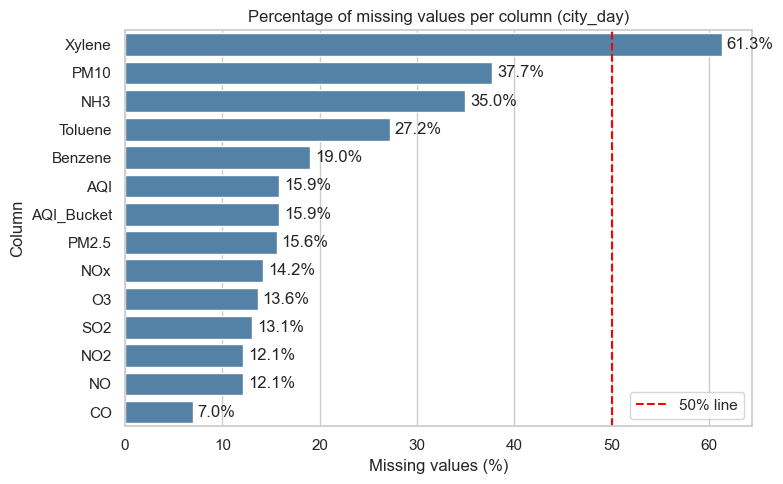

In [6]:
miss = (city.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
plt.figure(figsize=(8,5))
sns.barplot(x=miss.values, y=miss.index, color='steelblue')
plt.axvline(50, color='red', ls='--', label='50% line')
for i, v in enumerate(miss.values):
    plt.text(v + 0.5, i, f'{v:.1f}%', va='center')
plt.xlabel('Missing values (%)'); plt.ylabel('Column')
plt.title('Percentage of missing values per column (city_day)')
plt.legend(); plt.tight_layout(); plt.show()

**Why:** Missing data is the biggest problem in most real datasets. We must know *how much* is missing in each column before deciding what to do.
**What it shows:** **Xylene** is missing for about 61% of rows (over the 50% line), **PM10** for about 38% and **NH3** for about 35%. AQI and AQI_Bucket are missing for about 16% of rows. Other pollutants are missing 7–27% (Toluene is the highest of these).

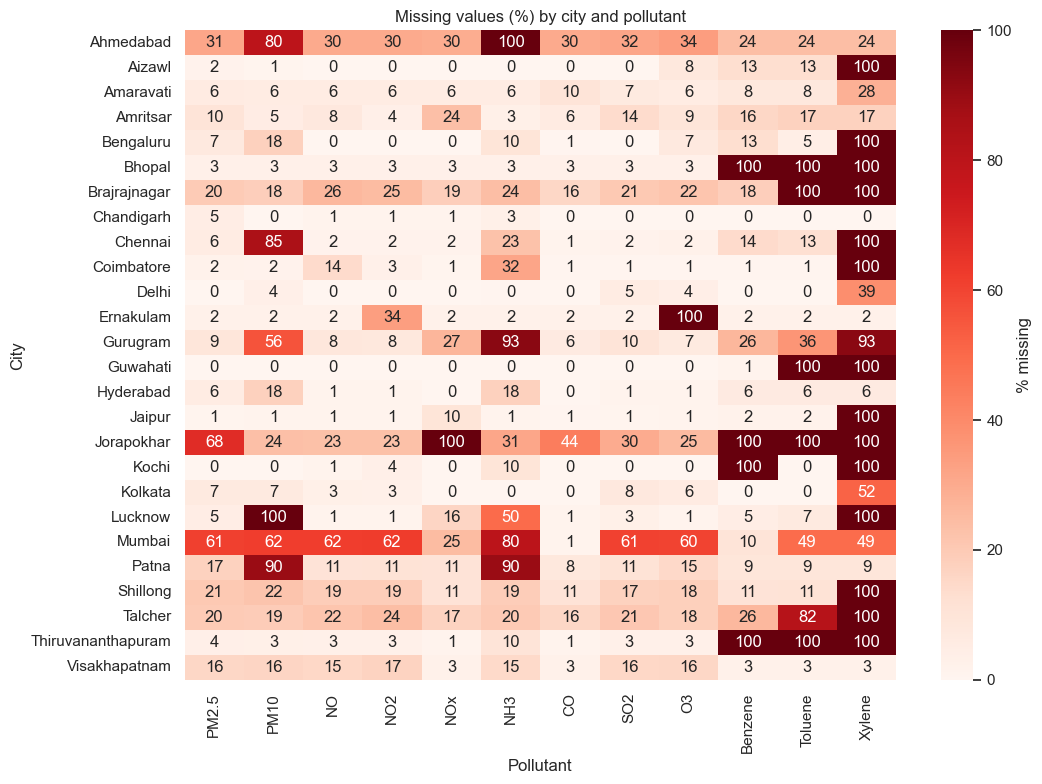

In [7]:
miss_city = city.groupby('City')[POLL].apply(lambda x: x.isna().mean() * 100)
plt.figure(figsize=(11,8))
sns.heatmap(miss_city, annot=True, fmt='.0f', cmap='Reds', cbar_kws={'label': '% missing'})
plt.title('Missing values (%) by city and pollutant')
plt.xlabel('Pollutant'); plt.ylabel('City')
plt.tight_layout(); plt.show()

**Why:** Missing values are not always random. If a whole city never measures a pollutant, we need a different fix than for random gaps.
**What it shows:** The gaps are **grouped by city**. 14 of the 26 cities have 100% missing Xylene, and a few cities do not report PM10, NH3, Benzene or Toluene at all. So the missing values come from **stations that do not have that sensor**, not from random errors. This is why we cannot simply fill with one overall average.

## A5. Data quality checks (do the values make sense?)

In [8]:
d = city.dropna(subset=['AQI'])

# 1. Does AQI_Bucket match the AQI number?
bins = [-1, 50, 100, 200, 300, 400, 1e6]
expected = pd.cut(d['AQI'], bins, labels=BUCKETS).astype(str)
print('1. AQI_Bucket not matching AQI :', (expected != d['AQI_Bucket']).sum())

# 2. PM2.5 is a part of PM10, so PM2.5 should not be larger than PM10
both = city.dropna(subset=['PM2.5','PM10'])
bad_pm = (both['PM2.5'] > both['PM10']).sum()
print(f'2. PM2.5 > PM10 (impossible)    : {bad_pm} of {len(both)} rows ({bad_pm/len(both)*100:.1f}%)')

# 3. Negative values
print('3. Negative pollutant values    :', (city[POLL] < 0).sum().sum())

# 4. Very high CO (normal city air is usually below 10 mg/m3)
print('4. Rows with CO > 50            :', (city['CO'] > 50).sum(), '->', city.loc[city['CO'] > 50, 'City'].unique())

1. AQI_Bucket not matching AQI : 0
2. PM2.5 > PM10 (impossible)    : 256 of 17632 rows (1.5%)
3. Negative pollutant values    : 0
4. Rows with CO > 50            : 120 -> <ArrowStringArray>
['Ahmedabad']
Length: 1, dtype: str


**Why:** A value can be present and still be wrong. These checks find impossible or suspicious values before we use the data.
**What it shows:**
1. AQI_Bucket always matches AQI, so the label column is reliable.
2. About 1.5% of rows (256) have PM2.5 higher than PM10, a consistency anomaly worth checking against measurement and reporting rules. We will **flag** these rows rather than assume the cause or delete them.
3. There are no negative values.
4. CO above 50 appears **only in Ahmedabad**. This is a red flag and we look at it again in the outlier step.

## A6. Cleaning decisions

**Our 3 cleaning decisions and why:**
1. **Drop rows where AQI is missing.** AQI is the main thing we want to study and predict later. Filling a target value with a guess would create fake answers.
2. **Drop the Xylene column.** About 61% is missing and 14 of 26 cities never measure it. Filling it would be mostly invented data.
3. **Fill the remaining missing pollutants with the median of the same city and same month.** Pollution depends strongly on city and season, so this is more realistic than one overall average. The median is used because it is not affected by extreme values. If a city-month has no data at all, we use the median of that month across all cities.

In [9]:
df = city.copy()

# flag impossible PM values BEFORE imputation (so we do not hide the problem)
df['PM_inconsistent'] = df['PM2.5'] > df['PM10']

# Decision 1: drop rows without AQI
before = len(df)
df = df.dropna(subset=['AQI']).copy()
print(f'Rows dropped (AQI missing): {before - len(df)}  ->  {len(df)} rows remain')

# Decision 2: drop Xylene
df = df.drop(columns=['Xylene'])
POLL_USED = [c for c in POLL if c != 'Xylene']

# month is needed for the imputation step
df['Month'] = df['Date'].dt.month
raw_pm10 = df['PM10'].copy()          # keep a copy to compare later

# Decision 3: fill with city-month median, then month median
for col in POLL_USED:
    df[col] = df[col].fillna(df.groupby(['City','Month'])[col].transform('median'))
    df[col] = df[col].fillna(df.groupby('Month')[col].transform('median'))

print('Missing values left:', df[POLL_USED + ['AQI']].isna().sum().sum())

Rows dropped (AQI missing): 4681  ->  24850 rows remain
Missing values left: 0


**Why:** Most ML models and many statistics cannot work with empty cells, so every missing value must be handled.
**What it shows:** About 4,700 rows without AQI were removed, leaving **24,850 rows**. After filling, **no missing values remain** in the pollutants or AQI.

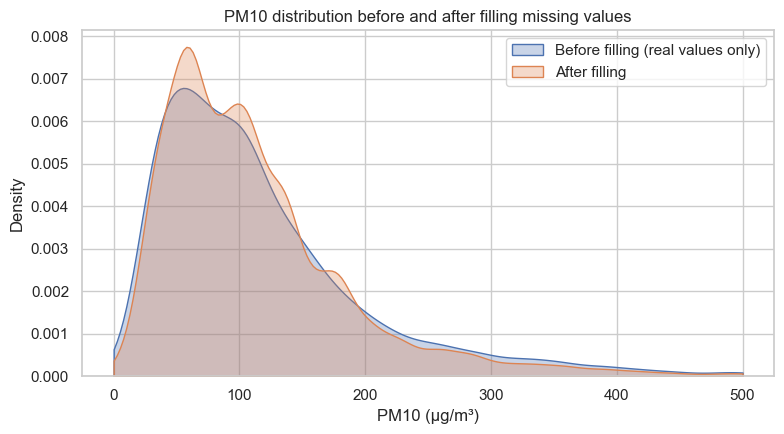

In [10]:
plt.figure(figsize=(8,4.5))
sns.kdeplot(raw_pm10.dropna(), label='Before filling (real values only)', fill=True, alpha=0.3, clip=(0, 500))
sns.kdeplot(df['PM10'], label='After filling', fill=True, alpha=0.3, clip=(0, 500))
plt.xlabel('PM10 (µg/m³)'); plt.ylabel('Density')
plt.title('PM10 distribution before and after filling missing values')
plt.legend(); plt.tight_layout(); plt.show()

**Why:** Filling values should not change the data's overall shape. We check this on PM10, which had the most missing values among the pollutants we kept.
**What it shows:** The two curves have a very similar overall shape and peak, so the filling did **not change the data's pattern**. The filled curve is a little more peaked (many days got the same median value) and has a slightly thinner right tail, so the very extreme PM10 days are under-represented. This is the cost of filling.

## A7. Outliers

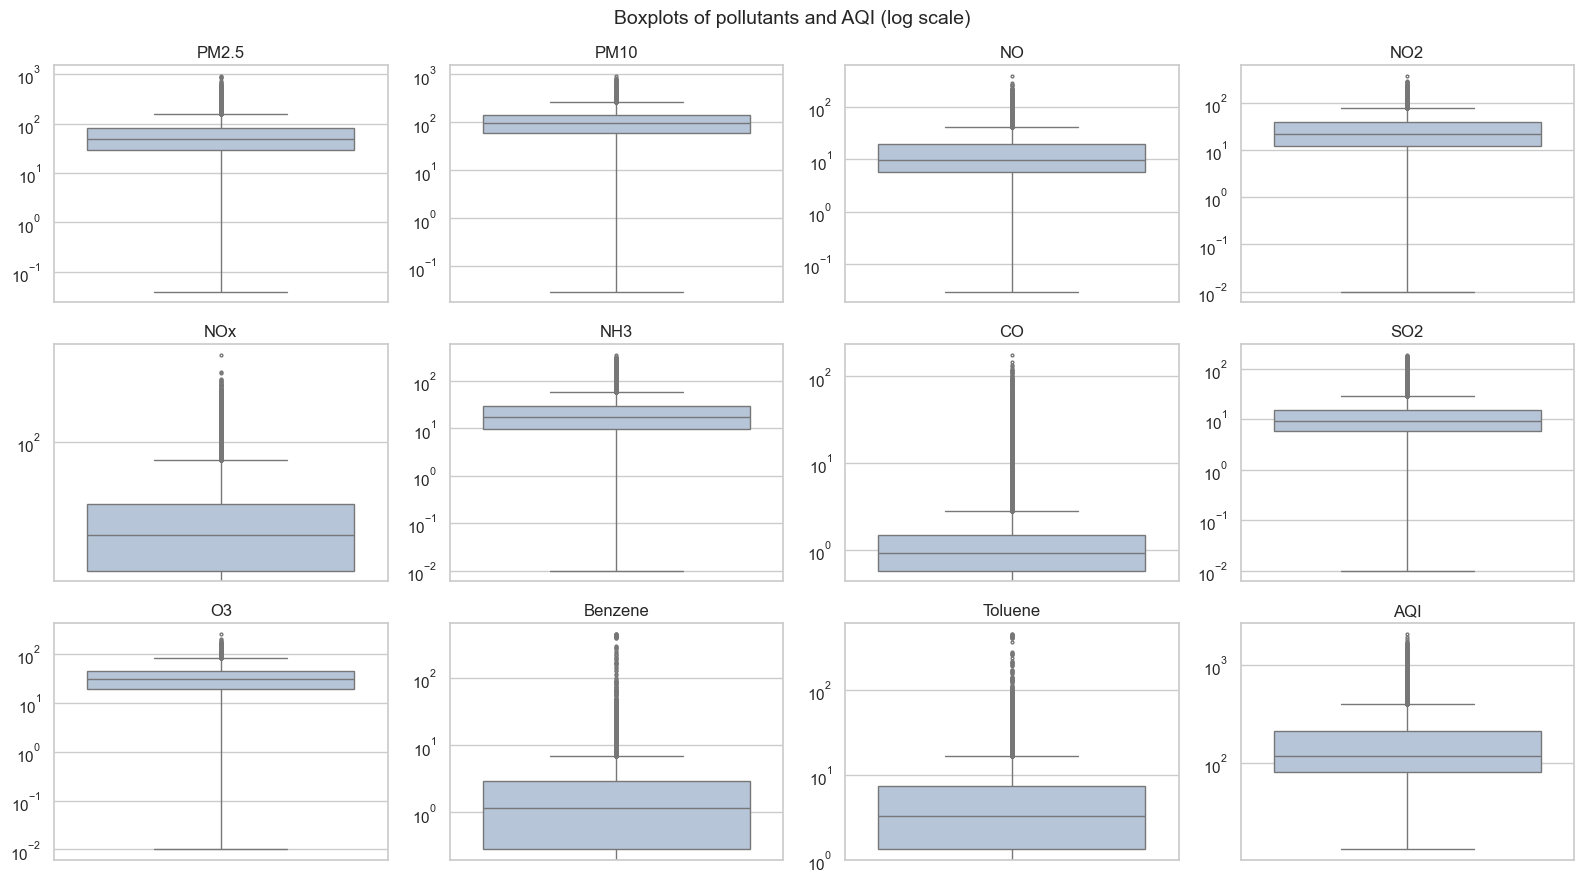

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), POLL_USED + ['AQI']):
    sns.boxplot(y=df[col], ax=ax, color='lightsteelblue', flierprops=dict(markersize=2))
    ax.set_yscale('log'); ax.set_title(col); ax.set_ylabel('')
fig.suptitle('Boxplots of pollutants and AQI (log scale)', fontsize=14)
plt.tight_layout(); plt.show()

**Why:** Outliers (very high or very low values) can ruin averages and ML models. A boxplot shows them quickly. A log scale is used so that both small and huge values are visible.
**What it shows:** Every pollutant has many points far above the box, which means the data is **right-skewed**: most days are moderate, a few days are extremely polluted.

In [12]:
iqr_tbl = {}
for col in POLL_USED + ['AQI']:
    q1, q3 = df[col].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[col] > q3 + 1.5*iqr) | (df[col] < q1 - 1.5*iqr)).sum()
    iqr_tbl[col] = [n, round(n/len(df)*100, 1)]
pd.DataFrame(iqr_tbl, index=['Outlier count (IQR rule)', 'Outlier %']).T

,Outlier count (IQR rule),Outlier %
PM2.5,1954.0,7.9
PM10,1498.0,6.0
NO,2345.0,9.4
NO2,1103.0,4.4
NOx,1908.0,7.7
NH3,1290.0,5.2
CO,2304.0,9.3
SO2,2490.0,10.0
O3,704.0,2.8
Benzene,1816.0,7.3


**Why:** The IQR rule gives an exact count of outliers instead of just a picture.
**What it shows:** Between about 3% and 13% of values are flagged as outliers, depending on the column. This is too many to be mistakes, so most of them are probably **real pollution events** (e.g. winter smog, Diwali).

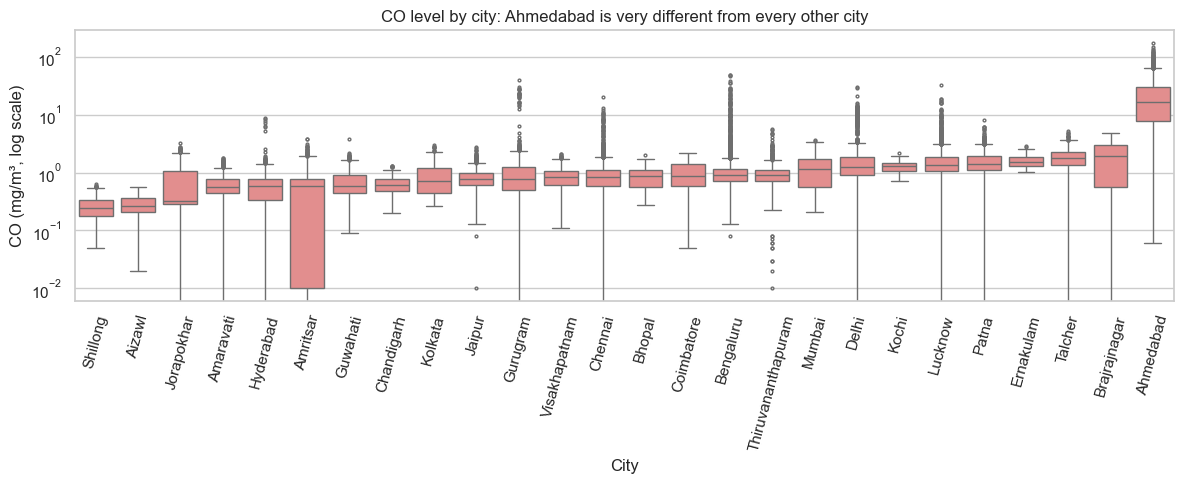

In [13]:
order = df.groupby('City')['CO'].median().sort_values().index
plt.figure(figsize=(12,5))
sns.boxplot(data=df, x='City', y='CO', order=order, color='lightcoral', flierprops=dict(markersize=2))
plt.yscale('log'); plt.xticks(rotation=75)
plt.xlabel('City'); plt.ylabel('CO (mg/m³, log scale)')
plt.title('CO level by city: Ahmedabad is very different from every other city')
plt.tight_layout(); plt.show()

**Why:** Earlier we found CO above 50 only in Ahmedabad. We check whether this is a few bad days or the whole city.
**What it shows:** Ahmedabad's **typical (median) CO is about 16, while other cities are around 1**. So it is not a few errors; the whole Ahmedabad CO record is far higher than the other cities, which may be a measurement or unit problem. AQI depends on the highest pollutant level, so this inflates Ahmedabad's AQI (average about 450 vs about 150 for the rest).

**Decision on outliers:** We **keep** all outliers because most are real pollution events and deleting them would hide the problem we want to study. We only **flag** the Ahmedabad CO issue and the `PM_inconsistent` rows. Later in EDA and in the ML part we will check results **with and without Ahmedabad**, so it does not mislead us.

## A8. Transformation – reduce skewness with log

In [14]:
skew = df[POLL_USED + ['AQI']].skew().round(2)
for col in POLL_USED + ['AQI']:
    df['log_' + col] = np.log1p(df[col])
skew_log = df[['log_' + c for c in POLL_USED + ['AQI']]].skew().round(2)
skew_log.index = skew.index
pd.DataFrame({'Skew (original)': skew, 'Skew (after log)': skew_log})

,Skew (original),Skew (after log)
PM2.5,2.99,0.07
PM10,2.04,-0.47
NO,3.54,0.30
NO2,2.45,-0.36
NOx,2.51,-0.77
NH3,4.33,-0.19
CO,8.69,2.67
SO2,3.93,0.65
O3,1.34,-0.98
Benzene,23.24,1.25


**Why:** Skewed data breaks the assumptions of many statistical tests and models. A log transform (`log1p`) pulls the long right tail in.
**What it shows:** Original skewness is high for most columns (above 2 for most, and extreme for CO at 8.7 and Benzene at 23). After the log transform it falls to between -1 and 1 for almost all columns, so the data is much more balanced. CO (2.7) and Benzene (1.3) are still skewed, mainly because of the Ahmedabad values. We keep both versions: the original for easy reading and the `log_` version for tests and models.

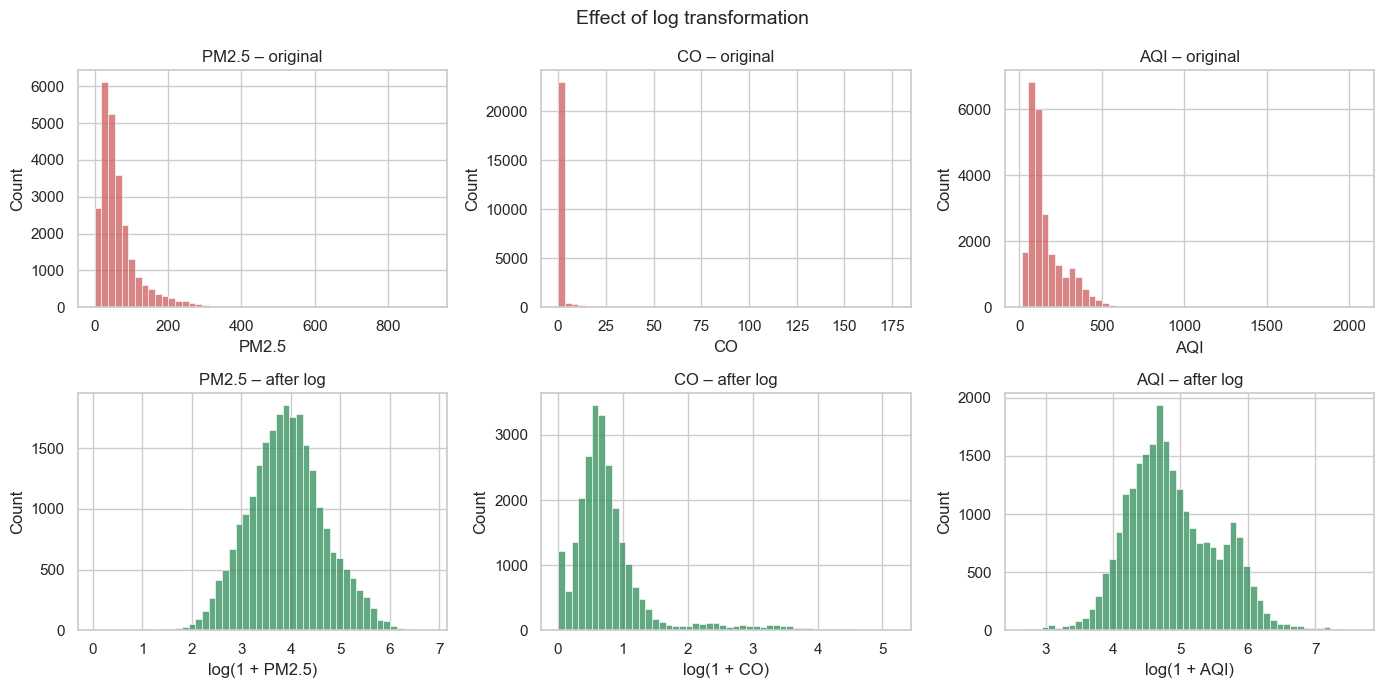

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for j, col in enumerate(['PM2.5', 'CO', 'AQI']):
    sns.histplot(df[col], bins=50, ax=axes[0, j], color='indianred'); axes[0, j].set_title(f'{col} – original')
    sns.histplot(df['log_' + col], bins=50, ax=axes[1, j], color='seagreen'); axes[1, j].set_title(f'{col} – after log')
    axes[0, j].set_xlabel(col); axes[1, j].set_xlabel('log(1 + ' + col + ')')
plt.suptitle('Effect of log transformation', fontsize=14)
plt.tight_layout(); plt.show()

**Why:** A picture proves the log transform worked.
**What it shows:** The top row has a tall spike near zero and a very long tail. The bottom row is a smooth, roughly bell-shaped curve. The log version is better for statistics and modelling.

## A9. Feature engineering (new useful columns)

In [16]:
df['Year']      = df['Date'].dt.year
df['DayOfWeek'] = df['Date'].dt.day_name()
df['IsWeekend'] = df['Date'].dt.dayofweek >= 5

def season(m):
    if m in (12, 1, 2): return 'Winter'
    if m in (3, 4, 5):  return 'Summer'
    if m in (6, 7, 8, 9): return 'Monsoon'
    return 'Post-Monsoon'
df['Season'] = df['Month'].apply(season)

# COVID-19 lockdown in India started on 25 March 2020
df['Lockdown'] = np.where(df['Date'] >= '2020-03-25', 'Lockdown', 'Before lockdown')

# State from stations.csv
city_state = stations.drop_duplicates('City').set_index('City')['State']
df['State'] = df['City'].map(city_state)

region = {
 'North': ['Delhi','Gurugram','Chandigarh','Amritsar','Jaipur','Lucknow'],
 'South': ['Bengaluru','Chennai','Hyderabad','Amaravati','Visakhapatnam','Coimbatore','Thiruvananthapuram','Ernakulam','Kochi'],
 'East': ['Kolkata','Patna','Jorapokhar','Brajrajnagar','Talcher'],
 'West': ['Ahmedabad','Mumbai'],
 'Central': ['Bhopal'],
 'North-East': ['Guwahati','Shillong','Aizawl']}
city_region = {c: r for r, cs in region.items() for c in cs}
df['Region'] = df['City'].map(city_region)

df = df.sort_values(['City', 'Date']).reset_index(drop=True)
print('Cities without State :', df['State'].isna().sum(), '| without Region:', df['Region'].isna().sum())
df[['City','Date','Year','Month','Season','Region','State','Lockdown','AQI','AQI_Bucket']].head()

Cities without State : 0 | without Region: 0


,City,Date,Year,Month,Season,Region,State,Lockdown,AQI,AQI_Bucket
0,Ahmedabad,2015-01-29,2015,1,Winter,West,Gujarat,Before lockdown,209.0,Poor
1,Ahmedabad,2015-01-30,2015,1,Winter,West,Gujarat,Before lockdown,328.0,Very Poor
2,Ahmedabad,2015-01-31,2015,1,Winter,West,Gujarat,Before lockdown,514.0,Severe
3,Ahmedabad,2015-02-01,2015,2,Winter,West,Gujarat,Before lockdown,782.0,Severe
4,Ahmedabad,2015-02-02,2015,2,Winter,West,Gujarat,Before lockdown,914.0,Severe


**Why:** The raw file only has a date and a city. Pollution depends on **season, year, region and special events**, so we create these columns to be able to study them.
**What it shows:** We added Year, Month, Season (Indian seasons), Weekend flag, Lockdown flag (from 25 Mar 2020), State and Region. Every city got a State and Region (0 missing).

## A10. Station data – merge and clean

In [17]:
sd = station.merge(stations, on='StationId', how='left')
print('Stations in station_day :', station['StationId'].nunique())
print('Stations with no match in stations.csv :', sd['StationName'].isna().sum(), 'rows')
print('Rows without AQI :', sd['AQI'].isna().sum(), f"({sd['AQI'].isna().mean()*100:.1f}%)")
sd = sd.dropna(subset=['AQI']).copy()
sd['Year'] = sd['Date'].dt.year
print('Station rows after dropping missing AQI :', len(sd))

Stations in station_day : 110
Stations with no match in stations.csv : 0 rows
Rows without AQI : 21010 (19.4%)
Station rows after dropping missing AQI : 87025


**Why:** `station_day.csv` only has station codes. Joining it with `stations.csv` gives each reading a city and state, so we can compare states later. We drop rows with missing AQI for the same reason as before.
**What it shows:** Every station code matched (no unmatched rows). About 19% of station rows have no AQI and are dropped. We use this file only for state-level views, and `city_day` stays the main dataset.

## A11. Save the clean data

In [18]:
df.to_csv('city_day_clean.csv', index=False)
sd.to_csv('station_day_clean.csv', index=False)
print('Clean city data   :', df.shape)
print('Clean station data:', sd.shape)
print('Missing values in clean city data:', df[POLL_USED + ['AQI']].isna().sum().sum())

Clean city data   : (24850, 36)
Clean station data: (87025, 21)
Missing values in clean city data: 0


**Why:** Saving the clean files lets the next parts (hypothesis testing, ML, Power BI/Tableau) start from clean data without repeating these steps.
**What it shows:** The final city dataset has about 24,850 rows and 0 missing values in pollutants and AQI.

# PART B – EXPLORATORY DATA ANALYSIS (EDA)

## B1. Summary statistics

In [19]:
stats = df[POLL_USED + ['AQI']].describe().T.round(2)
stats['skew'] = df[POLL_USED + ['AQI']].skew().round(2)
stats

,count,mean,std,min,25%,50%,75%,max,skew
PM2.5,24850.0,66.85,62.45,0.04,28.94,48.40,80.26,914.94,2.99
PM10,24850.0,113.84,80.94,0.03,59.01,95.26,139.31,917.08,2.04
NO,24850.0,17.57,22.28,0.03,5.70,9.94,20.04,390.68,3.54
NO2,24850.0,28.78,24.52,0.01,11.87,21.91,37.98,362.21,2.45
NOx,24850.0,31.77,29.69,0.00,13.81,23.79,38.37,378.24,2.51
NH3,24850.0,23.06,23.30,0.01,9.94,17.48,29.19,352.89,4.33
CO,24850.0,2.32,7.02,0.00,0.58,0.93,1.47,175.81,8.69
SO2,24850.0,14.42,17.39,0.01,5.77,9.26,15.16,186.08,3.93
O3,24850.0,34.71,21.52,0.01,19.25,31.08,45.66,257.73,1.34
Benzene,24850.0,3.14,14.88,0.00,0.28,1.16,2.94,455.03,23.24


**Why:** Summary statistics give a quick numeric picture of each column: centre, spread and extremes.
**What it shows:** For every pollutant the **mean is higher than the median** and the maximum is far above the 75th percentile. This again says a few very polluted days pull the average up. The average AQI is about 166 (Moderate), but the median is lower (about 118), so the **median is a fairer 'typical day'** than the mean.

## B2. Univariate analysis (one column at a time)

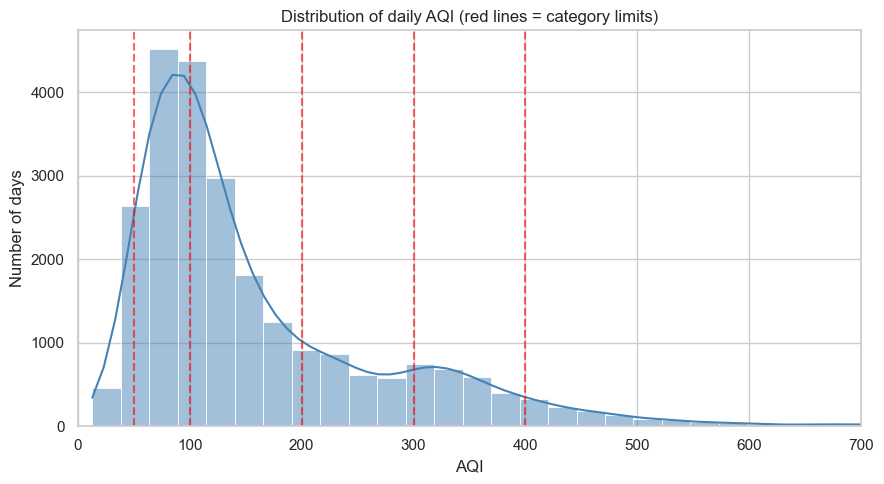

Days with AQI above 700 (not shown): 216


In [20]:
plt.figure(figsize=(9,5))
sns.histplot(df['AQI'], bins=80, kde=True, color='steelblue')
for x in [50, 100, 200, 300, 400]:
    plt.axvline(x, color='red', ls='--', alpha=.6)
plt.xlim(0, 700)
plt.xlabel('AQI'); plt.ylabel('Number of days')
plt.title('Distribution of daily AQI (red lines = category limits)')
plt.tight_layout(); plt.show()
print('Days with AQI above 700 (not shown):', (df['AQI'] > 700).sum())

**Why:** AQI is our main variable, so we must understand its shape first.
**What it shows:** Most days fall between 50 and 200 (Satisfactory to Moderate). The curve has a **long tail to the right**: a smaller number of days go above 300 and some above 500. There are no very clean days; very few days are below 50.

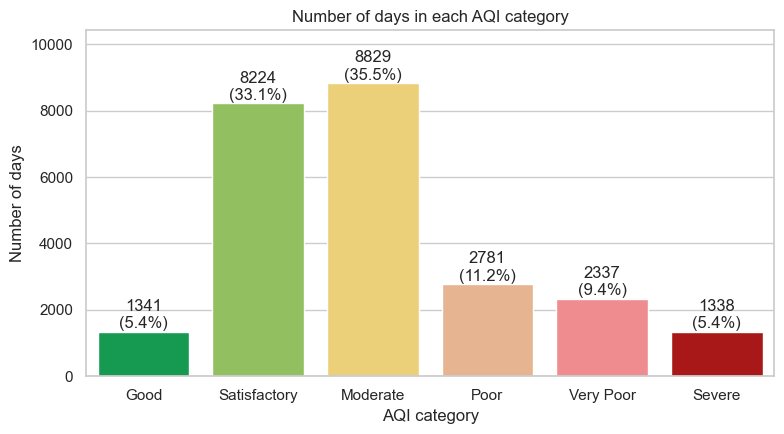

In [21]:
cnt = df['AQI_Bucket'].value_counts().reindex(BUCKETS)
colors = ['#00b050','#92d050','#ffd966','#f4b183','#ff7c80','#c00000']
plt.figure(figsize=(8,4.5))
ax = sns.barplot(x=cnt.index, y=cnt.values, palette=colors)
for i, v in enumerate(cnt.values):
    ax.text(i, v + 100, f'{v}\n({v/len(df)*100:.1f}%)', ha='center')
plt.xlabel('AQI category'); plt.ylabel('Number of days')
plt.title('Number of days in each AQI category')
plt.ylim(0, cnt.max() * 1.18); plt.tight_layout(); plt.show()

**Why:** The government groups AQI into health categories. Counting days in each category is easier to understand than raw numbers, and it shows if the classes are balanced (important if we classify later).
**What it shows:** **Moderate (35%)** and **Satisfactory (33%)** are the biggest groups. Only about 5% of days are Good, while about 15% are Very Poor or Severe. The classes are **not equal in size**, so accuracy alone would be misleading if we build a classifier later.

## B3. Bivariate analysis (two columns together)

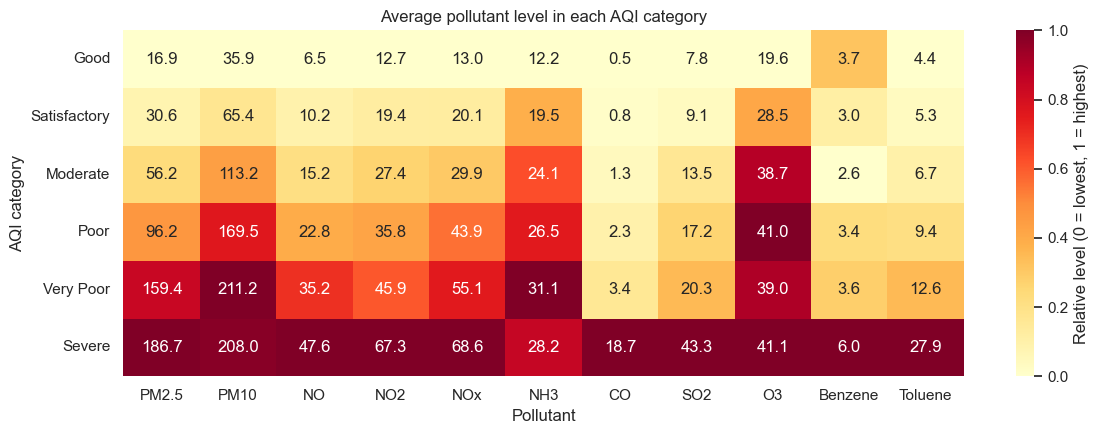

In [22]:
profile = df.groupby('AQI_Bucket')[POLL_USED].mean().reindex(BUCKETS)
scaled = (profile - profile.min()) / (profile.max() - profile.min())
plt.figure(figsize=(12,4.5))
sns.heatmap(scaled, annot=profile.round(1), fmt='', cmap='YlOrRd', cbar_kws={'label': 'Relative level (0 = lowest, 1 = highest)'})
plt.xlabel('Pollutant'); plt.ylabel('AQI category')
plt.title('Average pollutant level in each AQI category')
plt.tight_layout(); plt.show()

**Why:** This tells us which pollutants go up when air gets worse. Numbers in the boxes are real averages; colours are scaled so each column can be compared.
**What it shows:** **PM2.5 rises steadily** from 17 (Good) to 187 (Severe), and PM10 rises up to Very Poor. NO, NO2 and NOx also go up with worse air. **CO stays low (0.5–3.4) until the Severe group, where it suddenly jumps to 18.7**; this jump is caused by Ahmedabad, not by all cities. Benzene and O3 do not follow AQI in a clear way.

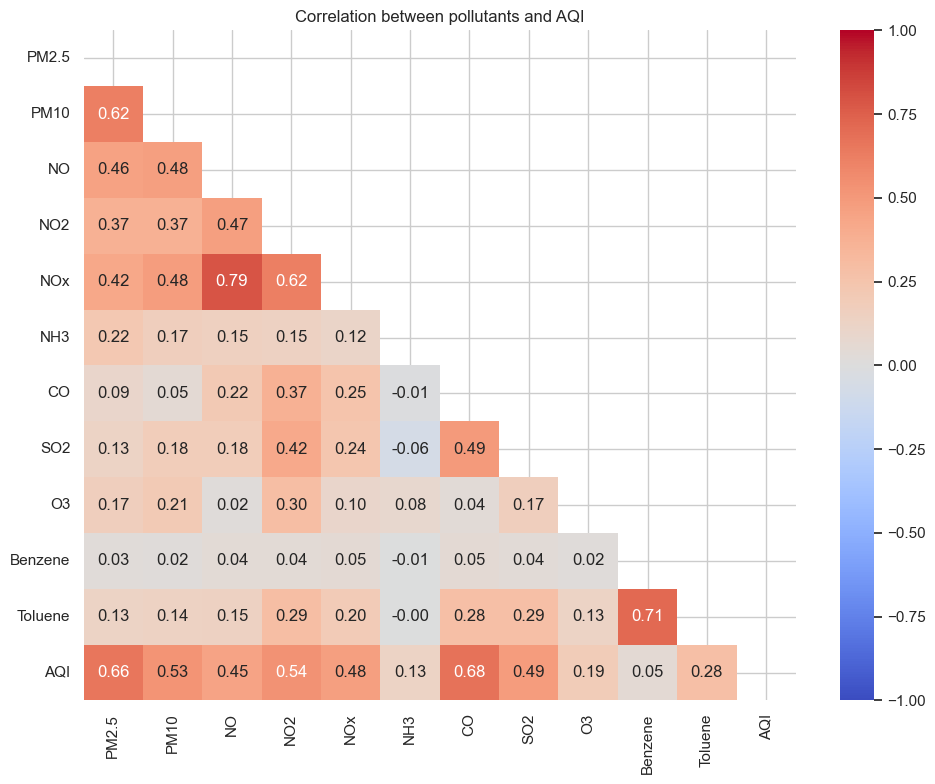

In [23]:
corr = df[POLL_USED + ['AQI']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10,8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation between pollutants and AQI')
plt.tight_layout(); plt.show()

**Why:** Correlation shows which pollutants move with AQI (useful for choosing features) and which move with each other (a problem called multicollinearity for regression).
**What it shows:** AQI is most correlated with **CO (0.68) and PM2.5 (0.66)**, then NO2, PM10, SO2 and NOx (about 0.5). O3 (0.19), NH3 (0.13) and Benzene (0.05) are weak. **NOx moves closely with NO and NO2** (NOx is made from them), and PM2.5 moves with PM10, so using all of them together in a regression would repeat the same information. We should select features carefully later. The next chart checks if these numbers are reliable.

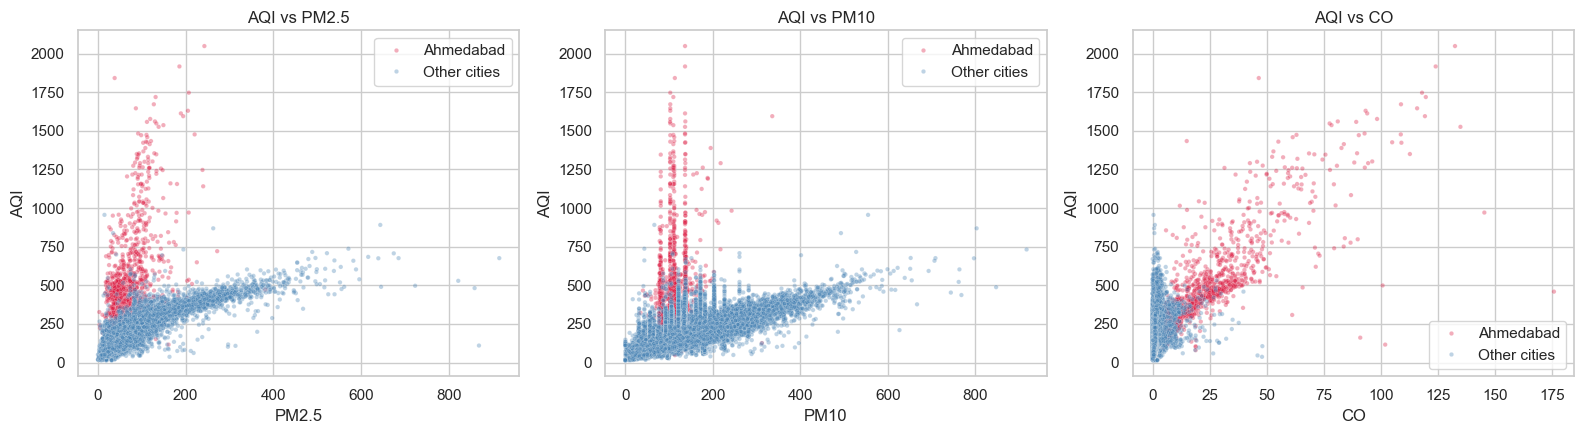

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
is_ahd = np.where(df['City'] == 'Ahmedabad', 'Ahmedabad', 'Other cities')
for ax, col in zip(axes, ['PM2.5', 'PM10', 'CO']):
    sns.scatterplot(x=df[col], y=df['AQI'], hue=is_ahd, alpha=.35, s=10, ax=ax,
                    palette={'Ahmedabad': 'crimson', 'Other cities': 'steelblue'})
    ax.set_xlabel(col); ax.set_ylabel('AQI'); ax.set_title(f'AQI vs {col}')
plt.tight_layout(); plt.show()

**Why:** Correlation is one number; a scatter plot shows the real shape of the relationship and whether one group behaves differently.
**What it shows:** For the other cities (blue), AQI rises in an almost straight line with PM2.5 and PM10, so these are strong, clean relationships. **Ahmedabad (red) sits far above this line**: its AQI is very high even when PM is moderate, and in the CO plot it forms its own rising cloud. This confirms Ahmedabad behaves differently and should be handled separately. The vertical stripes in the PM10 plot are rows where PM10 was filled with the same median value (a side effect of filling).

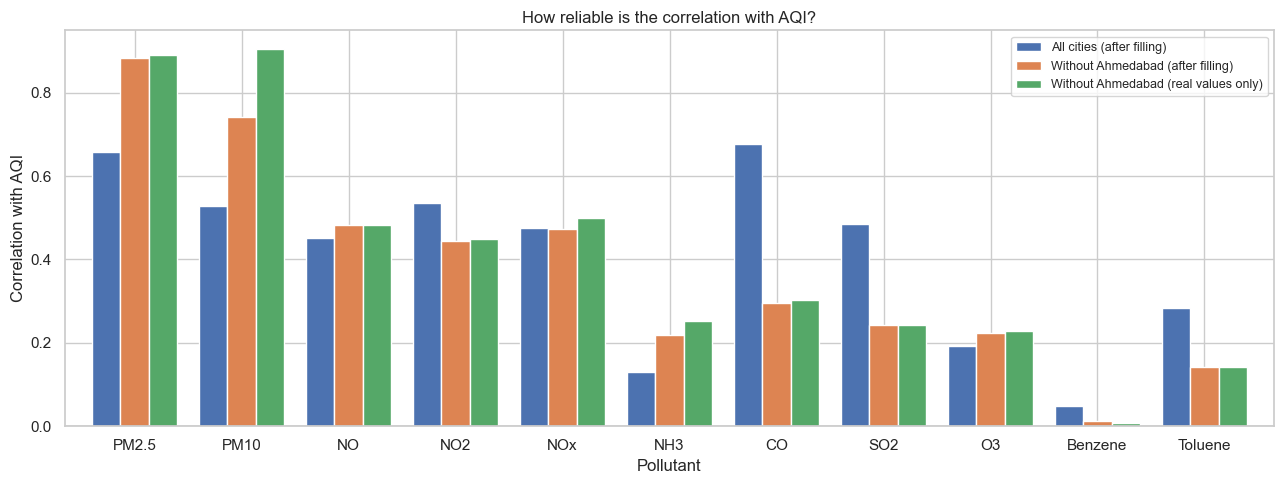

,All cities (after filling),Without Ahmedabad (after filling),Without Ahmedabad (real values only)
PM2.5,0.66,0.88,0.89
PM10,0.53,0.74,0.90
NO,0.45,0.48,0.48
NO2,0.54,0.44,0.45
NOx,0.48,0.47,0.50
NH3,0.13,0.22,0.25
CO,0.68,0.30,0.30
SO2,0.49,0.24,0.24
O3,0.19,0.22,0.23
Benzene,0.05,0.01,0.01


In [25]:
raw = city.dropna(subset=['AQI'])
cmp = pd.DataFrame({
    'All cities (after filling)':           df[POLL_USED + ['AQI']].corr()['AQI'],
    'Without Ahmedabad (after filling)':    df[df['City'] != 'Ahmedabad'][POLL_USED + ['AQI']].corr()['AQI'],
    'Without Ahmedabad (real values only)': raw[raw['City'] != 'Ahmedabad'][POLL_USED + ['AQI']].corr()['AQI'],
}).drop('AQI')
cmp.plot(kind='bar', figsize=(13,5), width=.8)
plt.axhline(0, color='k', lw=.8)
plt.ylabel('Correlation with AQI'); plt.xlabel('Pollutant'); plt.xticks(rotation=0)
plt.title('How reliable is the correlation with AQI?')
plt.legend(loc='upper right', fontsize=9); plt.tight_layout(); plt.show()
cmp.round(2)

**Why:** We should never trust a correlation without checking if it is stable. Here we compare 3 versions: all cities, without Ahmedabad, and without Ahmedabad using only real (not filled) values.
**What it shows:** Two important things. **(1) CO's correlation drops from 0.68 to 0.30 when Ahmedabad is removed**, so CO looked important only because of Ahmedabad. **(2) PM2.5 and PM10 are the true main drivers of AQI** (about 0.89 and 0.90 with real values). Filling the 38% missing PM10 values weakened its correlation from 0.90 to 0.74, which shows how filling can hide a strong relationship.

## B4. Data coverage – is the data balanced?

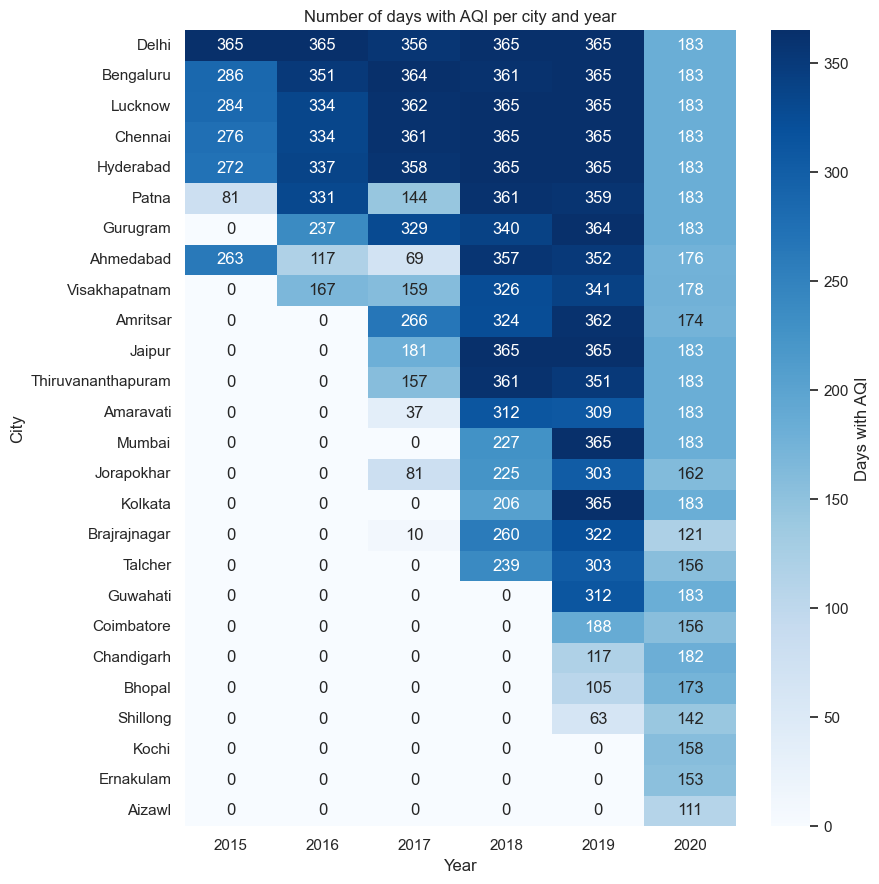

In [26]:
cov = df.pivot_table(index='City', columns='Year', values='AQI', aggfunc='count').fillna(0).astype(int)
cov = cov.loc[cov.sum(axis=1).sort_values(ascending=False).index]
plt.figure(figsize=(9,9))
sns.heatmap(cov, annot=True, fmt='d', cmap='Blues', cbar_kws={'label': 'Days with AQI'})
plt.title('Number of days with AQI per city and year')
plt.xlabel('Year'); plt.ylabel('City')
plt.tight_layout(); plt.show()

**Why:** Before comparing cities or years we must check that each has enough and similar amounts of data. If not, comparisons can be unfair.
**What it shows:** The data is **very unbalanced**. Only a few cities (Delhi, Ahmedabad, Lucknow, Bengaluru, Chennai, Hyderabad) have data from 2015. Many cities start in 2018–2020, and some (Aizawl, Ernakulam, Kochi) have only a few months. Also 2020 has only half a year. So yearly trends must be read carefully.

## B5. City-wise analysis

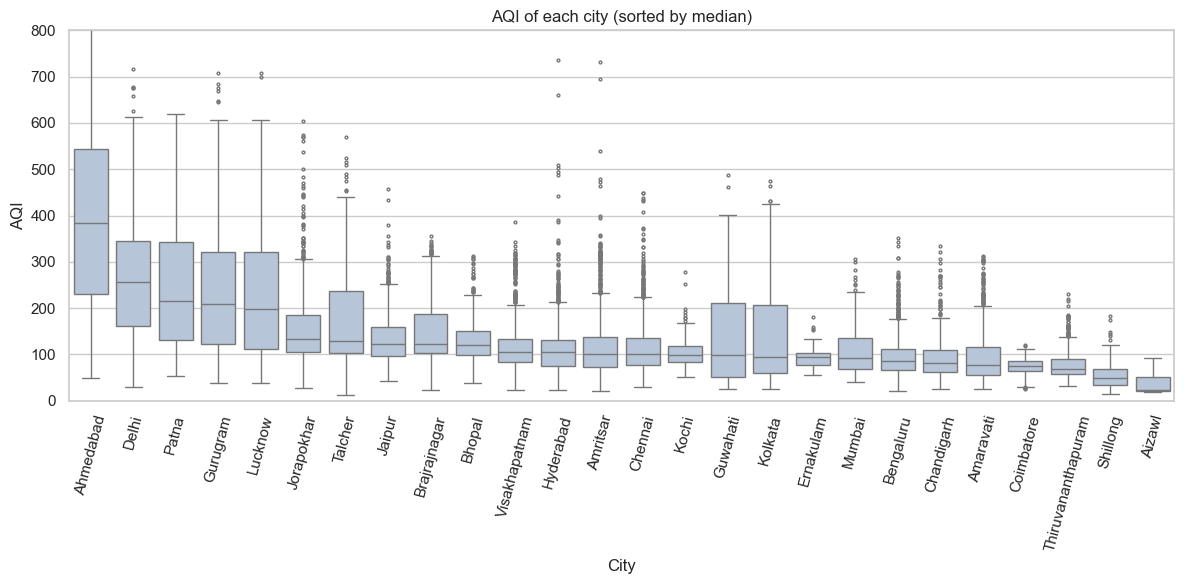

In [27]:
order = df.groupby('City')['AQI'].median().sort_values(ascending=False).index
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x='City', y='AQI', order=order, color='lightsteelblue', flierprops=dict(markersize=2))
plt.ylim(0, 800); plt.xticks(rotation=75)
plt.xlabel('City'); plt.ylabel('AQI')
plt.title('AQI of each city (sorted by median)')
plt.tight_layout(); plt.show()

**Why:** This answers the basic question "which cities are the most polluted?" and also shows how much AQI varies within each city.
**What it shows:** **Ahmedabad** is at the top by a large margin (affected by the CO issue). After it, **Delhi, Patna, Gurugram and Lucknow** have the highest AQI. **Aizawl, Shillong, Coimbatore and Thiruvananthapuram** are the cleanest. North Indian cities also have wide boxes, meaning their air quality changes a lot from day to day.

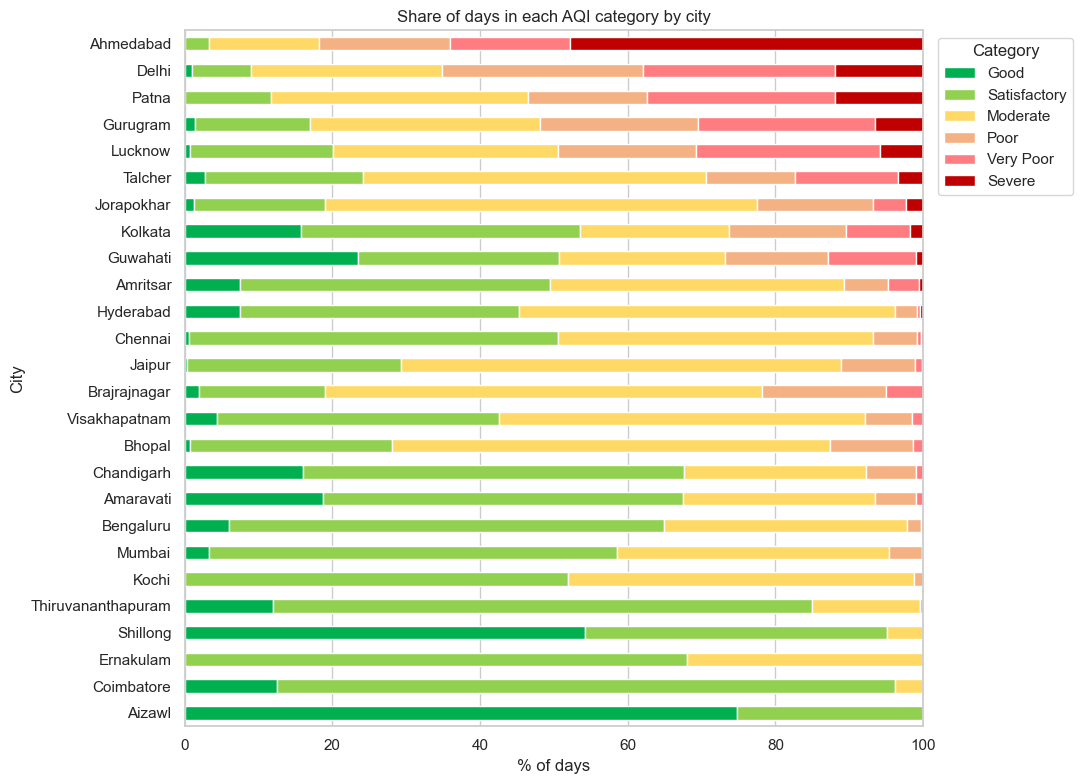

In [28]:
share = pd.crosstab(df['City'], df['AQI_Bucket'], normalize='index')[BUCKETS] * 100
share = share.sort_values(['Severe', 'Very Poor', 'Poor'], ascending=True)
share.plot(kind='barh', stacked=True, figsize=(11,8), color=colors)
plt.xlabel('% of days'); plt.ylabel('City')
plt.title('Share of days in each AQI category by city')
plt.legend(title='Category', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()

**Why:** An average can hide how often a city has dangerous days. This chart shows the share of days in each category.
**What it shows:** Ahmedabad is mostly Severe. Delhi, Patna, Gurugram and Lucknow have a large share of Poor, Very Poor and Severe days. Southern and north-eastern cities are almost entirely Good or Satisfactory.

## B6. Time-based analysis

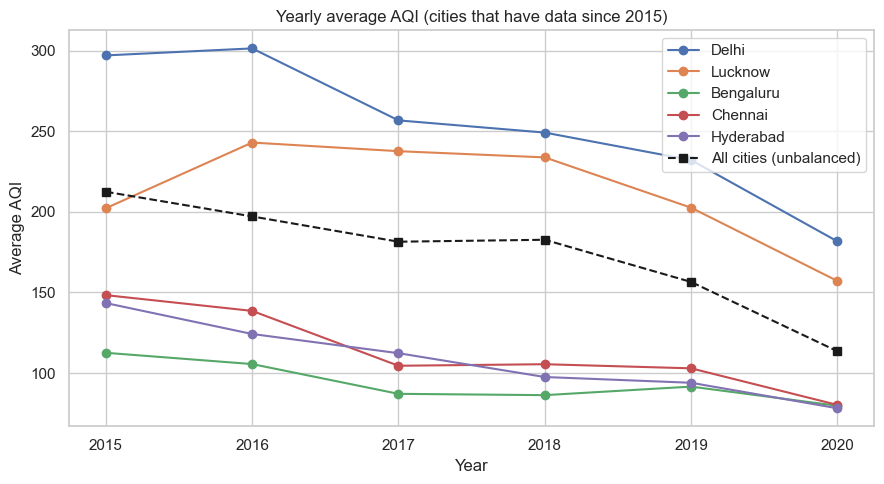

In [29]:
top5 = ['Delhi', 'Lucknow', 'Bengaluru', 'Chennai', 'Hyderabad']
yr = df[df['City'].isin(top5)].pivot_table(index='Year', columns='City', values='AQI', aggfunc='mean')
plt.figure(figsize=(9,5))
for c in top5:
    plt.plot(yr.index, yr[c], marker='o', label=c)
plt.plot(df.groupby('Year')['AQI'].mean(), 'k--', marker='s', label='All cities (unbalanced)')
plt.xlabel('Year'); plt.ylabel('Average AQI')
plt.title('Yearly average AQI (cities that have data since 2015)')
plt.legend(); plt.tight_layout(); plt.show()

**Why:** We want to know if air quality is getting better or worse over time. We use cities with data from the start so the comparison is fair. The black line (all cities) is shown only for comparison, because the set of cities changes every year.
**What it shows:** Delhi and Lucknow stay at a high level but slowly improve after 2016 (Delhi falls from about 300 to about 180), while Bengaluru, Chennai and Hyderabad are much lower and also fall. The **all-cities line falls sharply**, but part of this fall is only because many clean southern/north-eastern cities were added later. 2020 is lower for most cities.

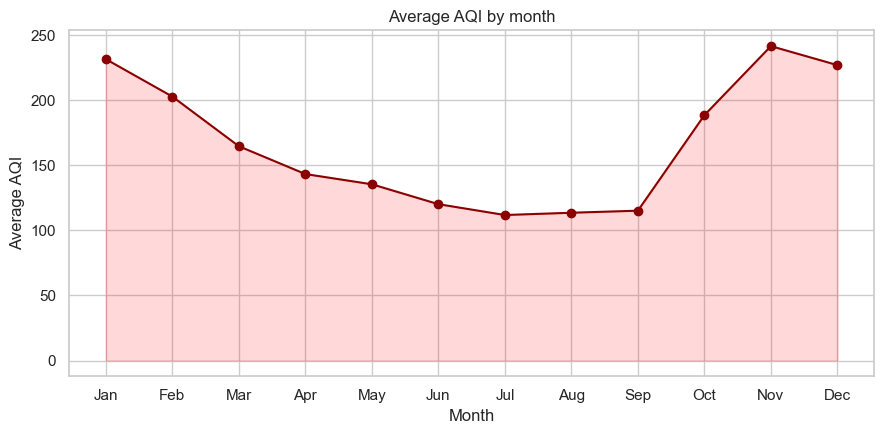

In [30]:
m = df.groupby('Month')['AQI'].mean()
plt.figure(figsize=(9,4.5))
plt.plot(m.index, m.values, marker='o', color='darkred')
plt.fill_between(m.index, m.values, alpha=.15, color='red')
plt.xticks(range(1,13), ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
plt.xlabel('Month'); plt.ylabel('Average AQI')
plt.title('Average AQI by month')
plt.tight_layout(); plt.show()

**Why:** Pollution usually follows the weather, so we check the monthly pattern.
**What it shows:** A clear **U-shape**: AQI is highest in **November (about 240), December and January** and lowest in **July–September (about 112–115)**. Rain in the monsoon washes pollutants out of the air; in winter, cold air traps them near the ground, and crop burning and Diwali add more.

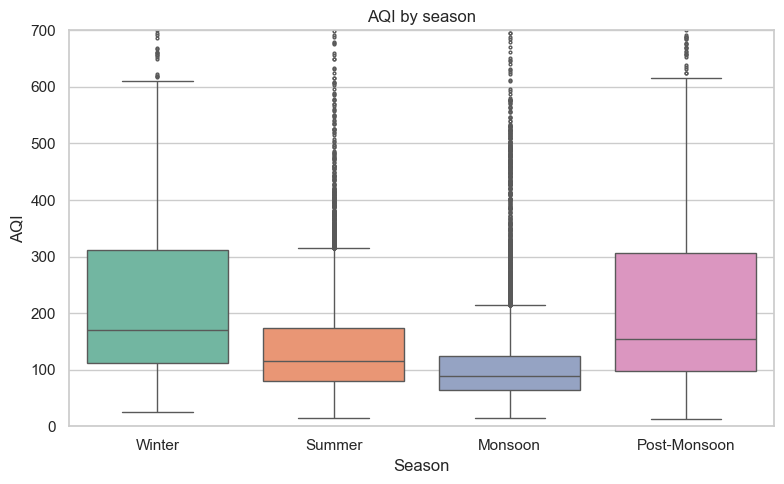

               mean  median
Season                     
Winter        221.0   171.0
Summer        148.0   115.0
Monsoon       116.0    89.0
Post-Monsoon  215.0   154.0


In [31]:
order_s = ['Winter', 'Summer', 'Monsoon', 'Post-Monsoon']
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Season', y='AQI', order=order_s, palette='Set2', flierprops=dict(markersize=2))
plt.ylim(0, 700)
plt.xlabel('Season'); plt.ylabel('AQI')
plt.title('AQI by season')
plt.tight_layout(); plt.show()
print(df.groupby('Season')['AQI'].agg(['mean','median']).round(0).reindex(order_s))

**Why:** Grouping 12 months into 4 seasons makes the comparison simpler and gives us a clean categorical column for hypothesis testing later.
**What it shows:** **Winter (average about 221) and Post-Monsoon (about 215)** have the highest AQI and the widest spread. **Monsoon (about 116)** is the cleanest season with the smallest spread. Season is clearly an important factor.

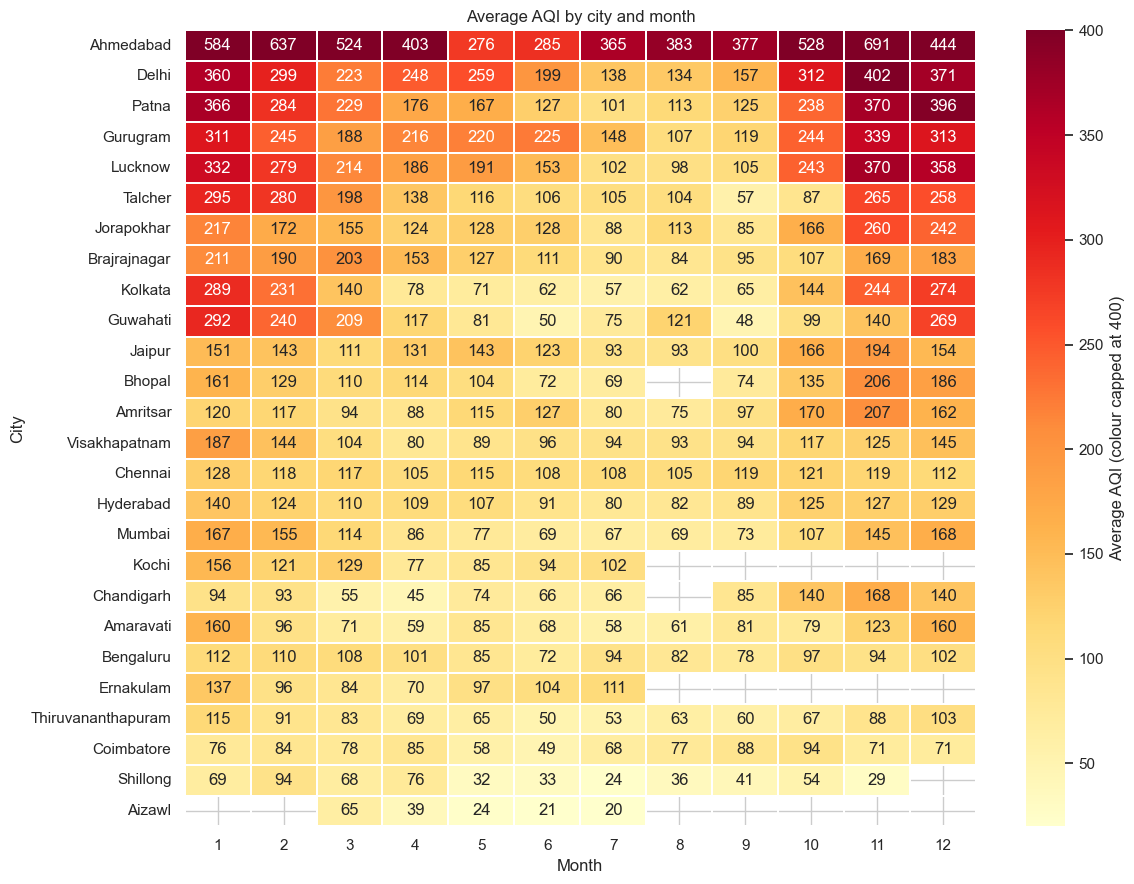

In [32]:
heat = df.pivot_table(index='City', columns='Month', values='AQI', aggfunc='mean')
heat = heat.loc[df.groupby('City')['AQI'].mean().sort_values(ascending=False).index]
plt.figure(figsize=(12,9))
sns.heatmap(heat, cmap='YlOrRd', annot=True, fmt='.0f', linewidths=.3, vmax=400, cbar_kws={'label': 'Average AQI (colour capped at 400)'})
plt.xlabel('Month'); plt.ylabel('City')
plt.title('Average AQI by city and month')
plt.tight_layout(); plt.show()

**Why:** This combines the two ideas (city and month) to see if the seasonal pattern is the same everywhere.
**What it shows:** Ahmedabad is the darkest city almost all year. Among the others, the north Indian cities (Delhi, Patna, Gurugram, Lucknow) are darkest in **Nov–Jan (about 300–400)** and much lighter in Jul–Sep (about 100–150). Southern and north-eastern cities stay light and fairly flat, mostly below about 130. So **season matters mostly in the north and east**. Empty cells are months where the city has no data.

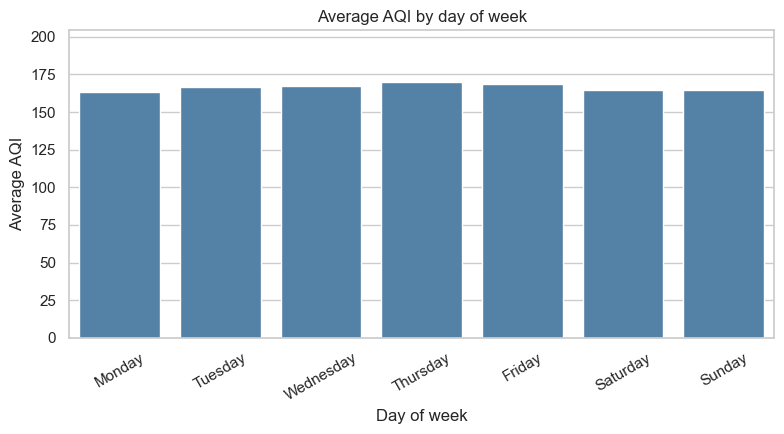

In [33]:
dow = df.groupby('DayOfWeek')['AQI'].mean().reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
plt.figure(figsize=(8,4.5))
sns.barplot(x=dow.index, y=dow.values, color='steelblue')
plt.ylim(0, dow.max() * 1.2); plt.xticks(rotation=30)
plt.xlabel('Day of week'); plt.ylabel('Average AQI')
plt.title('Average AQI by day of week')
plt.tight_layout(); plt.show()

**Why:** We test an idea: is air cleaner on weekends because there is less traffic and industry?
**What it shows:** The bars are almost the same height (average AQI between 164 and 170 on every day). **Day of week has very little effect on AQI.** This is useful because it tells us this feature will probably not help a model, so we can leave it out.

## B7. Region analysis

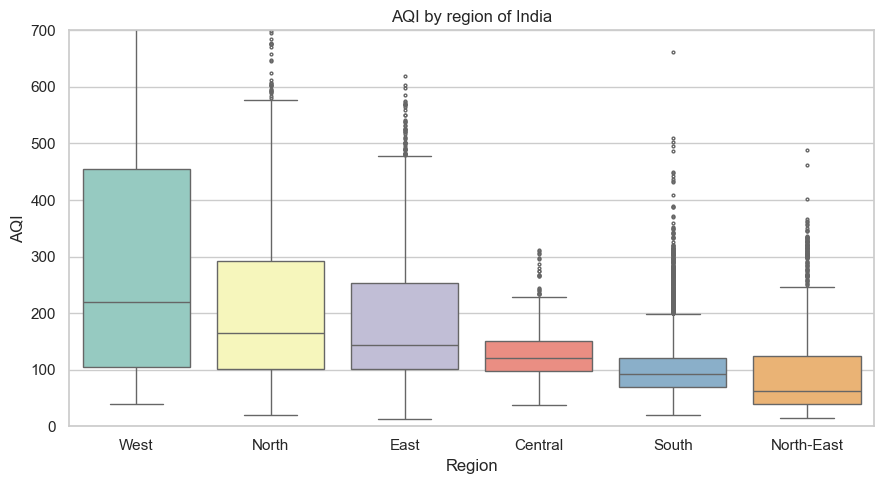

In [34]:
order_r = df.groupby('Region')['AQI'].median().sort_values(ascending=False).index
plt.figure(figsize=(9,5))
sns.boxplot(data=df, x='Region', y='AQI', order=order_r, palette='Set3', flierprops=dict(markersize=2))
plt.ylim(0, 700)
plt.xlabel('Region'); plt.ylabel('AQI')
plt.title('AQI by region of India')
plt.tight_layout(); plt.show()

**Why:** Grouping 26 cities into 6 regions makes the picture simpler and lets us test regional differences later.
**What it shows:** **West (because of Ahmedabad) and North** have the highest AQI, followed by East. **South and North-East** are the cleanest (median AQI about 92 and 63). So location is a strong factor. Note: Central has only one city (Bhopal) and West has only two.

## B8. COVID-19 lockdown effect

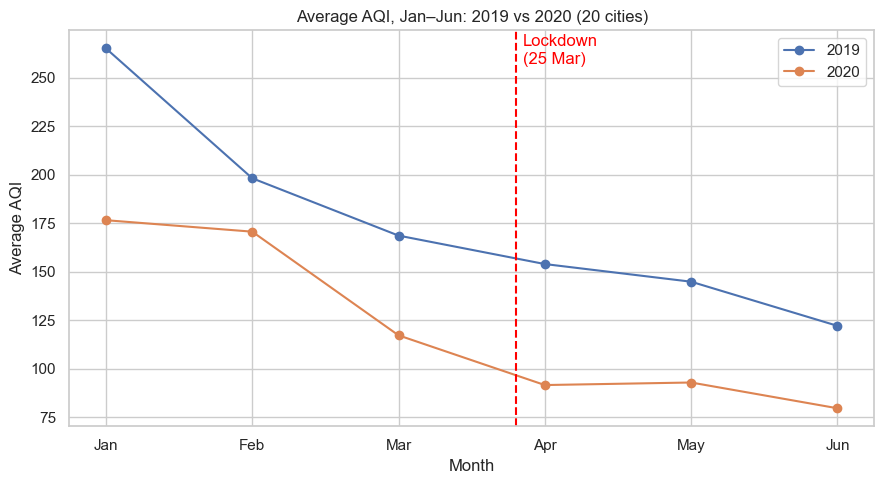

In [35]:
# Compare Jan-Jun of 2019 and 2020, only for cities that have data in both years
h = df[(df['Month'] <= 6) & (df['Year'].isin([2019, 2020]))]
both_years = h.groupby('City')['Year'].nunique()
h = h[h['City'].isin(both_years[both_years == 2].index)]
cmp = h.pivot_table(index='Month', columns='Year', values='AQI', aggfunc='mean')

plt.figure(figsize=(9,5))
plt.plot(cmp.index, cmp[2019], marker='o', label='2019')
plt.plot(cmp.index, cmp[2020], marker='o', label='2020')
plt.axvline(3.8, color='red', ls='--'); plt.text(3.85, cmp.values.max()*0.97, 'Lockdown\n(25 Mar)', color='red')
plt.xticks(range(1,7), ['Jan','Feb','Mar','Apr','May','Jun'])
plt.xlabel('Month'); plt.ylabel('Average AQI')
plt.title(f'Average AQI, Jan–Jun: 2019 vs 2020 ({len(both_years[both_years==2])} cities)')
plt.legend(); plt.tight_layout(); plt.show()

**Why:** The lockdown stopped most traffic and industry in 2020. It acts like a natural experiment, and we also use the same months of 2019 as a fair comparison. This is a good base for a hypothesis test later.
**What it shows:** The 2020 line is **below the 2019 line in every month**. Before the lockdown, 2020 was already 14–33% lower (Jan–Mar); during the lockdown months (Apr–Jun) it was 34–40% lower. So the lockdown probably helped, but 2020 was already cleaner in January, which means **the lockdown is not the only reason**. A hypothesis test is needed to be sure.

## B9. State-level view (using station data)

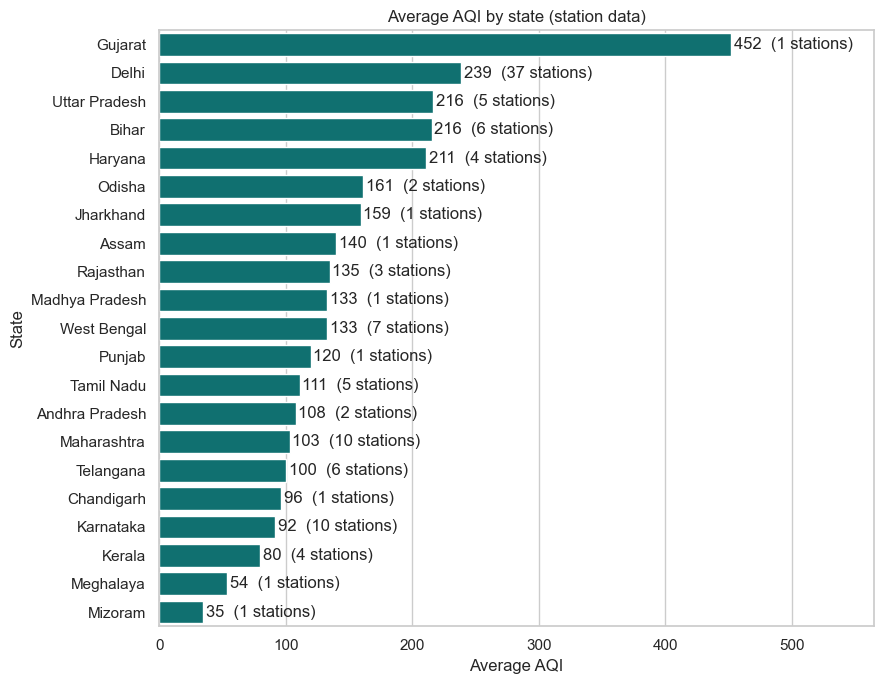

In [36]:
state = sd.groupby('State').agg(avg_AQI=('AQI', 'mean'), stations=('StationId', 'nunique'), days=('AQI', 'count')).sort_values('avg_AQI', ascending=False)
plt.figure(figsize=(9,7))
ax = sns.barplot(x=state['avg_AQI'], y=state.index, color='teal')
for i, (v, n) in enumerate(zip(state['avg_AQI'], state['stations'])):
    ax.text(v + 2, i, f'{v:.0f}  ({n} stations)', va='center')
plt.xlim(0, state['avg_AQI'].max() * 1.25)
plt.xlabel('Average AQI'); plt.ylabel('State')
plt.title('Average AQI by state (station data)')
plt.tight_layout(); plt.show()

**Why:** `station_day.csv` has much more detail (many stations per city), so we use it to check if the state-level picture agrees with the city-level picture.
**What it shows:** **Gujarat is at the top (about 452) but it has only 1 station**, so this one Ahmedabad station is responsible for the extreme values we saw earlier. After Gujarat come Delhi, Uttar Pradesh, Bihar and Haryana (all above 200), and southern states, Meghalaya and Mizoram are lowest. So the city-level and station-level files tell the same story. The number of stations per state differs a lot (1 to 37), so states with 1 station should be read with care.

# CONCLUSION – What we learned from pre-processing and EDA

1. **Data quality:** The data has no duplicates or negative values, but a lot is missing (Xylene 61%, PM10 38%, NH3 35%, AQI 16%) because many stations do not have every sensor. We dropped Xylene and rows without AQI, and filled the rest using the city-month median. We kept the real outliers.
2. **Data problems to remember:** The data is highly **right-skewed** (log transform fixes this), the coverage is **unbalanced** (cities start in different years and 2020 is half a year), and **Ahmedabad's CO is abnormally high**, which makes its AQI the highest. Ahmedabad must be handled separately in later analysis.
3. **What drives AQI:** **PM2.5 and PM10 are the main drivers** (correlation about 0.89–0.90 once Ahmedabad is removed). CO looks important (0.68) only because of Ahmedabad (0.30 without it). NOx is closely linked with NO/NO2, so we must be careful with repeated information in regression. Filling the missing PM10 values weakened its correlation (0.90 to 0.74), so the model part should treat PM10 carefully.
4. **Where and when pollution is worst:** North Indian cities (Delhi, Patna, Gurugram, Lucknow) are the most polluted, southern and north-eastern cities the cleanest. Pollution peaks in **post-monsoon and winter (Oct–Jan)** and is lowest in the monsoon. Day of the week makes no real difference.
5. **Lockdown and next steps:** AQI in 2020 was lower than in 2019 in every month (14–33% lower before the lockdown, 34–40% lower during it), so the lockdown likely helped but is not the only reason. Season, region, city and lockdown are the most promising factors for our analysis questions and hypothesis tests, and AQI can be our target variable for the ML model.

# Part 2 - Curated analysis questions

This section adapts the strongest case-specific questions from the other notebook, replaces its generic sampling simulation with a missingness/anomaly audit, and adds focused questions for the key tests, model, and dashboard.

**Question set:** Q1-Q15 adapt the useful case-specific analyses from the companion notebook; its generic sampling simulation was replaced with a data-quality audit. Q16 compares weekend and weekday AQI; Q17 tests the winter-versus-summer difference within cities; Q18-Q19 cover the regression decision and model diagnostics. Q10 also includes the Diwali event-window test. Total: 19.

# Air Quality in Indian Cities: Analysis Questions
**Course:** 23CSE351 – Foundations of Data Science | **Case Study – Part 2: Analysis Questions**

**Where we are:** Part 1 cleaned the data and explored it. The notebook contains 15 core data questions plus five final questions on formal inference, modeling, and reporting. Each analysis question has evidence, a chart, and an interpretation or decision. Hypothesis tests (Part 3) and the ML model (Part 4) build on these decisions.

## How the questions were chosen
Part 1 showed that this data has special problems: AQI is **right-skewed**, coverage is **unbalanced** (cities start in different years), **Ahmedabad's CO is abnormal**, and many values were **filled**. So the questions are not "what is the average of group X?". Each question tests **what the data can and cannot tell us**, and each one leads to a decision that is used later.

Every question has the same five parts:
1. **Question and why it matters** – the decision it helps with.
2. **Concept from class** – the lecture idea used (L6 distributions, L7/L11 sampling, L9/L10 descriptive statistics, L14 causation).
3. **Chart – what it is and why we use it** – the reason this chart fits this question.
4. **Code and output.**
5. **Answer and decision** – plus what is carried to Part 3 (hypothesis test) or Part 4 (ML).

## Map of the 15 core data questions
| Group | # | Question (short) | Class concept | Chart |
|---|---|---|---|---|
| A. Can we trust the headline numbers? | 1 | Is the average AQI a fair "typical day"? | Mean, median, trimmed mean (L9) | Dot (dumbbell) plot |
| | 2 | Which cities are chronically bad and which are erratic? | SD, coefficient of variation (L10) | Labelled bubble scatter |
| | 3 | Which cities have rare extreme days? | Skewness, kurtosis (L10) | Scatter + histograms |
| B. What is AQI made of? | 4 | How well can daily readings approximate the dominant pollutant? | Frequency / cross table (L7), AQI rule | Check scatter + 100% stacked bars |
| | 5 | How does the fine-particle share vary by season and AQI level? | Ratio, five-number summary (L10) | Box plots |
| | 6 | Which pollutants repeat the same information? | Covariance vs correlation (L10), correlation ≠ causation (L14) | Correlation heatmap |
| C. When and why does it change? | 7 | How much worse is winter than monsoon inside each city? | Stratification (L14) | Dot (dumbbell) plot |
| | 8 | Is the yearly improvement real or caused by the changing city mix? | Confounding, sampling bias (L14, L7) | Line chart + bar chart |
| | 9 | How did matched-city AQI changes in Jan-Mar and Apr-Jun 2020 compare with 2019? | Treatment vs control (L14) | Paired dot plot |
| | 10 | Is AQI higher after Diwali than the pre-event seasonal climb? | Treatment window vs control cities (L14) | Event-window lines + dot plot |
| D. How reliable is our evidence? | 11 | Do bad days come independently or in streaks? | Bernoulli, Binomial, empirical distribution (L6, L11) | Bars vs Binomial curve |
| | 12 | Can we trust the ranking of cities? | Sampling variability, bootstrap (L11) | Interval (forest) plot |
| | 13 | Which missingness patterns and anomalies could change the result? | Data validation and sensitivity analysis | Missingness heatmap + anomaly bars |
| | 14 | Does one city number hide local hot-spots? | Dispersion, range, data integration (L10, L8) | Bar chart + histogram |
| | 15 | How much of today's AQI is known from yesterday? | Covariance / correlation (L10) | Lag scatter + bar chart |

## Rules used in the whole notebook
- **Ahmedabad** is left out of every comparison between cities or years (CO problem from Part 1). It is shown separately where it is the point of the question (Q1-Q4).
- Because AQI is skewed (Q1), we use the **median** unless a question needs the mean.
- Where Part 1 showed that **filling** would mislead (particle ratio, correlations), we use the **original, un-filled readings**.
- The data is observational, so we describe **associations**; claims about cause are marked as such (L14).

## 0. Setup
Load the three clean files from Part 1 (run Part 1 first so that `city_day_clean.csv` and `station_day_clean.csv` exist) and the original `city_day.csv` for the questions that need un-filled values.

In [37]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(42)          # fixed seed: simulations give the same result every run

df  = pd.read_csv('city_day_clean.csv',    parse_dates=['Date'])   # cleaned in Part 1 (main data)
sd  = pd.read_csv('station_day_clean.csv', parse_dates=['Date'])   # cleaned station data
raw = pd.read_csv('city_day.csv',          parse_dates=['Date'])   # original file with its real gaps (no filling)

SEASONS = ['Winter', 'Summer', 'Monsoon', 'Post-Monsoon']
month_to_season = {12:'Winter', 1:'Winter', 2:'Winter', 3:'Summer', 4:'Summer', 5:'Summer',
                   6:'Monsoon', 7:'Monsoon', 8:'Monsoon', 9:'Monsoon', 10:'Post-Monsoon', 11:'Post-Monsoon'}
city_region = df.drop_duplicates('City').set_index('City')['Region']

raw['Season'] = raw['Date'].dt.month.map(month_to_season)     # same season rule as Part 1
raw['Region'] = raw['City'].map(city_region)

ex = df[df['City'] != 'Ahmedabad']       # "ex" = without Ahmedabad (its CO readings are abnormal, see Part 1)
print('Clean city data:', df.shape, '| cities:', df['City'].nunique(), '| days with AQI:', len(df))

Clean city data: (24850, 36) | cities: 26 | days with AQI: 24850


# GROUP A – Can we trust the headline numbers?
Before using any number, we check how reliable it is. Three questions use **central tendency, spread and shape** (L9, L10).

## Q1. Is the average AQI a fair picture of a "typical day" in each city?
**Why it matters:** Reports usually give one average AQI per city. If a few extreme days pull the average up, the city looks worse than a normal day really is. We need to know which number to quote.

**Concept from class:** Mean, median and trimmed mean (L9); skewness (L10). The mean is pulled towards the tail, so for skewed data the median is a better centre.

**Chart – what it is and why we use it:** A **dot (dumbbell) plot**: one row per city with three dots (median, 10% trimmed mean, mean) joined by a grey bar. The question is about the *distance* between three summaries for 26 cities, so the length of the grey bar *is* the answer. A bar chart would hide the gap, and 26 histograms would be too many to compare.

In [38]:
g = df.groupby('City')['AQI']
q1 = pd.DataFrame({'Days': g.size(),
                   'Median': g.median(),
                   'Trimmed mean (10%)': g.apply(lambda x: stats.trim_mean(x, 0.1)),   # drop lowest and highest 10%, then average
                   'Mean': g.mean()})
q1['Mean above median (%)'] = (q1['Mean'] / q1['Median'] - 1) * 100

print('Skewness of daily AQI  -> all cities: %.2f | without Ahmedabad: %.2f' % (stats.skew(df['AQI']), stats.skew(ex['AQI'])))
print('Pooled AQI -> mean %.0f | 10%% trimmed mean %.0f | median %.0f' % (df['AQI'].mean(), stats.trim_mean(df['AQI'], .1), df['AQI'].median()))
display(q1.sort_values('Mean above median (%)', ascending=False).round(1).head(6))
display(q1.sort_values('Mean above median (%)').round(1).head(4))

Skewness of daily AQI  -> all cities: 3.40 | without Ahmedabad: 1.51
Pooled AQI -> mean 166 | 10% trimmed mean 143 | median 118


,Days,Median,Trimmed mean (10%),Mean,Mean above median (%)
City,,,,,
Aizawl,111,23.0,31.6,34.8,51.2
Kolkata,754,94.0,124.9,140.6,49.5
Guwahati,495,98.0,126.1,140.1,43.0
Talcher,698,128.5,160.1,172.9,34.5
Brajrajnagar,713,122.0,142.1,150.3,23.2
Amaravati,841,78.0,86.2,95.3,22.2


,Days,Median,Trimmed mean (10%),Mean,Mean above median (%)
City,,,,,
Coimbatore,344,75.0,74.0,73.0,-2.6
Ernakulam,153,94.0,91.8,92.4,-1.7
Delhi,1999,257.0,254.9,259.5,1.0
Hyderabad,1880,104.0,104.1,109.2,5.0


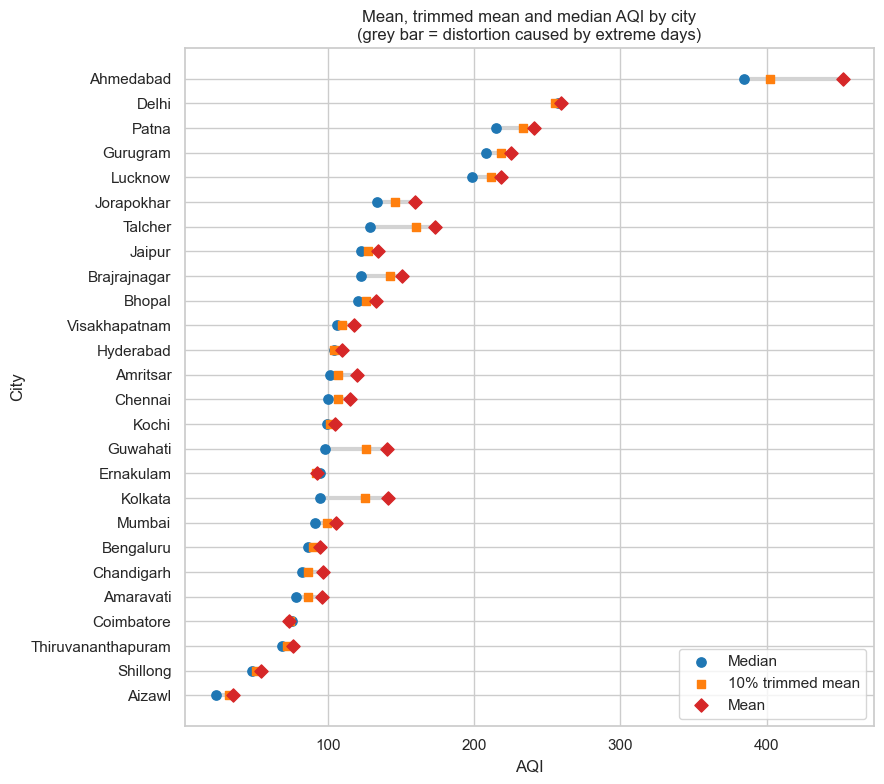

In [39]:
q1s = q1.sort_values('Median')
y = np.arange(len(q1s))
fig, ax = plt.subplots(figsize=(9, 8))
ax.hlines(y, q1s['Median'], q1s['Mean'], color='lightgrey', lw=3, zorder=1)        # grey bar = how far the mean is from the median
ax.scatter(q1s['Median'],             y, color='tab:blue',   s=45, label='Median', zorder=3)
ax.scatter(q1s['Trimmed mean (10%)'], y, color='tab:orange', s=40, marker='s', label='10% trimmed mean', zorder=3)
ax.scatter(q1s['Mean'],               y, color='tab:red',    s=45, marker='D', label='Mean', zorder=3)
ax.set_yticks(y); ax.set_yticklabels(q1s.index)
ax.set_xlabel('AQI'); ax.set_ylabel('City')
ax.set_title('Mean, trimmed mean and median AQI by city\n(grey bar = distortion caused by extreme days)')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

**What the output shows:**
- Pooled over all days: **mean 166, trimmed mean 143, median 118**, skewness 3.40 (1.51 without Ahmedabad). The mean is far above the median, which is the sign of a right tail.
- The mean overstates a typical day most in **Aizawl (+51%), Kolkata (+50%), Guwahati (+43%) and Talcher (+35%)**.
- **Delhi is different:** mean 259.5 and median 257 (+1%). Its air is high on almost every day, so there are no rare spikes pulling the mean up. Coimbatore and Ernakulam also have mean ≈ median.

**Answer and decision:** No, the mean is *not* a fair "typical day" for most cities because a few very bad days inflate it. **We use the median (and the share of bad days, Q12) to compare cities.** The mean is only safe for steady cities like Delhi. Aizawl has only 111 days, so its numbers are less certain.

**Carried to Part 3:** one-sample test – is Delhi's typical AQI above the 200 "Poor" limit?

## Q2. Which cities are *consistently* polluted and which are *erratic*?
**Why it matters:** Two cities can have the same average AQI but very different problems: one is bad every day (needs long-term control), the other has sudden bad episodes (needs warnings and emergency action).

**Concept from class:** Standard deviation and the **coefficient of variation (CV = SD / mean)** (L10). CV has no unit, so cities with very different levels can be compared fairly; SD alone would always be larger for polluted cities.

**Chart – what it is and why we use it:** A **labelled bubble scatter** with mean AQI on the x-axis and CV on the y-axis. Two numbers per city are needed at the same time (level and variability), and the dashed median lines split the chart into four types of city. Bubble size shows how many days each city has, so we know how much to trust each dot.

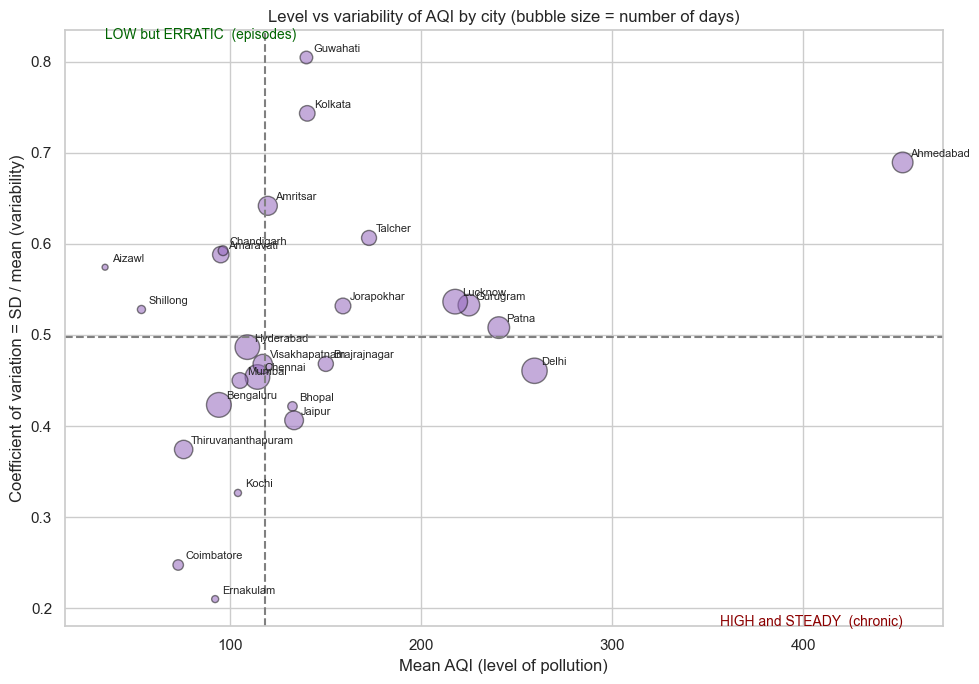

,Mean,SD,Days,CV
City,,,,
Ernakulam,92.36,19.39,153,0.21
Coimbatore,73.02,18.06,344,0.25
Kochi,104.28,34.05,158,0.33
Ahmedabad,452.12,311.73,1334,0.69
Kolkata,140.57,104.49,754,0.74
Guwahati,140.11,112.76,495,0.80


In [40]:
q2 = df.groupby('City')['AQI'].agg(Mean='mean', SD='std', Days='count')
q2['CV'] = q2['SD'] / q2['Mean']                       # coefficient of variation = SD / mean (no unit)
x_cut, y_cut = q2['Mean'].median(), q2['CV'].median()

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(q2['Mean'], q2['CV'], s=q2['Days'] / 6, alpha=.55, color='tab:purple', edgecolor='k')
for c, r in q2.iterrows():
    ax.annotate(c, (r['Mean'], r['CV']), fontsize=8, xytext=(5, 4), textcoords='offset points')
ax.axvline(x_cut, color='grey', ls='--'); ax.axhline(y_cut, color='grey', ls='--')
ax.text(q2['Mean'].max(), q2['CV'].min() - .03, 'HIGH and STEADY  (chronic)', ha='right', color='darkred', fontsize=10)
ax.text(q2['Mean'].min(), q2['CV'].max() + .02, 'LOW but ERRATIC  (episodes)', ha='left', color='darkgreen', fontsize=10)
ax.set_xlabel('Mean AQI (level of pollution)'); ax.set_ylabel('Coefficient of variation = SD / mean (variability)')
ax.set_title('Level vs variability of AQI by city (bubble size = number of days)')
plt.tight_layout(); plt.show()
display(q2.sort_values('CV').round(2).iloc[[0, 1, 2, -3, -2, -1]])

**What the output shows:**
- **Most steady:** Ernakulam (CV 0.21), Coimbatore (0.25) and Kochi (0.33), but all three have *low* AQI. Their air is both clean and predictable.
- **Most erratic:** Guwahati (CV 0.80), Kolkata (0.74) and Ahmedabad (0.69). Guwahati and Kolkata have a moderate average (about 140), so their average hides some very bad days.
- **Delhi:** mean 259 with CV 0.46, the highest level among the cities with low variability. Lucknow, Gurugram and Patna also sit on the right side of the chart (mean 218-241, CV 0.51-0.54).

**Answer and decision:** There are **two different problems**. *Chronic* cities (Delhi, Patna, Gurugram, Lucknow) have bad air most winter days; *episodic* cities (Guwahati, Kolkata, Amritsar) have a lower average but sudden bad stretches. In the report and dashboard, cities should be described by **level and CV together**, not by one average.

## Q3. Do some cities suffer sudden spikes instead of steady pollution?
**Why it matters:** Q2 shows how *much* AQI varies. This question asks *how* it varies: many moderate swings, or mostly normal days with a few extreme ones? Extreme days are the dangerous ones and they also create large errors in ML models.

**Concept from class:** Skewness and **kurtosis** (L10). Excess kurtosis above 0 means heavier tails than the normal curve, i.e. extreme values happen more often than a bell curve predicts. Negative means lighter tails.

**Chart – what it is and why we use it:** A **scatter of skewness vs excess kurtosis** (one point per city) to find the unusual cities, and next to it the **histograms** of one steady city (Delhi) and one spike city (Hyderabad) so the numbers can be *seen* as shapes. The scatter finds the cities, the histograms explain what the numbers mean.

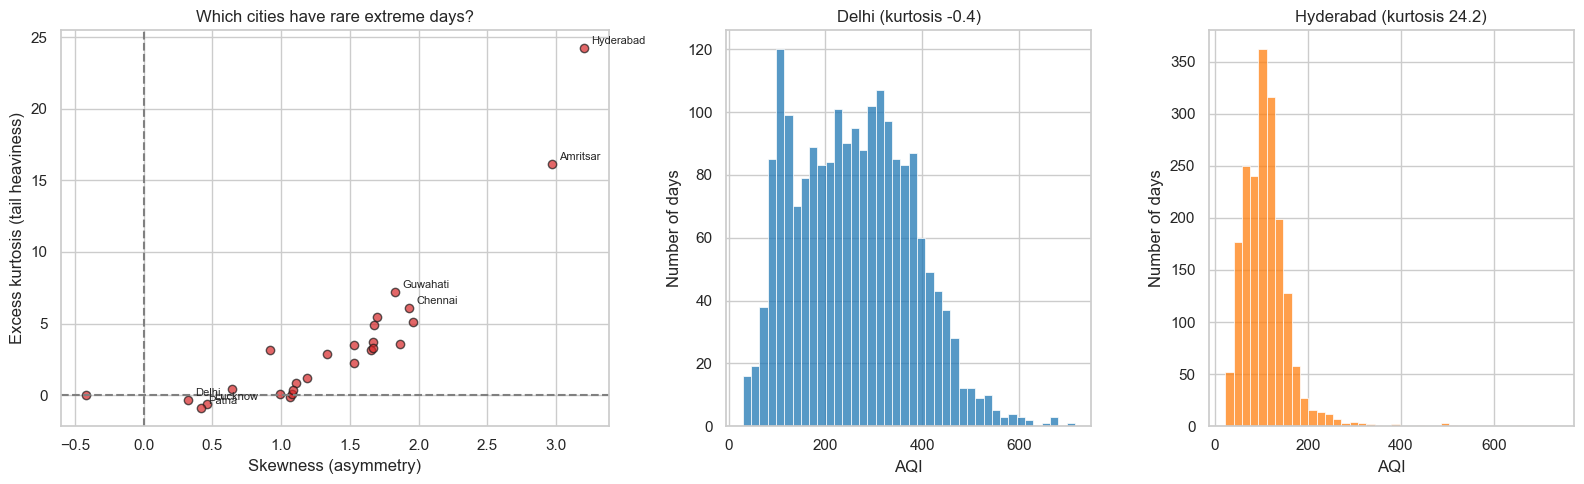

,Skewness,Excess_kurtosis
City,,
Hyderabad,3.20,24.21
Amritsar,2.97,16.12
Guwahati,1.83,7.18
Chennai,1.93,6.10
Kochi,1.70,5.47


Hyderabad: median AQI 104, max AQI 737, days above 300: 17 of 1880


In [41]:
q3 = df.groupby('City')['AQI'].agg(Skewness=stats.skew, Excess_kurtosis=stats.kurtosis)   # excess kurtosis: 0 = normal curve

fig = plt.figure(figsize=(16, 5))
gs = fig.add_gridspec(1, 3, width_ratios=[1.5, 1, 1])
ax = fig.add_subplot(gs[0])
ax.scatter(q3['Skewness'], q3['Excess_kurtosis'], color='tab:red', alpha=.7, edgecolor='k')
for c, r in q3.iterrows():
    if c in ['Hyderabad', 'Amritsar', 'Guwahati', 'Chennai', 'Delhi', 'Lucknow', 'Patna']:
        ax.annotate(c, (r['Skewness'], r['Excess_kurtosis']), fontsize=8, xytext=(5, 3), textcoords='offset points')
ax.axhline(0, color='grey', ls='--'); ax.axvline(0, color='grey', ls='--')
ax.set_xlabel('Skewness (asymmetry)'); ax.set_ylabel('Excess kurtosis (tail heaviness)')
ax.set_title('Which cities have rare extreme days?')

for k, (city, col) in enumerate([('Delhi', 'tab:blue'), ('Hyderabad', 'tab:orange')], start=1):
    a = fig.add_subplot(gs[k])
    sns.histplot(df.loc[df['City'] == city, 'AQI'], bins=40, color=col, ax=a)
    a.set_xlabel('AQI'); a.set_ylabel('Number of days'); a.set_title(f'{city} (kurtosis {q3.loc[city, "Excess_kurtosis"]:.1f})')
plt.tight_layout(); plt.show()
display(q3.sort_values('Excess_kurtosis', ascending=False).round(2).head(5))
print('Hyderabad: median AQI %.0f, max AQI %.0f, days above 300: %d of %d' % (
      df.loc[df.City=='Hyderabad','AQI'].median(), df.loc[df.City=='Hyderabad','AQI'].max(),
      (df.loc[df.City=='Hyderabad','AQI'] > 300).sum(), (df.City=='Hyderabad').sum()))

**What the output shows:**
- **Heavy tails:** Hyderabad (excess kurtosis 24.2), Amritsar (16.1), Guwahati (7.2), Chennai (6.1) and Kochi (5.5).
- **Light tails:** Delhi (-0.4), Lucknow (-0.6) and Patna (-0.9). Their distributions are wide and flat, with no rare extreme days.
- Hyderabad's median is 104 and only **17 of 1,880 days are above 300**, but the maximum is 737. The histogram shows a tight group of ordinary days and a very thin long tail.

**Answer and decision:** Yes. **Hyderabad, Amritsar, Guwahati and Chennai have mostly ordinary days with a few extreme ones**; the northern cities do not have rare spikes because their whole distribution sits high. So the average is not the right summary for spike cities (it agrees with Q1), and in Part 4 these extreme days will give the largest prediction errors. We will report **MAE as well as RMSE** and keep the log version of AQI.

# GROUP B – What is AQI made of?
AQI is not an average of pollutants. Q4 shows how it is built, and Q5-Q6 use that to understand the pollutants.

## Q4. How well can daily pollutant readings approximate the dominant AQI pollutant, and does it vary by season?
**Why it matters:** Knowing the "worst pollutant of the day" tells us what to control and which features matter for ML. Part 1 suspected that Ahmedabad's AQI is driven by CO; this question tests that with evidence.

**Concept from class:** Frequency and cross tables (L7: "data tables and charts") applied to a *derived column*. The CPCB rule is: each pollutant gets a **sub-index** (0-500) from its concentration and **AQI = the highest sub-index of the day**. We rebuild the sub-indices from the pollutant columns, and the pollutant with the highest one is the **dominant pollutant**.

**Chart – what it is and why we use it:** (1) A **validation scatter** of rebuilt AQI against reported AQI. If our rebuild does not match the real AQI, the "dominant pollutant" claim would be meaningless, so this check must come first. (2) A **100% stacked bar** per season: it compares the *composition* (share) of dominant pollutants across groups that have different numbers of days. Ahmedabad gets its own bar.

In [42]:
# CPCB rule: each pollutant gets a SUB-INDEX (0-500) from its concentration; AQI = the largest sub-index of the day.
A  = [0, 50, 100, 200, 300, 400, 500]                          # AQI points
BP = {'PM2.5': [0, 30, 60, 90, 120, 250, 380],                  # matching concentration breakpoints (ug/m3; CO in mg/m3)
      'PM10' : [0, 50, 100, 250, 350, 430, 510],
      'NO2'  : [0, 40, 80, 180, 280, 400, 520],
      'SO2'  : [0, 40, 80, 380, 800, 1600, 2100],
      'CO'   : [0, 1, 2, 10, 17, 34, 50],
      'O3'   : [0, 50, 100, 168, 208, 748, 900],
      'NH3'  : [0, 200, 400, 800, 1200, 1800, 2400]}

def sub_index(x, bp):
    s = np.interp(x.fillna(0), bp, A)                                         # straight line inside each band
    hi = (x > bp[-1]).values
    s[hi] = 500 + (x[hi] - bp[-1]) * 100 / (bp[-1] - bp[-2])                  # above the table: keep rising
    return pd.Series(s, index=x.index).where(x.notna())                       # a missing pollutant stays missing

sub = pd.DataFrame({p: sub_index(raw[p], BP[p]) for p in BP})
valid = (sub.notna().sum(axis=1) >= 3) & sub[['PM2.5', 'PM10']].notna().any(axis=1)    # CPCB: >=3 pollutants, one of them PM
raw['AQI_calc'] = sub.max(axis=1).where(valid)
raw['Dominant'] = sub.fillna(-1).idxmax(axis=1).where(valid)                  # pollutant with the largest sub-index

cmp_ = raw.dropna(subset=['AQI', 'AQI_calc'])
diff = (cmp_['AQI'] - cmp_['AQI_calc']).abs()
print('Days compared: %d | correlation reported vs rebuilt AQI: %.2f | within 20 AQI points: %.0f%%' % (
      len(cmp_), np.corrcoef(cmp_['AQI'], cmp_['AQI_calc'])[0, 1], (diff <= 20).mean() * 100))
print('\nDominant pollutant, share of days (%):')
print((cmp_['Dominant'].value_counts(normalize=True) * 100).round(1).to_string())

Days compared: 24785 | correlation reported vs rebuilt AQI: 0.89 | within 20 AQI points: 61%

Dominant pollutant, share of days (%):
Dominant
PM2.5    41.3
PM10     38.4
CO       15.4
O3        3.2
NO2       1.4
SO2       0.3
NH3       0.1


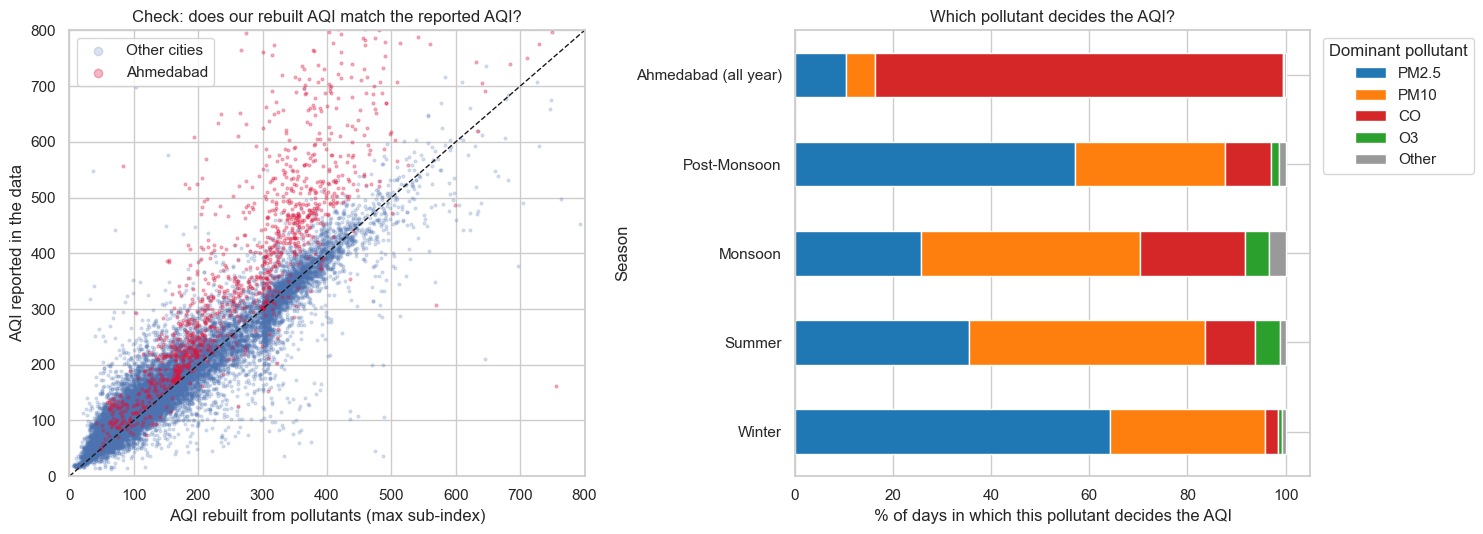

Dom,PM2.5,PM10,CO,O3,Other
Season,,,,,
Winter,64.0,32.0,3.0,1.0,1.0
Summer,35.0,48.0,10.0,5.0,1.0
Monsoon,26.0,45.0,21.0,5.0,3.0
Post-Monsoon,57.0,31.0,9.0,2.0,1.0
Ahmedabad (all year),10.0,6.0,83.0,0.0,0.0


In [43]:
show = ['PM2.5', 'PM10', 'CO', 'O3', 'Other']
cmp_['Dom'] = cmp_['Dominant'].where(cmp_['Dominant'].isin(show[:4]), 'Other')
no_ahd = cmp_[cmp_['City'] != 'Ahmedabad']
tab = pd.crosstab(no_ahd['Season'], no_ahd['Dom'], normalize='index')[show] * 100
tab.loc['Ahmedabad (all year)'] = cmp_.loc[cmp_['City'] == 'Ahmedabad', 'Dom'].value_counts(normalize=True).reindex(show).fillna(0) * 100
tab = tab.loc[SEASONS + ['Ahmedabad (all year)']]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
is_a = cmp_['City'] == 'Ahmedabad'
axes[0].scatter(cmp_.loc[~is_a, 'AQI_calc'], cmp_.loc[~is_a, 'AQI'], s=4, alpha=.2, label='Other cities')
axes[0].scatter(cmp_.loc[is_a, 'AQI_calc'],  cmp_.loc[is_a, 'AQI'],  s=4, alpha=.3, color='crimson', label='Ahmedabad')
axes[0].plot([0, 800], [0, 800], 'k--', lw=1); axes[0].set_xlim(0, 800); axes[0].set_ylim(0, 800)
axes[0].set_xlabel('AQI rebuilt from pollutants (max sub-index)'); axes[0].set_ylabel('AQI reported in the data')
axes[0].set_title('Check: does our rebuilt AQI match the reported AQI?'); axes[0].legend(markerscale=3)

tab.plot(kind='barh', stacked=True, ax=axes[1], color=['#1f77b4', '#ff7f0e', '#d62728', '#2ca02c', '#999999'])
axes[1].set_xlabel('% of days in which this pollutant decides the AQI'); axes[1].set_ylabel('Season')
axes[1].set_title('Which pollutant decides the AQI?'); axes[1].legend(title='Dominant pollutant', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()
display(tab.round(0))

**What the output shows:**
- **Validation:** rebuilt and reported AQI have correlation **0.89**, and 61% of days are within 20 AQI points. This is a good match, but not exact: CPCB uses 8-hour values for CO and O3, while we only have daily averages. Ahmedabad's points (red) sit *above* the line, so its reported AQI is higher than daily averages explain.
- **Overall:** PM2.5 decides 41% of days, PM10 38%, CO 15%, O3 3%.
- **By season (without Ahmedabad):** PM2.5 decides **64% of winter** and 57% of post-monsoon days; PM10 is the main pollutant in summer (48%) and monsoon (45%). In the monsoon, rain removes particles, so CO more often (21%) becomes the highest sub-index.
- **Ahmedabad:** CO decides **83% of days**.

**Answer and decision:**
1. AQI is the **worst single pollutant**, not a mix: PM2.5 in winter and post-monsoon, PM10 in summer and monsoon.
2. Part 1's suspicion is confirmed: **Ahmedabad's high AQI comes from CO**.
3. **Important for Part 4:** AQI is calculated from these same pollutants (our rebuild already reaches r = 0.89). A model that predicts AQI from same-day pollutants is almost solving the CPCB formula, not forecasting. We will frame the ML task honestly (next-day prediction, see Q15) and say so in the justification.

**Carried to Part 3:** chi-square test of independence between season and dominant pollutant (L13).

## Q5. How does the fine-particle share vary by season and AQI level?
**Why it matters:** PM2.5 (fine) goes deep into the lungs and comes mostly from burning (vehicles, fires), while the coarse part of PM10 is mostly dust. The **PM2.5 / PM10 ratio** tells which kind dominates, and whether bad days are made of a *different kind* of pollution, not only *more* of it.

**Concept from class:** A ratio as a new variable, compared across groups using the **five-number summary** (median, quartiles, whiskers) from L10.

**Chart – what it is and why we use it:** **Box plots**, because they show the median and spread of the ratio for each group in one view and make groups easy to compare. One panel groups by season, the other by AQI level of the day. Only **real readings** are used (the 256 rows where PM2.5 exceeds PM10 are flagged as consistency anomalies, and filled PM10 values would distort a ratio).

Days used: 17376 | median ratio: 0.47


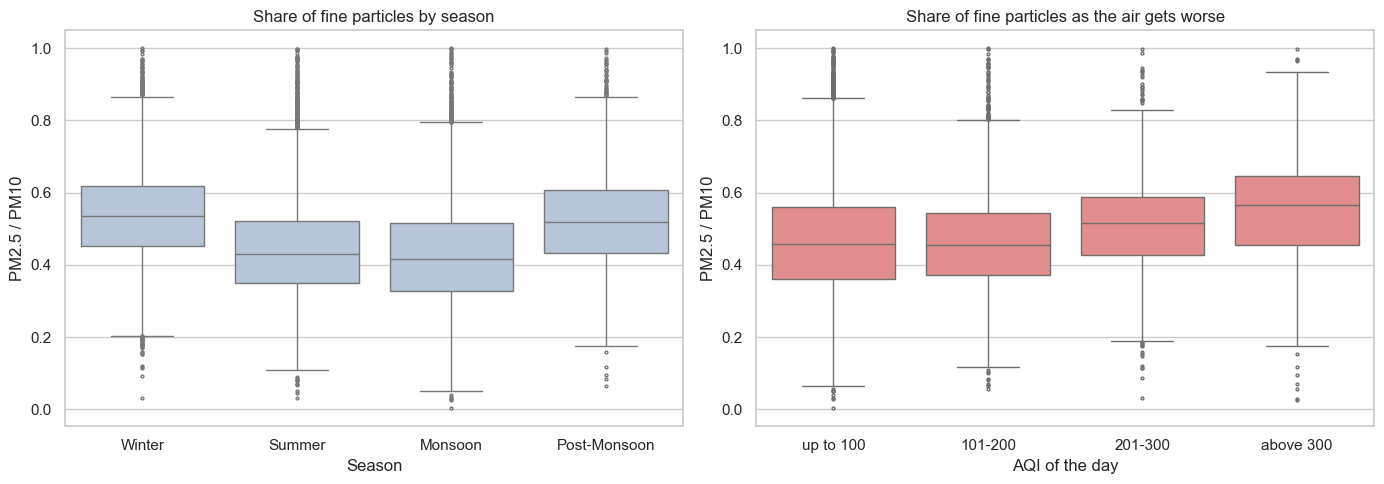

,median,count
City,,
Mumbai,0.33,762
Talcher,0.35,694
Bhopal,0.39,280
Shillong,0.68,223
Aizawl,0.69,110
Coimbatore,0.78,371


{'Winter': 0.54, 'Summer': 0.43, 'Monsoon': 0.41, 'Post-Monsoon': 0.52}
{'up to 100': 0.46, '101-200': 0.45, '201-300': 0.52, 'above 300': 0.57}


In [44]:
r = raw.dropna(subset=['PM2.5', 'PM10'])
r = r[(r['PM2.5'] <= r['PM10']) & (r['PM10'] > 0)].copy()      # real readings only; the 256 impossible rows (PM2.5 > PM10) are left out
r['Ratio'] = r['PM2.5'] / r['PM10']
r['AQI band'] = pd.cut(r['AQI'], [0, 100, 200, 300, 5000], labels=['up to 100', '101-200', '201-300', 'above 300'])
print('Days used:', len(r), '| median ratio: %.2f' % r['Ratio'].median())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=r, x='Season', y='Ratio', order=SEASONS, color='lightsteelblue', ax=axes[0], flierprops=dict(markersize=2))
axes[0].set_xlabel('Season'); axes[0].set_ylabel('PM2.5 / PM10'); axes[0].set_title('Share of fine particles by season')
sns.boxplot(data=r.dropna(subset=['AQI band']), x='AQI band', y='Ratio', color='lightcoral', ax=axes[1], flierprops=dict(markersize=2))
axes[1].set_xlabel('AQI of the day'); axes[1].set_ylabel('PM2.5 / PM10'); axes[1].set_title('Share of fine particles as the air gets worse')
plt.tight_layout(); plt.show()

by_city = r.groupby('City')['Ratio'].agg(['median', 'count']).sort_values('median')
display(pd.concat([by_city.head(3), by_city.tail(3)]).round(2))
print(r.groupby('Season')['Ratio'].median().round(2).reindex(SEASONS).to_dict())
print(r.groupby('AQI band')['Ratio'].median().round(2).to_dict())

**What the output shows:**
- Overall median ratio **0.47** (17,376 days): about half of PM10 is fine particles.
- **Season:** winter 0.54 and post-monsoon 0.52, against summer 0.43 and monsoon 0.41.
- **AQI level:** 0.46 (up to 100), 0.45 (101-200), 0.52 (201-300), **0.57 (above 300)**.
- **City:** lowest Mumbai (0.33), Talcher (0.35), Bhopal (0.39); highest Coimbatore (0.78), Aizawl (0.69), Shillong (0.68). The highest ones are small, clean cities, so they are less reliable.

**Answer and decision:** Yes, the share of fine particles **rises in winter and on the worst days**. This is typical of smoke from burning rather than only dust (it is an interpretation, not proved by this data). So PM2.5 is the key pollutant for health, and the **ratio can be an extra feature** in Part 4.

**Carried to Part 3:** two-sample test of the ratio, winter vs monsoon (L13).

## Q6. Which pollutants repeat the same information?
**Why it matters:** If two pollutants move together, using both in a regression adds no new information and makes the coefficients unstable (multicollinearity). We must choose features *before* building the ML model.

**Concept from class:** **Covariance** shows direction but its size depends on the units (L10), so we convert it to **correlation**, which is always between -1 and 1. We also apply L14: a high correlation is not a cause.

**Chart – what it is and why we use it:** A **correlation heatmap**: with 12 variables there are 66 pairs, and colour lets us find the strong ones at a glance. It uses the **log of real, un-filled readings** without Ahmedabad: log reduces skew (Part 1), and Part 1 showed that filled values weaken correlations.

COVARIANCE (original units) - the size depends on the units, so it cannot be compared:


,PM2.5,NO2,O3
PM2.5,4335.0,574.0,232.0
NO2,574.0,450.0,133.0
O3,232.0,133.0,467.0


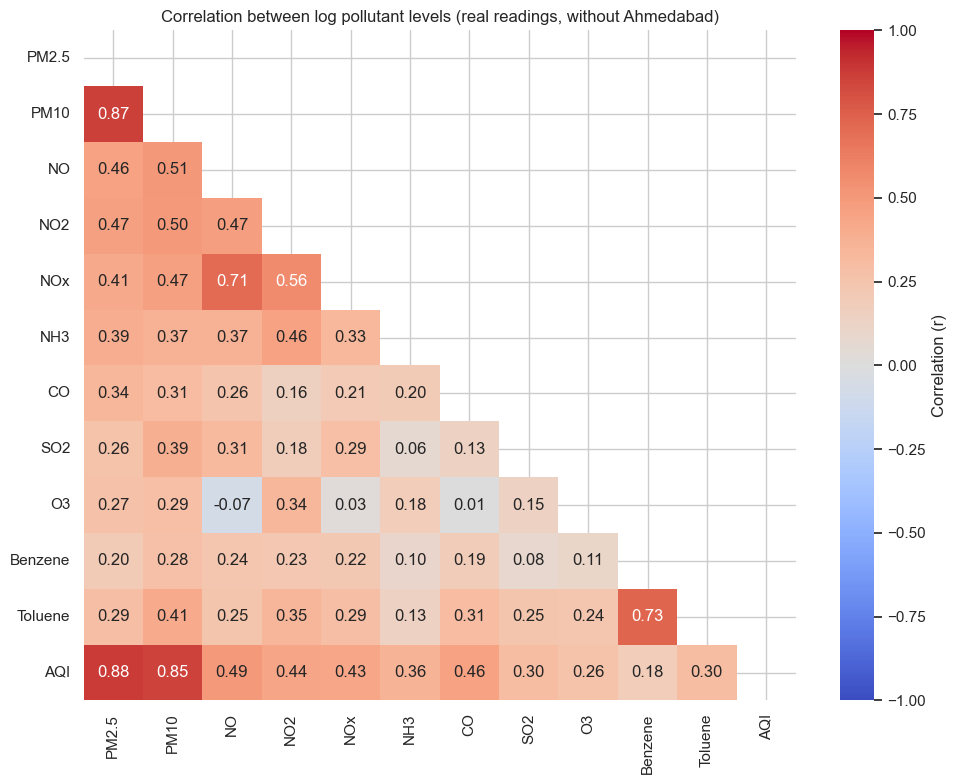

Pollutant pairs with |r| >= 0.6 (duplicate information):


,,r
PM10,PM2.5,0.87
Toluene,Benzene,0.73
NOx,NO,0.71


Correlation with AQI:
PM2.5      0.88
PM10       0.85
NO         0.49
CO         0.46
NO2        0.44
NOx        0.43
NH3        0.36
SO2        0.30
Toluene    0.30
O3         0.26
Benzene    0.18


In [45]:
P = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']
real = raw[raw['City'] != 'Ahmedabad']                      # real readings only (no filled values), without Ahmedabad

print('COVARIANCE (original units) - the size depends on the units, so it cannot be compared:')
display(real[['PM2.5', 'NO2', 'O3']].cov().round(0))

corr = np.log1p(real[P + ['AQI']]).corr()                   # log removes skew; pandas uses all days where both values exist
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, cbar_kws={'label': 'Correlation (r)'})
plt.title('Correlation between log pollutant levels (real readings, without Ahmedabad)')
plt.tight_layout(); plt.show()

pairs = corr.where(~mask).stack()
pairs = pairs[pairs.index.get_level_values(0) != 'AQI']
pairs = pairs[pairs.index.get_level_values(1) != 'AQI']
print('Pollutant pairs with |r| >= 0.6 (duplicate information):')
display(pairs[pairs.abs() >= 0.6].sort_values(ascending=False).round(2).to_frame('r'))
print('Correlation with AQI:'); print(corr['AQI'].drop('AQI').sort_values(ascending=False).round(2).to_string())

**What the output shows:**
- **Covariance cannot be compared:** the PM2.5-NO2 covariance (574) looks 2.5 times the PM2.5-O3 covariance (232), but PM2.5 simply has much larger numbers (its variance is 4,335 against 450-467).
- **Pairs with |r| of at least 0.6:** **PM2.5-PM10 (0.87)**, **Toluene-Benzene (0.73)** and **NO-NOx (0.71)**.
- **Correlation with AQI:** PM2.5 **0.88** and PM10 **0.85** are far ahead; NO 0.49, CO 0.46, NO2 0.44 and NOx 0.43 are moderate; Benzene 0.18 and O3 0.26 are weak.

**Answer and decision:** PM2.5 and PM10 carry largely the same information, NOx repeats NO (it is made of NO and NO2), and Toluene and Benzene overlap. **Feature plan for Part 4:** keep PM2.5, and either PM10 or the PM2.5/PM10 ratio (Q5), plus NO2, CO, SO2 and O3; drop NOx and one of Toluene/Benzene.

**Caution (L14):** PM2.5 and PM10 correlate with AQI *because AQI is calculated from them* (Q4). That is by construction, not a discovered cause.

# GROUP C – When and why does air quality change?
These questions use the **causal thinking of L14**: before blaming a season, a year or an event, we check that the comparison is fair (same cities, same months, a control group).

## Q7. How much worse is winter than the monsoon *inside each city*?
**Why it matters:** The pooled seasonal averages in Part 1 mix different cities in different seasons (coverage is unbalanced), so the "season effect" could be a "which cities were measured" effect. Comparing each city only with itself removes that.

**Concept from class:** **Stratification**, one of the ways L14 gives to handle a confounding variable: compare groups with similar values of the confounder (here, the same city).

**Chart – what it is and why we use it:** A **dot (dumbbell) plot**: for each city, a blue dot (monsoon median) and a red dot (winter median) with a grey bar between them. The bar length is the seasonal effect for that city, and the label gives the ratio. Cities need at least 30 days in both seasons, so Aizawl (no winter data) and Ernakulam are left out.

Cities compared: 24 | left out (fewer than 30 days in Winter or Monsoon): ['Aizawl', 'Ernakulam']


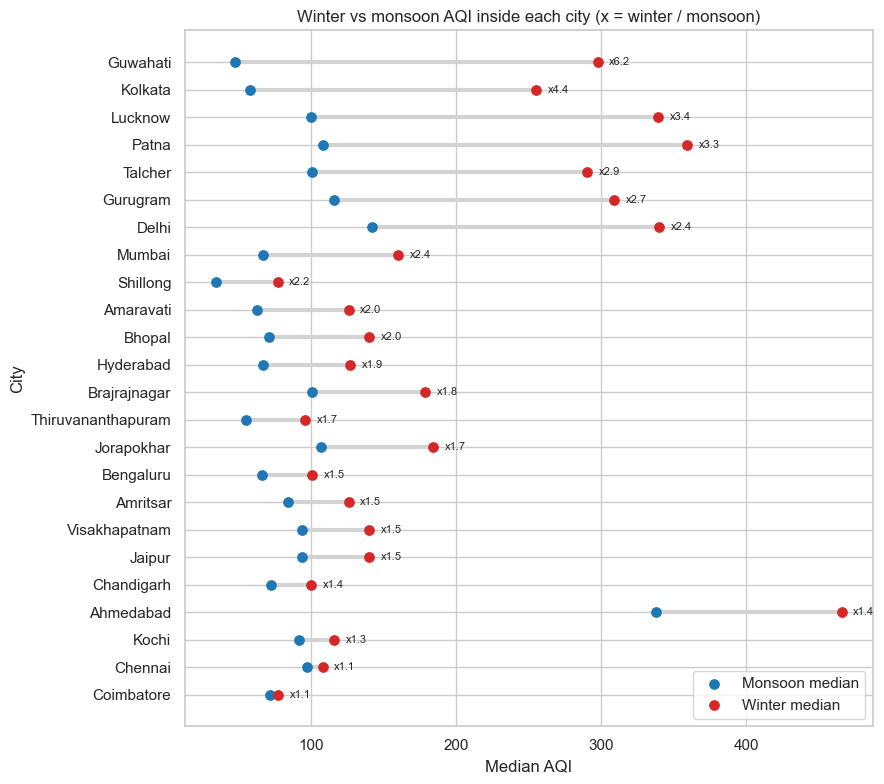

Median of the ratios by region:
Region
North-East    4.21
East          2.88
Central       1.97
North         1.95
West          1.88
South         1.51


In [46]:
q7 = df.pivot_table(index='City', columns='Season', values='AQI', aggfunc='median')
days = df.pivot_table(index='City', columns='Season', values='AQI', aggfunc='count')
q7 = q7[(days['Winter'] >= 30) & (days['Monsoon'] >= 30)].copy()      # need enough days in both seasons
q7['Ratio'] = q7['Winter'] / q7['Monsoon']
q7 = q7.sort_values('Ratio')
print('Cities compared:', len(q7), '| left out (fewer than 30 days in Winter or Monsoon):', sorted(set(df['City']) - set(q7.index)))

y = np.arange(len(q7))
fig, ax = plt.subplots(figsize=(9, 8))
ax.hlines(y, q7['Monsoon'], q7['Winter'], color='lightgrey', lw=3, zorder=1)
ax.scatter(q7['Monsoon'], y, color='tab:blue', s=45, label='Monsoon median', zorder=3)
ax.scatter(q7['Winter'],  y, color='tab:red',  s=45, label='Winter median',  zorder=3)
for i, (c, row) in enumerate(q7.iterrows()):
    ax.text(row['Winter'] + 8, i, f"x{row['Ratio']:.1f}", va='center', fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(q7.index)
ax.set_xlabel('Median AQI'); ax.set_ylabel('City'); ax.set_title('Winter vs monsoon AQI inside each city (x = winter / monsoon)')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()
print('Median of the ratios by region:'); print(q7.join(city_region).groupby('Region')['Ratio'].median().round(2).sort_values(ascending=False).to_string())

**What the output shows:**
- Winter is worse than monsoon in **all 24 cities compared** (every ratio is above 1).
- The size varies a lot: **Guwahati 6.2x, Kolkata 4.4x, Lucknow 3.4x, Patna 3.3x**, Delhi 2.4x (median 142 to 340), but only **Coimbatore 1.1x, Chennai 1.1x and Kochi 1.3x**.
- By region, the median ratio is North-East 4.2, East 2.9, Central 2.0, North 1.9, West 1.9 and **South 1.5**.

**Answer and decision:** Winter really is worse inside every city, so the season effect is not an artefact of the city mix. But the effect is **strong in the north and east and weak in the south**. One global "season" feature would be wrong: Part 4 needs **city or region together with season**.

**Carried to Part 3:** a paired t-test of winter vs monsoon city medians; retain the four-season chart as descriptive context.

## Q8. Is air quality really improving year by year, or is it just the changing mix of cities?
**Why it matters:** The all-city yearly average falls sharply, but the number of cities reporting grows from 7 (2015) to 23 (2019), and the new ones are mostly cleaner southern cities. A "national improvement" claim could be false.

**Concept from class:** **Confounding** (L14) and **sampling bias** (L7): the group being measured changes over time. The fix is a *fair panel*: the same cities, with enough data, in every year.

**Chart – what it is and why we use it:** (1) A **line chart with three versions** of the trend (all cities, all except Ahmedabad, same cities every year). If the lines differ, the city mix matters; the gap between them is the size of the illusion. (2) A **bar chart** of the change for each panel city, because an overall trend can hide cities that moved the other way. We compare **March-December only**, because most cities have no Jan-Feb data in 2015, and including winter in later years but not in 2015 would be unfair.

Cities in the fair "same-cities" panel: ['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Lucknow']
Number of cities reporting each year  : {2015: 7, 2016: 9, 2017: 15, 2018: 18, 2019: 23}


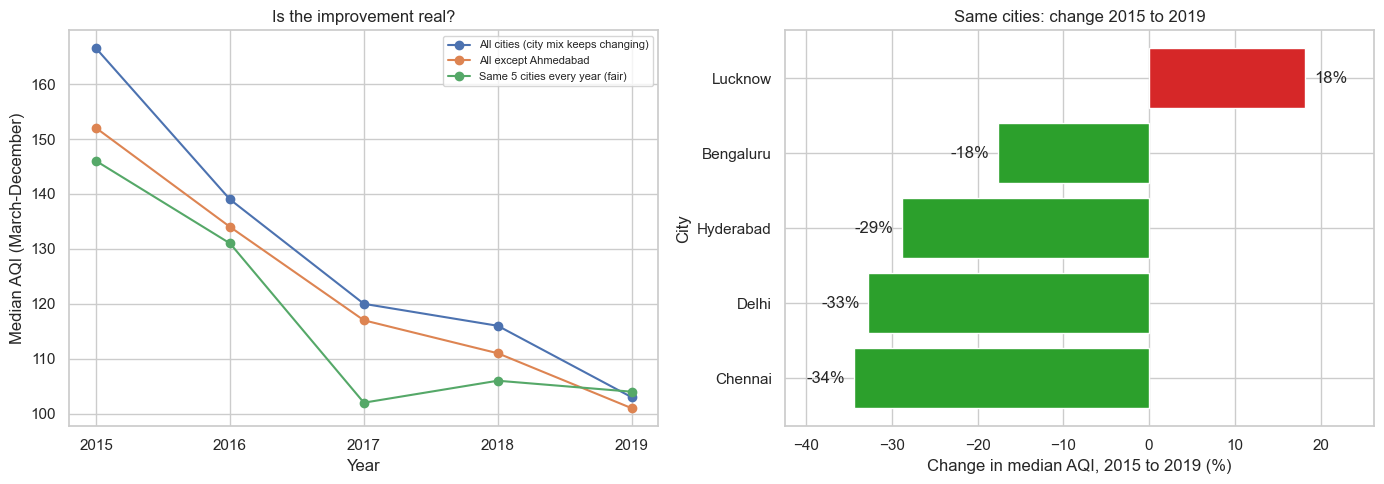

      All cities (city mix keeps changing)  All except Ahmedabad  Same 5 cities every year (fair)
Year                                                                                             
2015                                 166.0                 152.0                            146.0
2016                                 139.0                 134.0                            131.0
2017                                 120.0                 117.0                            102.0
2018                                 116.0                 111.0                            106.0
2019                                 103.0                 101.0                            104.0

Fall from 2015 to 2019 (%):
All cities (city mix keeps changing)   -38.1
All except Ahmedabad                   -33.6
Same 5 cities every year (fair)        -28.8

Median AQI of the 5 cities by year:
Year        2015   2016   2017   2018   2019
City                                        
Bengaluru  100.0   90.0

In [47]:
d = df[df['Year'].between(2015, 2019) & (df['Month'] >= 3)]            # 2020 = half year; Jan-Feb 2015 is missing for most cities -> use Mar-Dec of every year
yr_days = d.pivot_table(index='City', columns='Year', values='AQI', aggfunc='count').fillna(0)
panel = yr_days[(yr_days >= 240).all(axis=1)].index.tolist()          # cities with >= 240 of the 306 Mar-Dec days in EVERY year
print('Cities in the fair "same-cities" panel:', panel)
print('Number of cities reporting each year  :', d.groupby('Year')['City'].nunique().to_dict())

trend = pd.DataFrame({'All cities (city mix keeps changing)': d.groupby('Year')['AQI'].median(),
                      'All except Ahmedabad':                 d[d['City'] != 'Ahmedabad'].groupby('Year')['AQI'].median(),
                      'Same 5 cities every year (fair)':      d[d['City'].isin(panel)].groupby('Year')['AQI'].median()})
by_city = d[d['City'].isin(panel)].pivot_table(index='City', columns='Year', values='AQI', aggfunc='median')
chg = ((by_city[2019] / by_city[2015] - 1) * 100).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
trend.plot(marker='o', ax=axes[0]); axes[0].set_xticks(range(2015, 2020))
axes[0].set_xlabel('Year'); axes[0].set_ylabel('Median AQI (March-December)'); axes[0].set_title('Is the improvement real?'); axes[0].legend(fontsize=8)
axes[1].barh(chg.index, chg.values, color=['tab:green' if v < 0 else 'tab:red' for v in chg.values])
for i, v in enumerate(chg.values):
    axes[1].text(v + (1 if v >= 0 else -1), i, f'{v:.0f}%', va='center', ha='left' if v >= 0 else 'right')
axes[1].set_xlabel('Change in median AQI, 2015 to 2019 (%)'); axes[1].set_ylabel('City'); axes[1].set_title('Same cities: change 2015 to 2019')
axes[1].set_xlim(min(chg.min() - 8, -10), max(chg.max(), 0) + 8)
plt.tight_layout(); plt.show()
print(trend.round(0).to_string())
print('\nFall from 2015 to 2019 (%):'); print(((trend.loc[2019] / trend.loc[2015] - 1) * 100).round(1).to_string())
print('\nMedian AQI of the 5 cities by year:'); print(by_city.round(0).to_string())

**What the output shows:**
- Number of cities reporting: 7, 9, 15, 18, 23 for 2015-2019.
- Median AQI (Mar-Dec) falls **38%** for all cities (166 to 103), **34%** without Ahmedabad (152 to 101), but only **29%** for the **same 5 cities** (146 to 104).
- The same-city panel falls from 146 to 102 by 2017 and then stays flat (106 in 2018, 104 in 2019).
- By city (2015 to 2019): **Chennai -34%, Delhi -33%, Hyderabad -29%, Bengaluru -18%, but Lucknow +18%** (it rose until 2017 and fell afterwards).

**Answer and decision:** The improvement is **real but smaller than the pooled figure**: about 9 percentage points of the "38%" come from the changing city mix. It is also **not steady** (most of the fall happened by 2017) and **not universal** (Lucknow got worse). In Part 3 and in the report we will quote the panel result, not the pooled one, and we will not use "year" as a trend feature on pooled data.

**Carried forward:** report the same-city 2015?2019 panel trend descriptively, with the small five-city panel and coverage limitations stated.

## Q9. Did the COVID-19 lockdown cause the 2020 drop, or was 2020 already cleaner?
**Why it matters:** Part 1 saw that Jan-Mar 2020 was already below Jan-Mar 2019, before any lockdown. If we compare only "before" and "after" in 2020, we would credit the lockdown with changes that were already under way.

**Concept from class:** **Treatment vs control** (L14). 2019 is the control: the same months, without a lockdown. For each city we compute the 2020-vs-2019 change *before* the lockdown (Jan-Mar) and *during* it (Apr-Jun). The lockdown effect is the **extra** change during the lockdown.

**Chart – what it is and why we use it:** A **paired dot plot**: for each city, a grey dot (change before the lockdown) and a red dot (change during it) joined by a line. The line length and direction are the lockdown's extra effect, so we can see whether it is consistent across cities or only an average. Cities need at least 30 days in each of the four cells; Ahmedabad is left out.

Cities compared: 18 (Ahmedabad excluded)


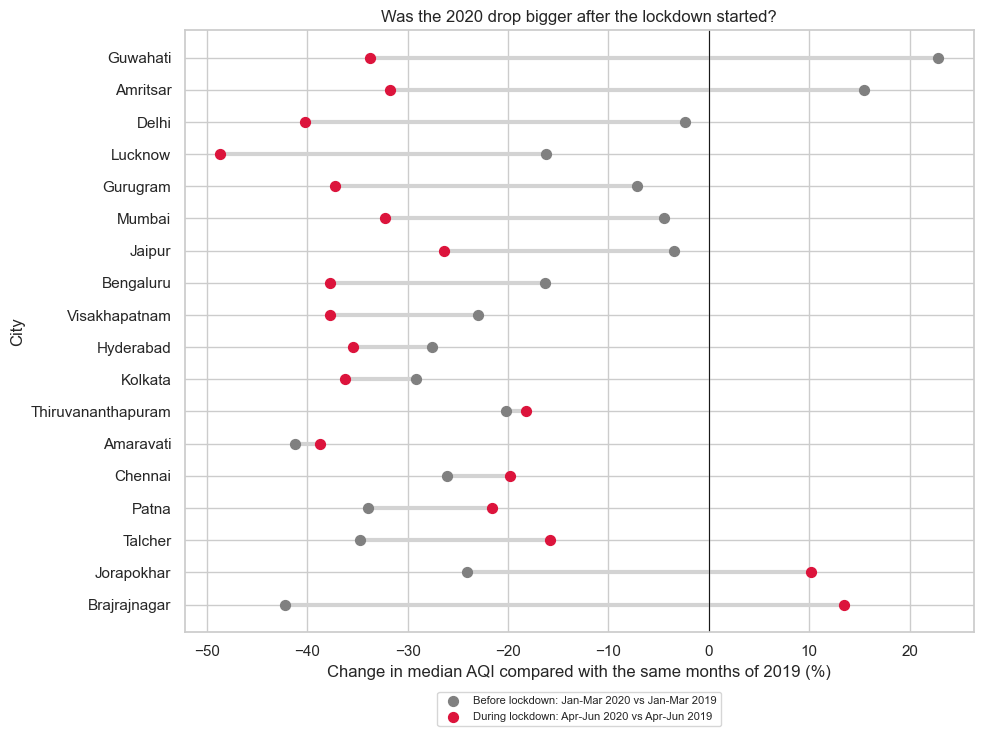

Median change vs 2019 -> before lockdown: -21.6% | during lockdown: -33.0% | extra: -11.3 points
Cities where the drop became bigger during lockdown: 11 of 18
Largest extra drops : ['Guwahati', 'Amritsar', 'Delhi', 'Lucknow', 'Gurugram']
No extra drop       : ['Brajrajnagar', 'Jorapokhar', 'Talcher', 'Patna', 'Chennai', 'Amaravati', 'Thiruvananthapuram']


In [48]:
h = ex[(ex['Month'] <= 6) & ex['Year'].isin([2019, 2020])].copy()
h['Period'] = np.where(h['Month'] <= 3, 'Before lockdown (Jan-Mar)', 'Lockdown (Apr-Jun)')
cnt = h.pivot_table(index='City', columns=['Period', 'Year'], values='AQI', aggfunc='count').fillna(0)
keep = cnt[(cnt >= 30).all(axis=1)].index                               # city needs >= 30 days in all four cells
t = h[h['City'].isin(keep)].pivot_table(index='City', columns=['Period', 'Year'], values='AQI', aggfunc='median')

q9 = pd.DataFrame({'Before lockdown': (t['Before lockdown (Jan-Mar)'][2020] / t['Before lockdown (Jan-Mar)'][2019] - 1) * 100,
                   'Lockdown':        (t['Lockdown (Apr-Jun)'][2020]        / t['Lockdown (Apr-Jun)'][2019]        - 1) * 100})
q9['Extra drop'] = q9['Lockdown'] - q9['Before lockdown']
q9 = q9.sort_values('Extra drop', ascending=False)
print('Cities compared:', len(q9), '(Ahmedabad excluded)')

y = np.arange(len(q9))
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.hlines(y, q9['Before lockdown'], q9['Lockdown'], color='lightgrey', lw=3, zorder=1)
ax.scatter(q9['Before lockdown'], y, color='grey',     s=50, label='Before lockdown: Jan-Mar 2020 vs Jan-Mar 2019', zorder=3)
ax.scatter(q9['Lockdown'],        y, color='crimson',  s=50, label='During lockdown: Apr-Jun 2020 vs Apr-Jun 2019',  zorder=3)
ax.axvline(0, color='k', lw=.8)
ax.set_yticks(y); ax.set_yticklabels(q9.index)
ax.set_xlabel('Change in median AQI compared with the same months of 2019 (%)'); ax.set_ylabel('City')
ax.set_title('Was the 2020 drop bigger after the lockdown started?')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=1, fontsize=8); plt.tight_layout(); plt.show()

print('Median change vs 2019 -> before lockdown: %.1f%% | during lockdown: %.1f%% | extra: %.1f points' % (
      q9['Before lockdown'].median(), q9['Lockdown'].median(), q9['Extra drop'].median()))
print('Cities where the drop became bigger during lockdown: %d of %d' % ((q9['Extra drop'] < 0).sum(), len(q9)))
print('Largest extra drops :', q9.sort_values('Extra drop').index[:5].tolist())
print('No extra drop       :', q9[q9['Extra drop'] >= 0].index.tolist())

**What the output shows:**
- 18 cities compared. The median change vs 2019 was **-21.6% before the lockdown** and **-33.0% during it**: an **extra drop of 11.3 points**.
- **11 of 18 cities** show a bigger drop during the lockdown; 7 do not.
- Largest extra drops: Guwahati, Amritsar, Delhi, Lucknow, Gurugram (large northern cities). Cities with no extra drop: Jorapokhar, Brajrajnagar, Talcher (coal and industrial belt), Amaravati, Patna, Chennai, Thiruvananthapuram.

**Answer and decision:** The 2020-vs-2019 drop was already visible before lockdown. The point estimates suggest a further reduction in Apr-Jun, but the paired city-level t-test is not significant (p=0.172); we do not conclude that lockdown caused the extra decline. A simple Lockdown flag would be confounded with year and seasonal differences.

**Limit:** this is not a randomised experiment (L14). Weather and rain in 2019 vs 2020 are not controlled.

**Carried to Part 3:** this is our **A/B test**: treatment = Apr-Jun 2020, control = Apr-Jun 2019. We use a two-sided one-sample t-test on each city's paired incremental change; 11 of 18 city effects are negative.

## Q10. Is AQI higher after Diwali than the pre-event seasonal climb?
**Why it matters:** Diwali falls in October-November, exactly when AQI climbs for seasonal reasons (Q7). To say the festival has an effect, the jump must be *beyond* the climb that was already happening.

**Concept from class:** Treatment window vs control (L14). The five Diwali dates (2015-2019) are lined up at day 0. The "normal" level is each city's average on days -10 to -4. We compare the day after Diwali (+1) with the three days *before* it (the climb already under way). Southern cities, where the pre-festival climb is small, act as a comparison group. Only cities with at least 3 festivals of data are used.

**Chart – what it is and why we use it:** (1) An **event-window line chart** (days from Diwali on the x-axis, AQI index on the y-axis): it shows the *timing* of the jump and how long it lasts. (2) A **dot plot** per city, with a grey dot for the 3 days before and a red dot for the day after: the line between them is the extra jump beyond the pre-festival climb. The index is divided by the city's own normal level so that cities with very different AQI can be shown together.

**Hypotheses:** H0: the mean city-level change in AQI index from days -3 to -1 to day +1 is zero or below. H1: it is above zero. For each city, calculate the change for each festival year and then take the city median, so repeated festivals do not count as independent cities.

**Statistical test:** A one-sided one-sample t-test compares the nine city-level median changes with zero. It tests the mean change and assumes the city-level effects are reasonably well behaved. The small number of cities warrants caution. Report the test statistic, p-value, and confidence interval from the output below; the multiple-test-adjusted p-value is summarized with the other selected tests in Part 3. This is an event-timed association, not proof that fireworks caused the increase; weather and other concurrent factors are uncontrolled.


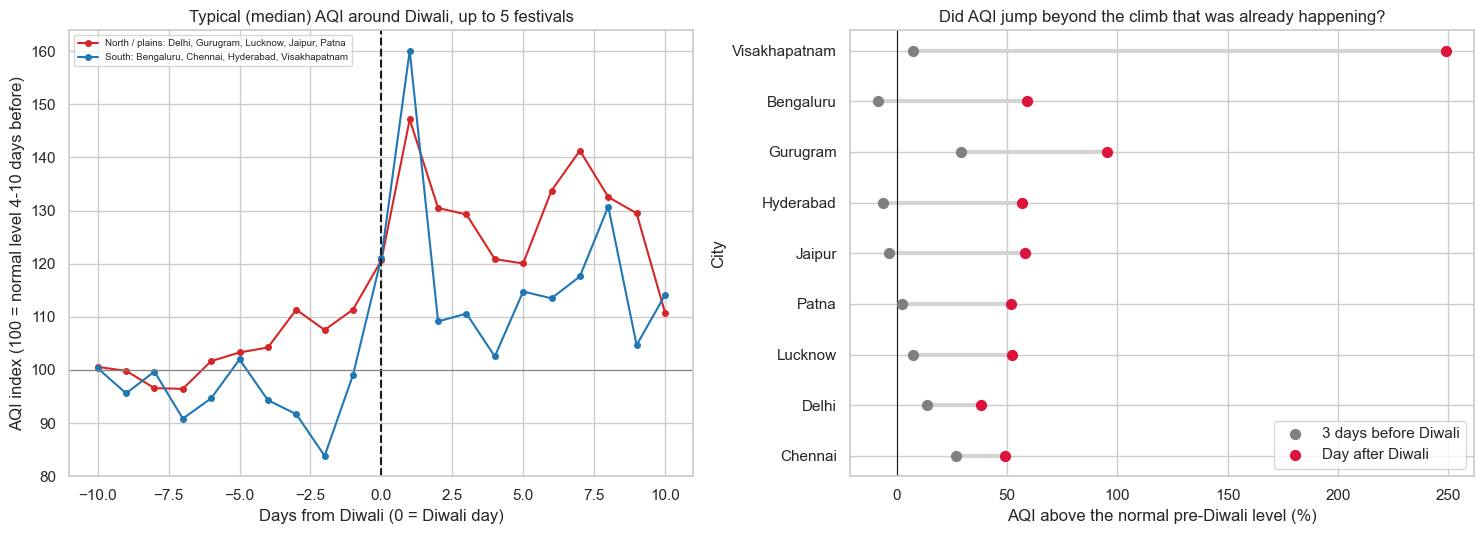

,Days -3 to -1 (already climbing),Day +1 (after Diwali),Days +4 to +7,Festivals used,Extra jump on day +1
City,,,,,
Chennai,27.0,49.0,19.0,5,22.0
Delhi,14.0,38.0,36.0,5,24.0
Lucknow,7.0,52.0,34.0,5,45.0
Patna,3.0,52.0,29.0,4,49.0
Jaipur,-3.0,58.0,1.0,3,61.0
Hyderabad,-6.0,57.0,6.0,5,63.0
Gurugram,29.0,95.0,112.0,4,66.0
Bengaluru,-8.0,59.0,18.0,5,67.0
Visakhapatnam,7.0,249.0,90.0,3,242.0


Cities where day +1 is higher than the 3 days before: 9 of 9
Median extra jump: 61 points | still above normal on days +4 to +7 (cities): 7 of 9


In [60]:
diwali = {2015: '2015-11-11', 2016: '2016-10-30', 2017: '2017-10-19', 2018: '2018-11-07', 2019: '2019-10-27'}
parts = []
for yr, day in diwali.items():
    w = df[(df['Date'] >= pd.Timestamp(day) - pd.Timedelta(days=10)) & (df['Date'] <= pd.Timestamp(day) + pd.Timedelta(days=10))].copy()
    w['Offset'] = (w['Date'] - pd.Timestamp(day)).dt.days                 # days before (-) / after (+) Diwali
    w['Diwali year'] = yr
    parts.append(w)
w = pd.concat(parts)
w = w.groupby(['City', 'Diwali year']).filter(lambda x: len(x) >= 15)     # keep city-years with at least 15 of the 21 days
w = w[w.groupby('City')['Diwali year'].transform('nunique') >= 3]         # keep cities that have at least 3 of the 5 festivals
w = w[w['City'] != 'Ahmedabad']                                           # AQI problem found in Part 1

base = w[w['Offset'].between(-10, -4)].groupby(['City', 'Diwali year'])['AQI'].mean().rename('Base')
w = w.join(base, on=['City', 'Diwali year'])
w['Index'] = w['AQI'] / w['Base'] * 100                                   # 100 = normal level of that city 4-10 days before Diwali

north, south = ['Delhi', 'Gurugram', 'Lucknow', 'Jaipur', 'Patna'], ['Bengaluru', 'Chennai', 'Hyderabad', 'Visakhapatnam']
q10 = pd.DataFrame({'Days -3 to -1 (already climbing)': w[w['Offset'].between(-3, -1)].groupby('City')['Index'].mean() - 100,
                    'Day +1 (after Diwali)':            w[w['Offset'] == 1].groupby('City')['Index'].mean() - 100,
                    'Days +4 to +7':                    w[w['Offset'].between(4, 7)].groupby('City')['Index'].mean() - 100,
                    'Festivals used':                   w.groupby('City')['Diwali year'].nunique()})
q10['Extra jump on day +1'] = q10['Day +1 (after Diwali)'] - q10['Days -3 to -1 (already climbing)']
q10 = q10.sort_values('Extra jump on day +1')

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for name, cities, col in [('North / plains', north, 'tab:red'), ('South', south, 'tab:blue')]:
    m = w[w['City'].isin(cities)].groupby('Offset')['Index'].median()   # median: one extreme city cannot drag the line
    axes[0].plot(m.index, m.values, marker='o', ms=4, color=col, label=f"{name}: {', '.join(cities)}")
axes[0].axvline(0, color='k', ls='--'); axes[0].axhline(100, color='grey', lw=.8)
axes[0].set_xlabel('Days from Diwali (0 = Diwali day)'); axes[0].set_ylabel('AQI index (100 = normal level 4-10 days before)')
axes[0].set_title('Typical (median) AQI around Diwali, up to 5 festivals'); axes[0].legend(fontsize=7, loc='upper left')

y = np.arange(len(q10))
axes[1].hlines(y, q10['Days -3 to -1 (already climbing)'], q10['Day +1 (after Diwali)'], color='lightgrey', lw=3, zorder=1)
axes[1].scatter(q10['Days -3 to -1 (already climbing)'], y, color='grey',    s=50, label='3 days before Diwali', zorder=3)
axes[1].scatter(q10['Day +1 (after Diwali)'],            y, color='crimson', s=50, label='Day after Diwali',     zorder=3)
axes[1].set_yticks(y); axes[1].set_yticklabels(q10.index); axes[1].axvline(0, color='k', lw=.8)
axes[1].set_xlabel('AQI above the normal pre-Diwali level (%)'); axes[1].set_ylabel('City')
axes[1].set_title('Did AQI jump beyond the climb that was already happening?'); axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()
display(q10.round(0))
print('Cities where day +1 is higher than the 3 days before:', int((q10['Extra jump on day +1'] > 0).sum()), 'of', len(q10))
print('Median extra jump: %.0f points | still above normal on days +4 to +7 (cities): %d of %d' % (
      q10['Extra jump on day +1'].median(), int((q10['Days +4 to +7'] > 10).sum()), len(q10)))

In [ ]:
event_rows=[]
for (city_name, festival_year), g in w.groupby(['City','Diwali year']):
    before = g.loc[g['Offset'].between(-3,-1),'Index']
    after = g.loc[g['Offset']==1,'Index']
    if len(before) and len(after):
        event_rows.append((city_name,festival_year,float(after.mean()-before.mean())))
event_diffs=pd.DataFrame(event_rows,columns=['City','Diwali year','Extra index points'])
city_event=event_diffs.groupby('City')['Extra index points'].median()
di_test=stats.ttest_1samp(city_event, popmean=0, alternative='greater')
di_ci=stats.t.interval(0.95, len(city_event)-1, loc=city_event.mean(), scale=stats.sem(city_event))
print(f'Cities with usable event comparisons: {len(city_event)}')
print(f'Median city-level extra increase: {city_event.median():.1f} index points')
print(f'One-sided one-sample t-test: t={di_test.statistic:.3f}, df={len(city_event)-1}, p={di_test.pvalue:.6g}')
print(f'Mean city-level increase={city_event.mean():.1f}; two-sided 95% CI=({di_ci[0]:.1f}, {di_ci[1]:.1f}) index points')
fig,ax=plt.subplots(figsize=(8,4.5)); ordered=city_event.sort_values(); ax.axvline(0,color='black',lw=1)
ax.scatter(ordered.values,ordered.index,color='crimson'); ax.set_xlabel('City median increase: day +1 minus days -3 to -1 (index points)'); ax.set_ylabel('City')
ax.set_title('Diwali event increase by city'); plt.tight_layout(); plt.show()

**What the output shows:**
- **All 9 cities** have a higher AQI on the day after Diwali than in the 3 days before it. The median extra jump is **61 index points**.
- Day +1 is **38% above normal in Delhi, 52% in Lucknow and Patna, 57-59% in Hyderabad, Jaipur and Bengaluru, 95% in Gurugram**. Visakhapatnam shows 249%, an outlier with only 3 festivals of data.
- The pre-festival climb differs: Gurugram (+29%), Chennai (+27%) and Delhi (+14%) were already rising, whereas **Bengaluru (-8%) and Hyderabad (-6%) were below normal just before Diwali** and still jump by about 57-59%.
- **Line chart:** the southern line spikes on day +1 and drops back within a day, while the northern line climbs before Diwali and stays about 20-40% above normal for the next week.
- After the jump, **7 of 9 cities are still more than 10% above normal on days +4 to +7**; the jump fades quickly in Jaipur (+1%) and Hyderabad (+6%).

**Answer and decision:** AQI index rises after Diwali beyond the preceding climb in the observed city summaries. The city-level one-sided test is included below: nine city summaries, t(8) = 2.330, raw p = 0.0241, with mean increase 74.1 index points and a two-sided 95% CI of [0.8, 147.4]. The Holm-adjusted p-value is 0.0481. This is an event-timed association; the observational design cannot isolate fireworks from weather or other concurrent changes.

**Model implication:** The event-window result is not used as a model feature: the 2020 holdout ends before Diwali, so a Diwali feature cannot be evaluated fairly.

# GROUP D – How reliable is our evidence?
The last group checks the **assumptions behind the evidence**: are days independent (Q11), how uncertain are city-risk estimates (Q12), which data issues matter (Q13), does a city average hide station hotspots (Q14), and how predictable is tomorrow (Q15).

## Q11. Do bad-air days arrive like independent coin flips, or in streaks?
**Why it matters:** Almost every statistical test assumes that observations are independent. If one bad day makes the next bad day more likely, our 24,850 rows are worth far fewer *independent* observations, and p-values in Part 3 would look better than they should.

**Concept from class:** Each day is a **Bernoulli trial** (bad day = AQI above 200, the "Poor" limit). The number of bad days in 28 days should follow a **Binomial(n = 28, p)** distribution with mean *np* and variance *np(1-p)* if days are independent (L6). We compare this theoretical distribution with the **empirical distribution** we actually observe (L11).

**Chart – what it is and why we use it:** **Bars of the observed distribution with the Binomial curve on top.** If the days were independent, the bars would follow the red curve. Any gap shows what independence cannot explain. Delhi (bad days common) and Chennai (rare) are shown side by side. The table also gives the chance of a bad day after a bad day, compared with after a normal day.

,Months,p (bad day),Expected bad days np,Binomial variance,Observed variance,P(bad | yesterday bad),P(bad | yesterday not bad),Variance ratio
City,,,,,,,,
Delhi,63,0.651,18.223,6.363,101.262,0.915,0.158,15.914
Lucknow,56,0.494,13.830,6.999,124.561,0.891,0.106,17.797
Chennai,56,0.067,1.887,1.760,6.143,0.492,0.035,3.490
Bengaluru,57,0.021,0.601,0.588,2.212,0.375,0.014,3.762


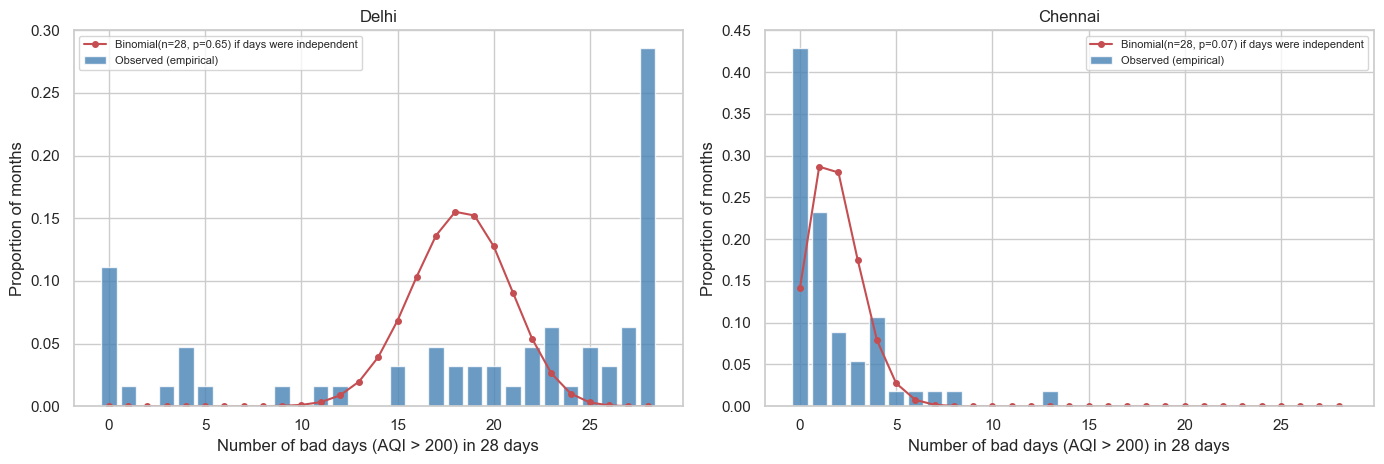

In [50]:
N, LIMIT = 28, 200            # a "month" = first 28 days of a calendar month; a bad day = AQI above 200 (Poor or worse)

def bad_days_per_month(city):
    s = df[df['City'] == city].set_index('Date')['AQI']
    bad = (s > LIMIT).astype(int)
    counts = []
    for _, b in bad.groupby([bad.index.year, bad.index.month]):
        first = b[b.index.day <= N]
        if len(first) == N: counts.append(first.sum())                   # only months with all 28 days present
    return np.array(counts)

rows, data = [], {}
for city in ['Delhi', 'Lucknow', 'Chennai', 'Bengaluru']:
    s = df[df['City'] == city].set_index('Date')['AQI'].asfreq('D')
    b = (s > LIMIT).astype(float).where(s.notna()); prev = b.shift(1)
    k = bad_days_per_month(city); p = (df.loc[df['City'] == city, 'AQI'] > LIMIT).mean()
    data[city] = (k, p)
    rows.append({'City': city, 'Months': len(k), 'p (bad day)': p, 'Expected bad days np': N * p,
                 'Binomial variance': N * p * (1 - p), 'Observed variance': k.var(ddof=1),
                 'P(bad | yesterday bad)': b[prev == 1].mean(), 'P(bad | yesterday not bad)': b[prev == 0].mean()})
q11 = pd.DataFrame(rows).set_index('City'); q11['Variance ratio'] = q11['Observed variance'] / q11['Binomial variance']
display(q11.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, city in zip(axes, ['Delhi', 'Chennai']):
    k, p = data[city]; x = np.arange(N + 1)
    ax.bar(x, np.bincount(k, minlength=N + 1) / len(k), color='steelblue', alpha=.8, label='Observed (empirical)')
    ax.plot(x, stats.binom.pmf(x, N, p), 'ro-', ms=4, label=f'Binomial(n={N}, p={p:.2f}) if days were independent')
    ax.set_xlabel(f'Number of bad days (AQI > {LIMIT}) in {N} days'); ax.set_ylabel('Proportion of months')
    ax.set_title(city); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What the output shows:**
- **Delhi:** p(bad day) = 0.65, so independent days would give about 18 bad days in 28 with variance 6.4. The observed variance is **101 (16 times larger)**. The bars pile up at **0 and 28**, with 11% of months having no bad day and about 29% having all 28 bad, while the Binomial curve expects almost none there.
- **Lucknow** 18 times larger; **Chennai and Bengaluru** about 3.5-3.8 times larger.
- **Streaks:** in Delhi, the chance of a bad day is **0.92 after a bad day** and **0.16 after a normal day** (Lucknow 0.89 vs 0.11; Chennai 0.49 vs 0.04).

**Answer and decision:** No. Bad days come in **long streaks**, so the conditions of the Binomial model (independent trials) fail. The days are strongly dependent, which has two consequences:
1. In Part 3, day-level tests overstate the evidence. We use city-level summaries for formal tests rather than treating daily AQI readings as independent observations.
2. In Part 4, rows are not independent, so we need a **time-ordered train/test split**, and yesterday's AQI will be a strong feature (Q15).

## Q12. Can we trust the ranking of cities by the share of Poor-or-worse days?
**Why it matters:** The cities have between 111 and 2,000 days of data. A city with 111 days can easily rank higher or lower than it "should" just by chance. A ranking without uncertainty is not a safe basis for a conclusion.

**Concept from class:** The share of bad days is a **statistic** calculated from a sample; a different sample would give a different value (L11). We simulate this with the **bootstrap**: resample each city's calendar-month blocks (keeping all observed days in a selected month together) 2,000 times, recompute the share each time, and take the middle 95% as an interval (empirical distribution of the statistic).

**Chart – what it is and why we use it:** An **interval (forest) plot**: one dot per city (observed share) with a line for the 95% block-bootstrap interval, and the number of days in the label. Where two intervals overlap, we cannot say that one city is really worse than the other. A bar chart of the shares would hide all uncertainty.

**Dependence adjustment:** Q11 shows serial clustering, so this uses month blocks rather than pretending individual days are independent. It still provides approximate uncertainty and cannot correct for missing years or changing coverage.

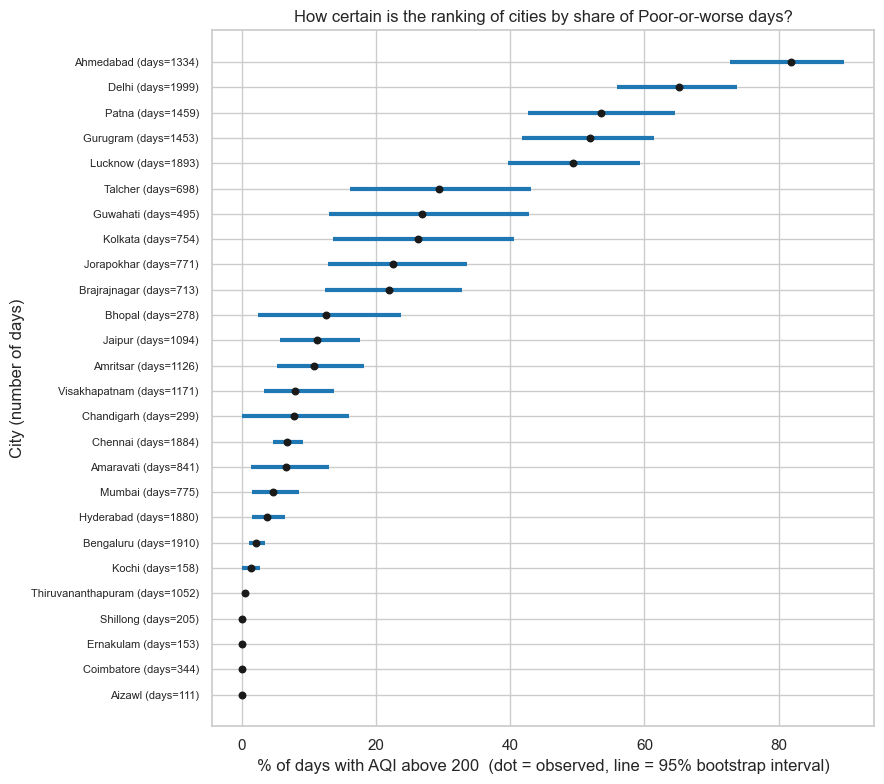

,Days,Months,p (%),Low (%),High (%),Interval width (points)
City,,,,,,
Ahmedabad,1334,51,81.9,72.8,89.7,16.9
Delhi,1999,67,65.1,55.9,73.7,17.8
Patna,1459,53,53.5,42.7,64.6,21.9
Gurugram,1453,55,51.8,41.7,61.4,19.7
Lucknow,1893,65,49.4,39.7,59.4,19.7
Talcher,698,30,29.4,16.1,43.2,27.1
Guwahati,495,18,26.9,13.0,42.8,29.8
Kolkata,754,27,26.3,13.6,40.5,26.9


,Days,Months,Interval width (points)
City,,,
Guwahati,495,18,29.769
Talcher,698,30,27.070
Kolkata,754,27,26.894
Patna,1459,53,21.934


In [51]:
B = 2000
rows = []
for city_name, g in df.groupby('City'):
    g = g.sort_values('Date').copy()
    g['YearMonth'] = g['Date'].dt.to_period('M')
    month_blocks = [block['AQI'].to_numpy() for _, block in g.groupby('YearMonth')]
    observed = (g['AQI'] > 200).mean()
    draws = np.empty(B)
    for b in range(B):
        picked = rng.integers(0, len(month_blocks), size=len(month_blocks))
        sample = np.concatenate([month_blocks[j] for j in picked])
        draws[b] = (sample > 200).mean()
    rows.append((city_name, len(g), g['YearMonth'].nunique(), observed, *np.percentile(draws, [2.5, 97.5])))
q12 = pd.DataFrame(rows, columns=['City', 'Days', 'Months', 'p', 'Low', 'High']).set_index('City').sort_values('p')

fig, ax = plt.subplots(figsize=(9, 8))
y = np.arange(len(q12))
ax.hlines(y, q12['Low'] * 100, q12['High'] * 100, color='tab:blue', lw=3)
ax.scatter(q12['p'] * 100, y, color='k', zorder=3, s=22)
ax.set_yticks(y); ax.set_yticklabels([f'{c} (days={n})' for c, n in zip(q12.index, q12['Days'])], fontsize=8)
ax.set_xlabel('% of days with AQI above 200  (dot = observed, line = 95% bootstrap interval)'); ax.set_ylabel('City (number of days)')
ax.set_title('How certain is the ranking of cities by share of Poor-or-worse days?')
plt.tight_layout(); plt.show()
q12['Interval width (points)'] = (q12['High'] - q12['Low']) * 100
display(q12.sort_values('p', ascending=False).assign(p=lambda x: x['p'] * 100, Low=lambda x: x['Low'] * 100, High=lambda x: x['High'] * 100).round(1).head(8).rename(columns={'p': 'p (%)', 'Low': 'Low (%)', 'High': 'High (%)'}))
display(q12.sort_values('Interval width (points)', ascending=False).round(3).head(4)[['Days', 'Months', 'Interval width (points)']])

**What the output shows:** The forest plot reports the observed Poor-or-worse share and calendar-month block-bootstrap intervals for each city. Compare interval widths alongside each city's number of observed days and months; shorter records usually have less precise estimates. The interval method preserves within-month runs but still cannot account for missing years or make city records representative of the same period.

**Answer and decision:** Use these intervals as approximate uncertainty bands, not as definitive pairwise city rankings. Since Q11 shows long bad-air streaks, block resampling is more appropriate than treating individual days as independent.

## Q13. Which unusual values could change the story, and how are they handled?

**Why it matters:** Sensor availability creates structured missingness, while extreme or internally inconsistent records can dominate averages, city rankings, and model errors. This checks patterned missingness, the impact of imputation, the highest reported AQI values, very high CO, PM2.5 > PM10 records, negative readings, and duplicates against the raw file. These checks flag records for sensitivity analysis; they do not prove the underlying sensor cause.

**Concept:** Data validation, robust summaries, and sensitivity analysis.

**Chart:** A bar chart of extreme AQI counts by city and a compact quality summary make concentration of anomalies visible without hiding them in pooled averages.

Raw data quality checks:


,Count
Exact duplicate rows,0
Duplicate city-date keys,0
Negative pollutant readings,0
PM2.5 > PM10 (paired records),256
AQI > 500,543
AQI > 1000,93
CO > 50,120


Maximum AQI by city:


,Max AQI
City,
Ahmedabad,2049.0
Guwahati,956.0
Gurugram,891.0
Amritsar,869.0
Hyderabad,737.0
Delhi,716.0
Lucknow,707.0
Patna,619.0


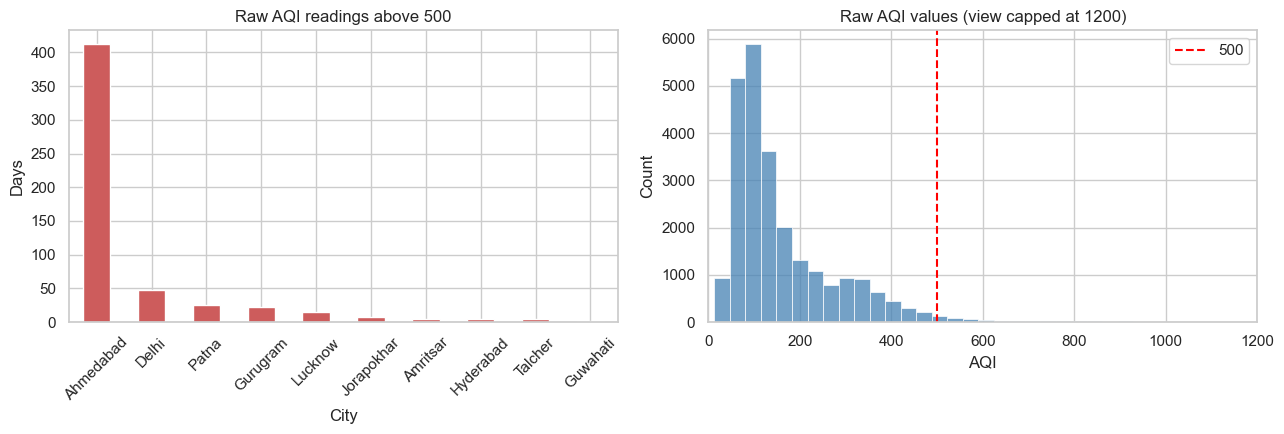

Cities with CO > 50: ['Ahmedabad']
Missingness by field (%):


,Missing %
Xylene,61.3
PM10,37.7
NH3,35.0
Toluene,27.2
Benzene,19.0
AQI,15.9
PM2.5,15.6
NOx,14.2
O3,13.6
SO2,13.1


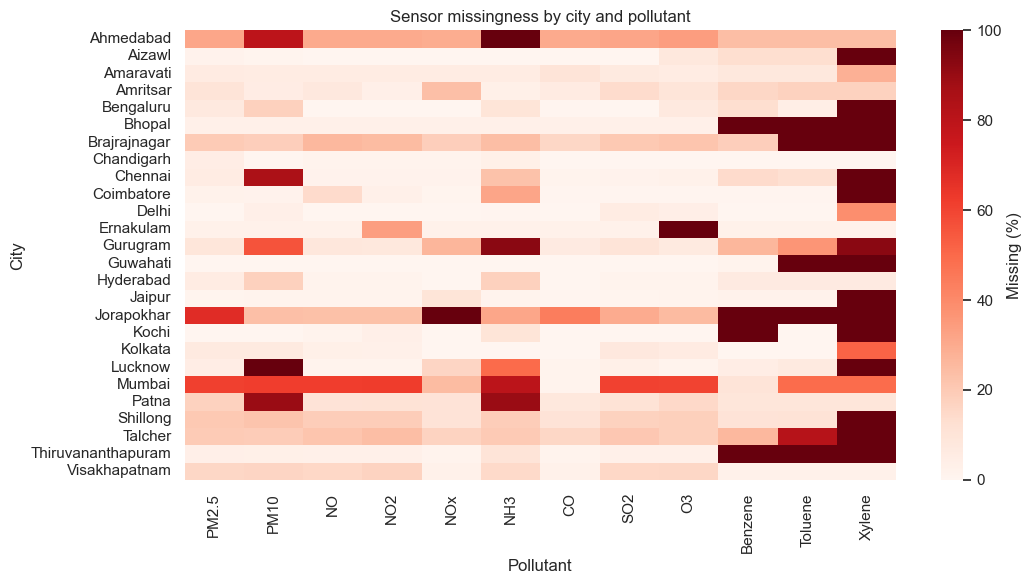

Correlation with AQI excluding Ahmedabad (real complete readings vs imputed clean data):


,Real complete readings,After imputation
PM2.5,0.89,0.88
PM10,0.90,0.74
AQI,1.00,1.00


In [52]:
raw_audit = pd.read_csv('city_day.csv', parse_dates=['Date'])
paired_pm = raw_audit.dropna(subset=['PM2.5','PM10'])
quality = pd.Series({
    'Exact duplicate rows': int(raw_audit.duplicated().sum()),
    'Duplicate city-date keys': int(raw_audit.duplicated(['City','Date']).sum()),
    'Negative pollutant readings': int((raw_audit[POLL] < 0).sum().sum()),
    'PM2.5 > PM10 (paired records)': int((paired_pm['PM2.5'] > paired_pm['PM10']).sum()),
    'AQI > 500': int((raw_audit['AQI'] > 500).sum()),
    'AQI > 1000': int((raw_audit['AQI'] > 1000).sum()),
    'CO > 50': int((raw_audit['CO'] > 50).sum()),
})
print('Raw data quality checks:'); display(quality.rename('Count').to_frame())
print('Maximum AQI by city:')
display(raw_audit.groupby('City')['AQI'].max().sort_values(ascending=False).head(8).rename('Max AQI').to_frame())
extremes = raw_audit[raw_audit['AQI'] > 500].groupby('City').size().sort_values(ascending=False)
fig, ax = plt.subplots(1,2,figsize=(13,4.5))
extremes.plot(kind='bar',ax=ax[0],color='indianred'); ax[0].set_title('Raw AQI readings above 500'); ax[0].set_ylabel('Days'); ax[0].tick_params(axis='x',rotation=45)
sns.histplot(raw_audit['AQI'].dropna(),bins=60,ax=ax[1],color='steelblue'); ax[1].axvline(500,color='red',ls='--',label='500'); ax[1].set_xlim(0,1200); ax[1].set_title('Raw AQI values (view capped at 1200)'); ax[1].set_xlabel('AQI'); ax[1].legend()
plt.tight_layout(); plt.show()
print('Cities with CO > 50:', sorted(raw_audit.loc[raw_audit['CO']>50,'City'].dropna().unique()))
# Missingness is clustered by sensor/city, so report it before interpreting filled data.
missing_pct = (raw_audit[POLL+['AQI']].isna().mean()*100).sort_values(ascending=False)
print('Missingness by field (%):'); display(missing_pct.rename('Missing %').to_frame().round(1))
miss_city = raw_audit.groupby('City')[POLL].apply(lambda x: x.isna().mean()*100)
fig,ax=plt.subplots(figsize=(11,6)); sns.heatmap(miss_city,annot=False,cmap='Reds',cbar_kws={'label':'Missing (%)'},ax=ax)
ax.set_title('Sensor missingness by city and pollutant'); ax.set_xlabel('Pollutant'); ax.set_ylabel('City'); plt.tight_layout(); plt.show()
raw_corr = raw_audit[raw_audit['City']!='Ahmedabad'].dropna(subset=['PM2.5','PM10','AQI'])[['PM2.5','PM10','AQI']].corr()['AQI']
filled_corr = df[df['City']!='Ahmedabad'][['PM2.5','PM10','AQI']].corr()['AQI']
print('Correlation with AQI excluding Ahmedabad (real complete readings vs imputed clean data):')
display(pd.DataFrame({'Real complete readings':raw_corr,'After imputation':filled_corr}).round(2))


**Answer and decision:** Missingness is patterned: Xylene is absent from about 61% of records and missingness clusters by city and sensor. With Ahmedabad excluded, the PM10-AQI correlation is stronger on real complete readings than after imputation (about 0.90 vs 0.74). There are no duplicate or negative readings, but 256 PM2.5/PM10 consistency flags and 543 AQI values above 500; CO > 50 is concentrated in Ahmedabad. Preserve and flag these records, report their counts, and compare results with/without Ahmedabad. Do not call AQI values erroneous without source documentation. This replaces a generic resampling simulation with data-specific quality checks.

## Q14. Does one number per city hide local hot-spots?
**Why it matters:** `city_day.csv` gives one AQI per city per day. Delhi has 37 stations, so a single figure may hide neighbourhoods with very different air, which matters for health advice and for the dashboard.

**Concept from class:** **Dispersion** (range, spread) (L10) and **data integration** (L8): we join the station file with the station list. To compare stations fairly we use L14's idea of comparing under the same conditions: each station is compared with the Delhi average **of the same day**, because stations started reporting in different years and a raw station average would mix time with place. Only days with at least 10 stations reporting are used.

**Chart – what it is and why we use it:** (1) A **bar chart of each station's average deviation** from the same-day Delhi average: bars to the right are hot-spots and bars to the left are cleaner places, sorted so that the extremes are obvious. (2) A **histogram of the daily range** (highest minus lowest station on the same day), which shows how big the disagreement is on a typical day, not just on average.

Days with >= 10 stations: 976 | correlation of city_day AQI with the average of stations: 1.000
Same-day gap between highest and lowest station -> median 198, 90th percentile 312 AQI points


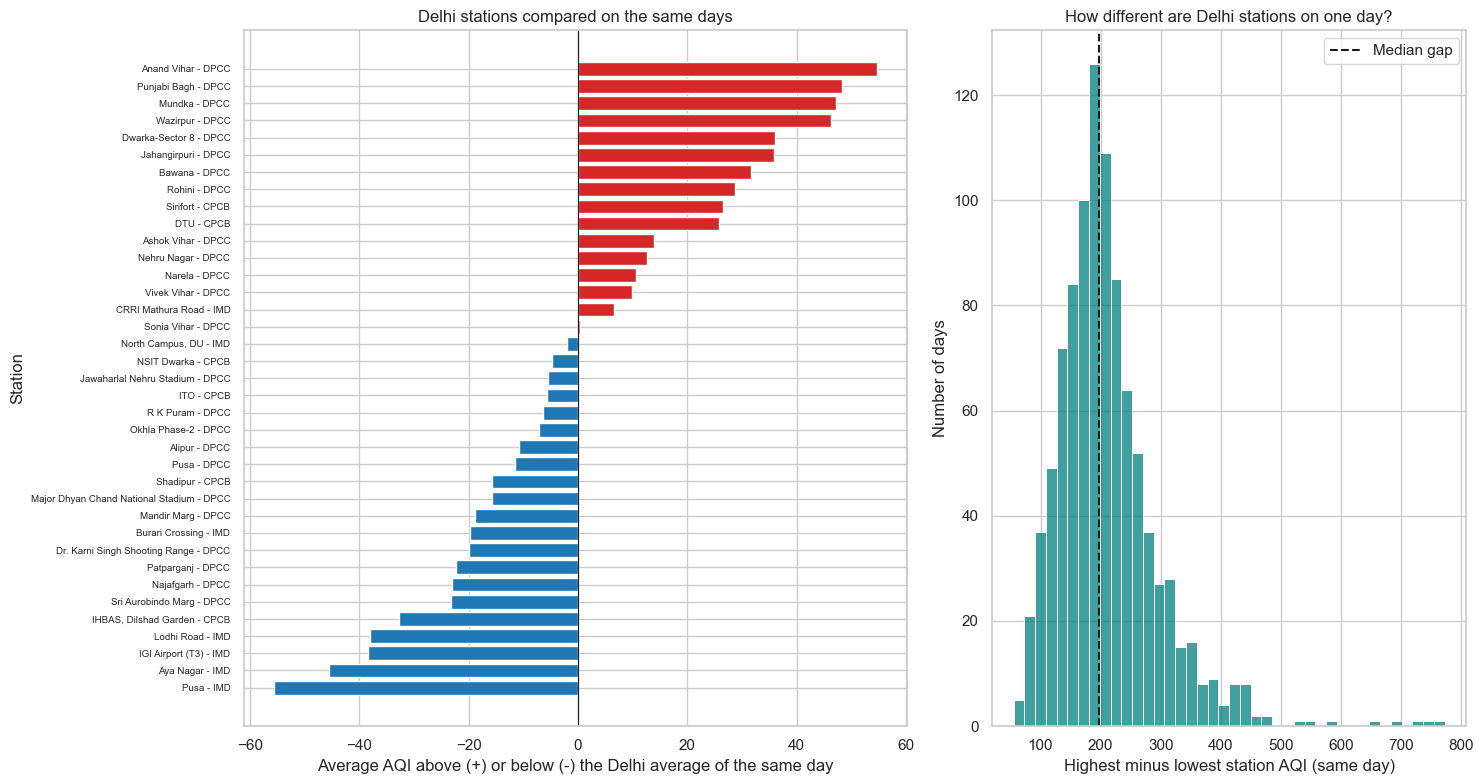

Highest: {'Punjabi Bagh - DPCC': 48.0, 'Anand Vihar - DPCC': 55.0}
Lowest : {'Pusa - IMD': -56.0, 'Aya Nagar - IMD': -46.0}

Average deviation by operating agency:
          avg deviation  stations
Operator                         
CPCB               -1.0         6
DPCC                9.0        24
IMD               -28.0         7


In [53]:
d14 = sd[sd['City'] == 'Delhi'].copy()
d14['Station'] = d14['StationName'].str.replace(', Delhi', '', regex=False)
daily = d14.groupby('Date')['AQI'].agg(Stations='count', Mean='mean', Lowest='min', Highest='max')
daily = daily[daily['Stations'] >= 10].copy()                      # only days when at least 10 stations reported
daily['Range'] = daily['Highest'] - daily['Lowest']

d14 = d14.merge(daily[['Mean']].rename(columns={'Mean': 'Delhi_mean'}), left_on='Date', right_index=True)
d14['Deviation'] = d14['AQI'] - d14['Delhi_mean']                   # station minus Delhi average of the SAME day
dev = d14.groupby('Station')['Deviation'].agg(['mean', 'count'])
dev = dev[dev['count'] >= 100].sort_values('mean')

city_aqi = df[df['City'] == 'Delhi'].set_index('Date')['AQI']
print('Days with >= 10 stations: %d | correlation of city_day AQI with the average of stations: %.3f' % (
      len(daily), daily['Mean'].corr(city_aqi.reindex(daily.index))))
print('Same-day gap between highest and lowest station -> median %.0f, 90th percentile %.0f AQI points' % (
      daily['Range'].median(), daily['Range'].quantile(.9)))

fig, axes = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={'width_ratios': [1.4, 1]})
axes[0].barh(dev.index, dev['mean'], color=['tab:red' if v > 0 else 'tab:blue' for v in dev['mean']])
axes[0].axvline(0, color='k', lw=.8); axes[0].tick_params(axis='y', labelsize=7)
axes[0].set_xlabel('Average AQI above (+) or below (-) the Delhi average of the same day'); axes[0].set_ylabel('Station')
axes[0].set_title('Delhi stations compared on the same days')
sns.histplot(daily['Range'], bins=40, color='teal', ax=axes[1])
axes[1].axvline(daily['Range'].median(), color='k', ls='--', label='Median gap')
axes[1].set_xlabel('Highest minus lowest station AQI (same day)'); axes[1].set_ylabel('Number of days')
axes[1].set_title('How different are Delhi stations on one day?'); axes[1].legend()
plt.tight_layout(); plt.show()
print('Highest:', dev['mean'].tail(2).round(0).to_dict()); print('Lowest :', dev['mean'].head(2).round(0).to_dict())
dev['Operator'] = dev.index.str.split(' - ').str[-1]
print('\nAverage deviation by operating agency:'); print(dev.groupby('Operator')['mean'].agg(['mean', 'count']).round(0).rename(columns={'mean': 'avg deviation', 'count': 'stations'}).to_string())

**What the output shows:**
- The city-file AQI tracks the same-day average of available Delhi station AQIs almost perfectly (correlation 1.000), consistent with an aggregated city record; correlation alone does not prove the exact aggregation formula.
- On the same day, the highest station is a **median of 198 AQI points** above the lowest (90th percentile: 312).
- **Hot-spots:** Anand Vihar (+55), Punjabi Bagh (+48), Mundka and Wazirpur (about +46 to +47). **Cleaner:** Pusa-IMD (-56) and Aya Nagar-IMD (-46).
- **By operating agency:** the 7 IMD stations average **-28**, the 6 CPCB stations -1 and the 24 DPCC stations +9.

**Answer and decision:** Yes, the city number **hides large local differences**: a typical day has a gap of about 200 AQI points between the worst and the cleanest station. The IMD stations all read lower, so part of the gap may be a difference of **equipment or agency** and not only geography. This data cannot separate the two. We use `city_day` for comparing cities, and the dashboard will include a **station-level view** for hot-spots.

## Q15. How much of today's AQI is already known from yesterday?
**Why it matters:** This decides how the ML problem should be framed. If tomorrow looks almost exactly like today, a simple "tomorrow = today" rule is a very strong baseline, and any model must beat it to be worth using.

**Concept from class:** **Covariance and correlation** (L10) between a variable and a *shifted copy of itself* (lag 1). Squaring the correlation (r²) gives the share of variation explained.

**Chart – what it is and why we use it:** (1) A **lag scatter** (yesterday on the x-axis, today on the y-axis) for Delhi, with the diagonal "no change" line: points on the line mean "same as yesterday", and the spread around it is what yesterday cannot predict. (2) A **bar chart of the lag-1 correlation for all cities**, to check that Delhi is not a special case. The calendar is filled first so that "yesterday" is always the real previous day.

Delhi: correlation between AQI today and AQI k days later: {1: np.float64(0.9), 2: np.float64(0.81), 3: np.float64(0.76), 7: np.float64(0.68), 14: np.float64(0.63), 30: np.float64(0.47)}


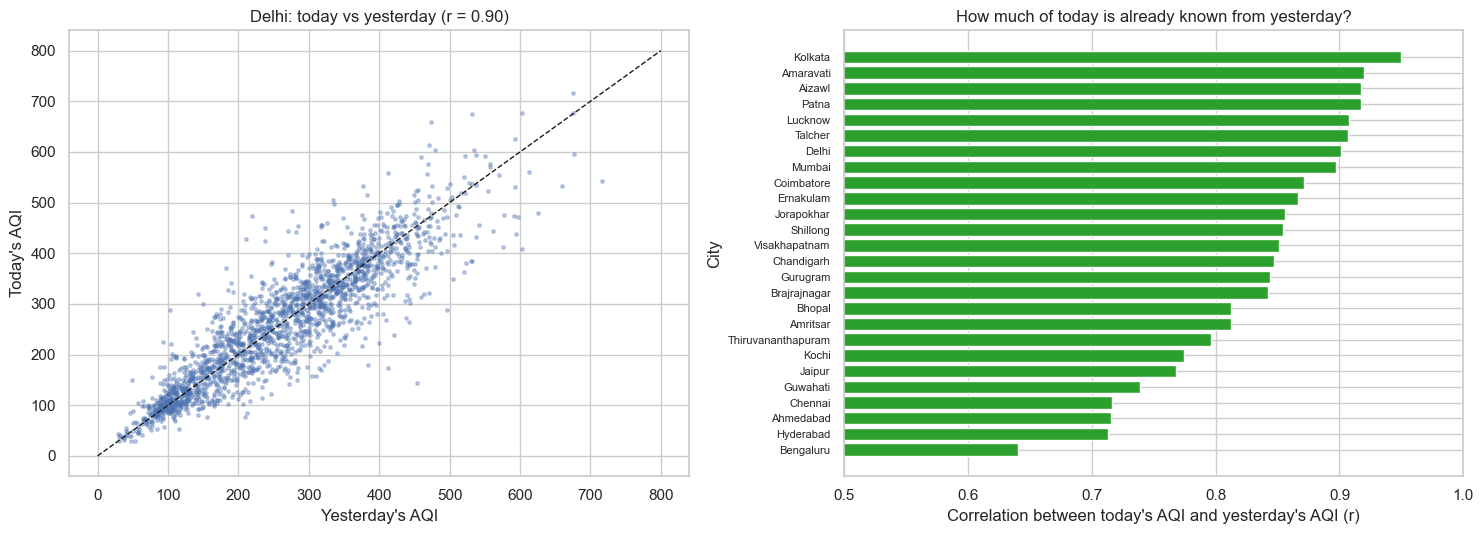

Lowest r: Bengaluru 0.64 | highest r: Kolkata 0.95 | median r 0.85 | median r^2 0.72


In [54]:
rows = []
for city, g in df.groupby('City'):
    s = g.set_index('Date')['AQI'].asfreq('D')                       # full calendar so that "yesterday" is really yesterday
    pairs = s.notna() & s.shift(1).notna()
    rows.append((city, pairs.sum(), s.corr(s.shift(1))))
q15 = pd.DataFrame(rows, columns=['City', 'Day pairs', 'r']).set_index('City').sort_values('r')

delhi = df[df['City'] == 'Delhi'].set_index('Date')['AQI'].asfreq('D')
lags = [1, 2, 3, 7, 14, 30]
print('Delhi: correlation between AQI today and AQI k days later:', {k: round(delhi.corr(delhi.shift(-k)), 2) for k in lags})

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].scatter(delhi.shift(1), delhi, s=6, alpha=.35)
axes[0].plot([0, 800], [0, 800], 'k--', lw=1)
axes[0].set_xlabel("Yesterday's AQI"); axes[0].set_ylabel("Today's AQI"); axes[0].set_title("Delhi: today vs yesterday (r = %.2f)" % q15.loc['Delhi', 'r'])
axes[1].barh(q15.index, q15['r'], color='tab:green'); axes[1].set_xlim(.5, 1)
axes[1].set_xlabel("Correlation between today's AQI and yesterday's AQI (r)"); axes[1].set_ylabel('City')
axes[1].set_title('How much of today is already known from yesterday?'); axes[1].tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()
print('Lowest r: %s %.2f | highest r: %s %.2f | median r %.2f | median r^2 %.2f' % (
      q15.index[0], q15['r'].iloc[0], q15.index[-1], q15['r'].iloc[-1], q15['r'].median(), (q15['r'] ** 2).median()))

**What the output shows:**
- **Delhi:** r = **0.90** at lag 1, then 0.81 (2 days), 0.76 (3), 0.68 (7), 0.63 (14) and 0.47 (30 days). The memory fades slowly.
- **All cities:** lag-1 r runs from **0.64 (Bengaluru) to 0.95 (Kolkata)**, with a median of 0.85. The median r² is **0.72**, so yesterday explains about 72% of the variation in today's AQI (81% in Delhi).

**Answer and decision:** **Most of today's AQI is already known from yesterday.** For Part 4 this means:
1. Frame the task as **predicting next-day AQI** and use **"tomorrow = today" as the baseline** to beat.
2. Add **lag features** and a **time-ordered split** (a random split would leak).
3. This is the same dependence we saw in Q11 (streaks) and is another reason for care with p-values in Part 3.

# SUMMARY – Decisions from Part 2 and what they feed into

| # | Answer in one line | Decision / use later |
|---|---|---|
| 1 | The mean overstates a typical day in most cities (pooled mean 166 vs median 118). Delhi is the exception. | Compare cities with the **median**. |
| 2 | Two kinds of problem: chronic (Delhi, Patna, Gurugram, Lucknow) and episodic (Guwahati, Kolkata, Amritsar). | Describe cities by **level and CV**. |
| 3 | Hyderabad, Amritsar, Guwahati and Chennai have rare extreme days (kurtosis 6-24); northern cities do not. | Use **MAE and log AQI** in Part 4. |
| 4 | A reconstruction from daily averages suggests PM2.5/PM10 often dominate; Ahmedabad is mostly CO-driven. The reconstruction is approximate. | Keep Ahmedabad separate and label the method approximate. |
| 5 | The PM2.5/PM10 ratio varies by season and AQI level in real paired readings. | Treat the ratio as descriptive; imputation can distort it. |
| 6 | PM2.5-PM10 (0.87), NO-NOx (0.71) and Toluene-Benzene (0.73) overlap. | **Select features**; drop NOx. |
| 7 | Winter is worse than monsoon in all 24 cities, from 6.2x (Guwahati) to 1.1x (Coimbatore). | Use **city/region x season**. |
| 8 | The decline is smaller in the fixed-city panel than in the pooled data; it is descriptive, not a tested causal trend. | Quote the panel and disclose its small set of cities. |
| 9 | Jan-Mar and Apr-Jun 2020 were lower than 2019; an extra Apr-Jun drop is not significant in the selected city-level paired t-test (p=0.172). | Describe as an observational A/B-style comparison, not a causal effect. |
| 10 | AQI index rises after Diwali in all 9 cities; city-level one-sample t-test p=0.0241. | Report an event-timed association, not proof of fireworks causation. |
| 11 | Bad days come in streaks (Delhi: 0.92 after a bad day vs 0.16 otherwise). | **Block / aggregate tests**; time-ordered split. |
| 12 | Month-block bootstrap intervals are much wider than day-wise intervals and overlap across several high-risk cities. | Use broad risk tiers, not precise ranks. |
| 13 | Sensor gaps are patterned, PM10 correlation changes after imputation, AQI has values above 500, and high CO is concentrated in Ahmedabad. | Document missingness and anomalies; compare results with/without Ahmedabad. |
| 14 | Delhi's stations differ by about 200 AQI points on the same day; IMD stations read lower. | Dashboard **station view**. |
| 15 | Yesterday explains about 72% of today (median city). | **Baseline = persistence**; add lag features. |

## Tests actually run in the completed notebook
| Question | Null hypothesis | Test and result | Interpretation |
|---|---|---|---|
| Winter vs monsoon AQI (Q16) | Mean paired city-median difference is zero. | Paired t-test across 22 cities: t(21)=5.736, raw p=1.08e-5, Holm p=3.23e-5; mean difference=102.4, 95% CI [65.3,139.6]. | Winter median AQI is higher in this observed city panel. |
| Lockdown-period comparison (Q17) | Mean city-level incremental 2020-vs-2019 percentage change is zero. | One-sample t-test over 18 city-level paired effects: t(17)=-1.425, raw and Holm p=0.172; 95% CI [-23.9,4.6]. | Not significant at 0.05; not a causal estimate. |
| Diwali event window (Q10) | Mean city-level increase is zero or below. | One-sided one-sample t-test over 9 city summaries: t(8)=2.330, raw p=0.0241, Holm p=0.0481; mean increase=74.1 index points. | Positive event-timed association; small city sample and observational design limit claims. |

Other exploratory questions are answered descriptively; they are not presented as statistically proven findings.

## Limits to remember
- The data is **observational**, so we found associations, not proven causes.
- Days are **dependent** (Q11), so day-level p-values will be too optimistic; we will use aggregates or block methods.
- Coverage is **unbalanced**, 2020 is half a year, and some cities have very few days.
- **Ahmedabad's CO** and the **filled values** (Part 1) remain data-quality limits.
- Q4 rebuilds AQI from daily averages; the official CPCB method uses 8-hour values for CO and O3.

# PART 3 - Statistical evidence

The tests below address three important questions from Part 2 using city-level paired summaries to reduce the impact of day-to-day dependence. Results support association statements, not causal claims. We report raw p-values and Holm-adjusted p-values across the three selected tests; decisions use family-wise alpha = 0.05. Effect sizes and confidence intervals accompany the p-values.

## Test 1 - Is winter AQI higher than monsoon AQI within the same cities?

**Hypotheses.** For each eligible city, calculate its winter median AQI minus its monsoon median AQI. H0: the mean paired difference across cities is zero. H1: the mean paired difference is not zero.

**Method and justification.** A two-sided paired t-test compares winter and monsoon medians within the same cities, so each city is its own match and day-level dependence does not inflate the sample size. We use 22 cities with at least 30 observations in each of the four seasons, and exclude Ahmedabad because of its unresolved AQI/CO anomaly. The test concerns the winter-versus-monsoon contrast; the four-season chart remains descriptive. The paired differences are summarized with a 95% confidence interval.


In [ ]:
from scipy import stats
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

season_order = ['Winter', 'Summer', 'Monsoon', 'Post-Monsoon']
season_src = df[df['City'] != 'Ahmedabad'].copy()
season_counts = season_src.groupby(['City', 'Season'])['AQI'].count().unstack()
eligible = season_counts.reindex(columns=season_order).dropna().index
eligible = season_counts.reindex(columns=season_order).loc[eligible].index[(season_counts.reindex(columns=season_order).loc[eligible] >= 30).all(axis=1)]
season_city = (season_src[season_src['City'].isin(eligible)]
               .groupby(['City', 'Season'])['AQI'].median().unstack()
               .reindex(columns=season_order).dropna())
winter_monsoon = stats.ttest_rel(season_city['Winter'], season_city['Monsoon'], alternative='two-sided')
difference = season_city['Winter'] - season_city['Monsoon']
ci95 = stats.t.interval(0.95, len(difference)-1, loc=difference.mean(), scale=stats.sem(difference))
n_city = len(season_city)
print(f'Cities included: {n_city}')
print(f'Paired t-test (winter - monsoon): t={winter_monsoon.statistic:.3f}, df={n_city-1}, p={winter_monsoon.pvalue:.6g}')
print(f'Mean paired difference={difference.mean():.1f} AQI points; 95% CI=({ci95[0]:.1f}, {ci95[1]:.1f})')

print('Median of city-level seasonal medians:')
display(season_city.median().reindex(season_order).rename('AQI median').to_frame())
ax = season_city.melt(var_name='Season', value_name='City median AQI').pipe(
    lambda x: __import__('seaborn').boxplot(data=x, x='Season', y='City median AQI', order=season_order, color='lightsteelblue'))
plt.title('Seasonal AQI medians within cities (Ahmedabad excluded)'); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

**Interpretation.** At alpha = 0.05, reject H0 if the two-sided p-value is below 0.05. The paired t-test shows whether winter and monsoon city medians differ on average; the sign of the mean difference and the confidence interval give the direction and magnitude. This is an association in the observed cities, not proof that season alone causes the AQI difference.


**Result.** Across 22 eligible cities, the mean paired winter-minus-monsoon difference is 102.4 AQI points (95% CI 65.3 to 139.6), t(21) = 5.736, raw p = 1.08e-5 and Holm-adjusted p = 3.23e-5. The interval is entirely above zero, supporting higher winter median AQI in this observed city panel.


## Test 2 - A/B-style comparison of 2020 lockdown months against 2019

**Question / hypotheses.** Did AQI fall more in Apr-Jun 2020 (the lockdown period) than the pre-lockdown 2020-vs-2019 change in Jan-Mar? H0: the mean city-level extra change is zero. H1: it is not zero.

**Method and justification.** For each city with sufficient data, calculate matched 2020-vs-2019 percentage changes for Jan-Mar and Apr-Jun, then subtract the pre-period change from the lockdown-period change. A two-sided one-sample t-test tests whether the mean of these paired city-level extra changes differs from zero. Each city contributes one paired effect, rather than treating daily readings as independent. This is an observational A/B-style comparison, not a randomized experiment; weather and other year-to-year differences remain possible explanations.


Cities included: 18
Median Jan-Mar 2020-vs-2019 change: -21.6%
Median Apr-Jun 2020-vs-2019 change: -33.0%
Mean extra change during Apr-Jun: -9.7 percentage points; paired-effects t=-1.425, df=17, p=0.17223
95% CI for mean extra change: (-23.9, 4.6) percentage points
Cities with a larger percentage drop during lockdown: 11 / 18


,City,Jan-Mar change (%),Apr-Jun change (%),Extra change (pp)
7,Guwahati,22.831050,-33.783784,-56.614834
1,Amritsar,15.428571,-31.730769,-47.159341
5,Delhi,-2.400000,-40.191388,-37.791388
12,Lucknow,-16.232465,-48.633880,-32.401415
6,Gurugram,-7.200000,-37.198068,-29.998068
13,Mumbai,-4.498270,-32.222222,-27.723952
9,Jaipur,-3.508772,-26.400000,-22.891228
2,Bengaluru,-16.299559,-37.735849,-21.436290
17,Visakhapatnam,-23.015873,-37.735849,-14.719976
8,Hyderabad,-27.586207,-35.416667,-7.830460


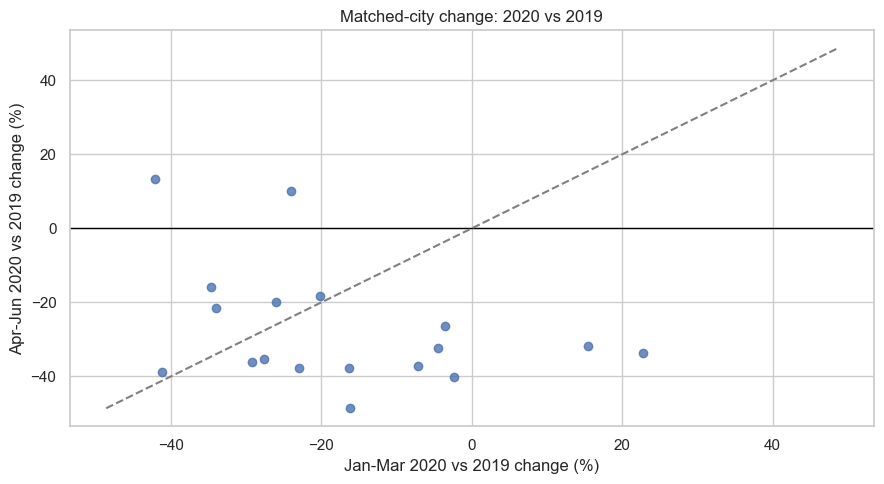

In [56]:
raw_lock = pd.read_csv('city_day.csv', parse_dates=['Date'])
if not pd.api.types.is_datetime64_any_dtype(raw_lock['Date']): raw_lock['Date'] = pd.to_datetime(raw_lock['Date'])
raw_lock['Year'] = raw_lock['Date'].dt.year; raw_lock['Month'] = raw_lock['Date'].dt.month
periods = {'pre': (1,3), 'lock': (4,6)}
lock = raw_lock[(raw_lock['City'] != 'Ahmedabad') & raw_lock['Year'].isin([2019,2020])].dropna(subset=['AQI'])
period_medians = lock.groupby(['City','Year']).apply(lambda x: pd.Series({
    'pre': x.loc[x['Month'].between(1,3),'AQI'].median(),
    'lock': x.loc[x['Month'].between(4,6),'AQI'].median(),
    'n_pre': x['Month'].between(1,3).sum(), 'n_lock': x['Month'].between(4,6).sum()}), include_groups=False).unstack('Year')
# Keep cities represented in every year/period with sufficient daily coverage.
valid = period_medians.dropna()
valid = valid[(valid[( 'n_pre', 2019)] >= 30) & (valid[( 'n_pre', 2020)] >= 30) & (valid[( 'n_lock', 2019)] >= 30) & (valid[( 'n_lock', 2020)] >= 30)]
pre_delta = ((valid[('pre',2020)] - valid[('pre',2019)]) / valid[('pre',2019)] * 100)
lock_delta = ((valid[('lock',2020)] - valid[('lock',2019)]) / valid[('lock',2019)] * 100)
effect = (lock_delta - pre_delta).dropna().to_numpy()
obs = effect.mean()
lockdown_test = stats.ttest_1samp(effect, popmean=0, alternative='two-sided')
ci95 = stats.t.interval(0.95, len(effect)-1, loc=obs, scale=stats.sem(effect))
print(f'Cities included: {len(effect)}')
print(f'Median Jan-Mar 2020-vs-2019 change: {np.median(pre_delta):.1f}%')
print(f'Median Apr-Jun 2020-vs-2019 change: {np.median(lock_delta):.1f}%')
print(f'Mean extra change during Apr-Jun: {obs:.1f} percentage points; paired-effects t={lockdown_test.statistic:.3f}, df={len(effect)-1}, p={lockdown_test.pvalue:.6g}')
print(f'95% CI for mean extra change: ({ci95[0]:.1f}, {ci95[1]:.1f}) percentage points')
print(f'Cities with a larger percentage drop during lockdown: {(effect < 0).sum()} / {len(effect)}')
lock_effects = pd.DataFrame({'City': valid.index, 'Jan-Mar change (%)': pre_delta.values, 'Apr-Jun change (%)': lock_delta.values, 'Extra change (pp)': effect}).sort_values('Extra change (pp)')
display(lock_effects)
plt.figure(figsize=(9,5)); plt.axhline(0,color='black',lw=1)
plt.scatter(lock_effects['Jan-Mar change (%)'], lock_effects['Apr-Jun change (%)'], alpha=.8)
lim=max(abs(lock_effects[['Jan-Mar change (%)','Apr-Jun change (%)']].to_numpy()).max(),1); plt.plot([-lim,lim],[-lim,lim],'--',color='gray')
plt.xlabel('Jan-Mar 2020 vs 2019 change (%)'); plt.ylabel('Apr-Jun 2020 vs 2019 change (%)')
plt.title('Matched-city change: 2020 vs 2019'); plt.tight_layout(); plt.show()

**Interpretation.** A negative extra change means AQI fell further in Apr-Jun than the Jan-Mar year-over-year difference. Use the paired-effects t-test p-value and 95% confidence interval to assess evidence against a zero mean difference at alpha = 0.05, and report how many cities share the direction. Do not interpret this estimate as a standalone causal lockdown effect.


**Result.** For 18 cities, the median 2020-versus-2019 change is -21.6% in Jan-Mar and -33.0% in Apr-Jun; 11 of 18 cities have a larger percentage drop in Apr-Jun. The mean incremental change is -9.7 percentage points, t(17) = -1.425, raw and Holm-adjusted p = 0.172, 95% CI -23.9 to 4.6. Since the interval includes zero and p > 0.05, this selected test does not establish an additional mean reduction. The comparison is observational and does not show that lockdown caused the change.


# PART 4 - Next-day AQI linear regression

**Objective.** Predict the next calendar day's continuous AQI for each city from information available the previous day. The faculty requires a linear or logistic regressor; because AQI is numeric, we use Linear Regression. We compare against the persistence baseline (tomorrow = today) using a chronological 2019 validation period for feature selection and a 2020 final holdout. Missing predictor values are imputed within a training-fitted pipeline.


,Feature set,MAE,RMSE,R2
0,Core AQI/pollutants,29.804,56.121,0.827
1,All available lag pollutants,30.240,56.184,0.827


Selected on 2019 validation by MAE: Core AQI/pollutants
Train rows: 19,987 | Test rows: 4,356 | Test dates: 2020-01-01 to 2020-07-01
Holdout error metrics (lower is better):


,Model,MAE,RMSE,MAPE (%)
0,Persistence (tomorrow = today),19.348,41.138,15.741
1,Linear Regression,22.363,37.359,22.622


Additional fit and bias metrics: R2 is higher-is-better; mean error is actual minus prediction (positive = underprediction).


,Model,R2,Mean error (actual - prediction)
0,Persistence (tomorrow = today),0.758,-0.652
1,Linear Regression,0.801,-8.412


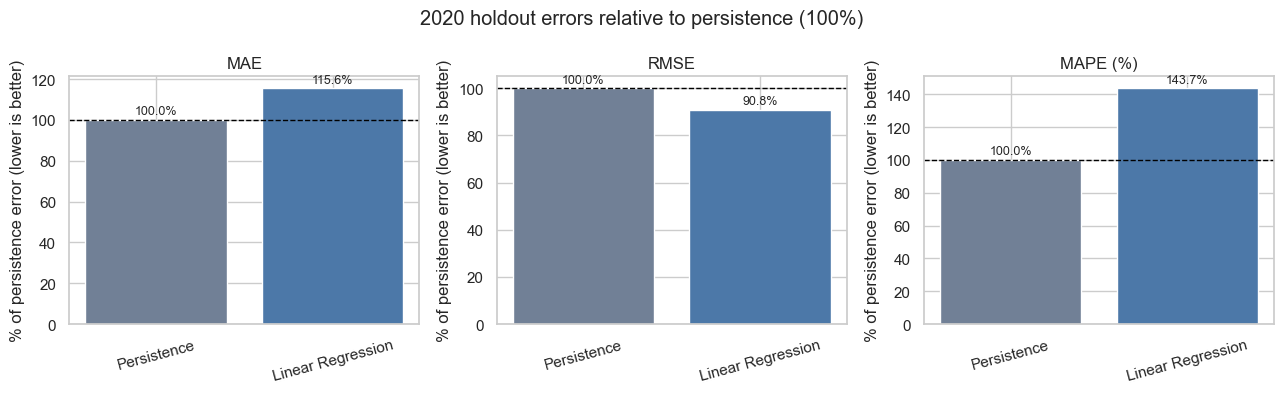

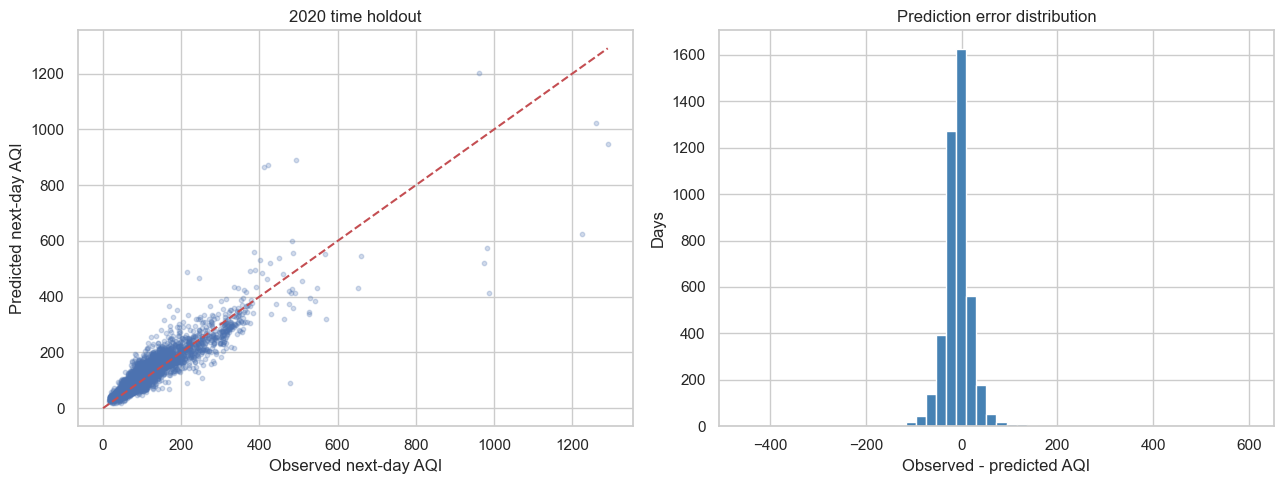

Highest test MAE by city:


,Days,MAE
City,,
Ahmedabad,172,88.55
Lucknow,183,38.34
Guwahati,183,33.88
Delhi,183,27.51
Gurugram,183,26.51
Jorapokhar,159,25.84
Patna,183,24.44
Brajrajnagar,108,22.73


Test error by observed AQI range:


,Days,Mean residual,MAE
AQI band,,,
"(-0.001, 50.0]",520,-12.69,14.56
"(50.0, 100.0]",1927,-11.11,16.61
"(100.0, 200.0]",1457,-12.21,24.07
"(200.0, 300.0]",280,11.60,35.90
"(300.0, 400.0]",134,21.44,39.57
"(400.0, 500.0]",21,-36.83,148.59
"(500.0, 1000.0]",14,187.29,221.68
"(1000.0, 2500.0]",3,394.44,394.44


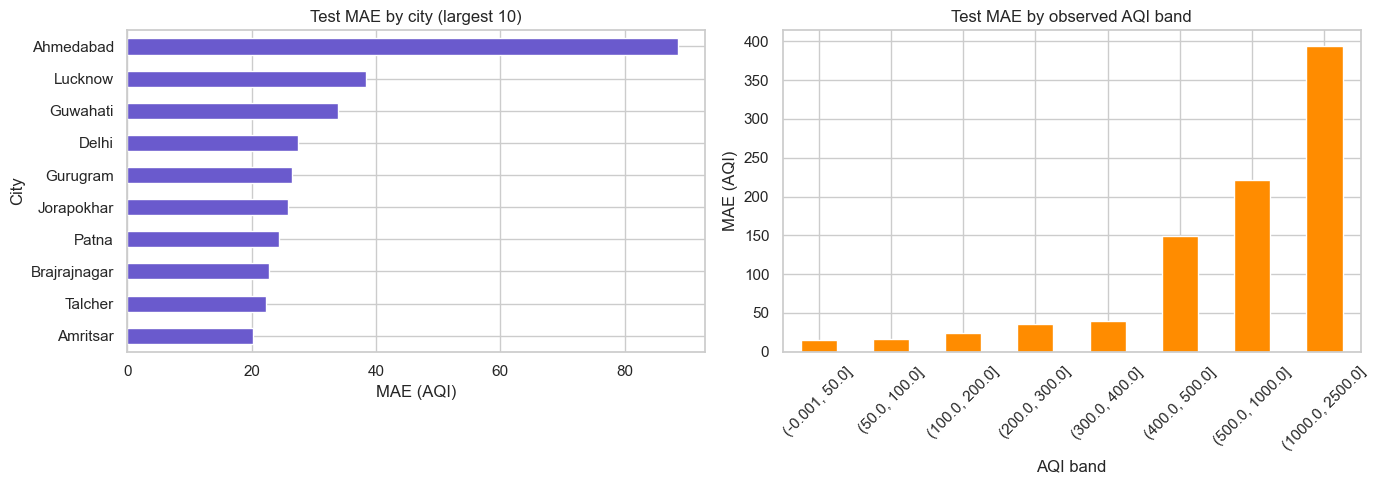

In [57]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

raw_model = pd.read_csv('city_day.csv', parse_dates=['Date'])
raw_model = raw_model.sort_values(['City','Date']).copy()
# Exclude Xylene (too much missingness) and NOx (overlaps with NO and NO2).
lag_cols = ['AQI'] + [c for c in POLL if c in raw_model.columns and c not in ('Xylene','NOx')]
prev = raw_model[['City','Date'] + lag_cols].copy()
prev['Date'] = prev['Date'] + pd.Timedelta(days=1)
prev = prev.rename(columns={c: 'prev_'+c for c in lag_cols})
target = raw_model[['City','Date','AQI']].dropna(subset=['AQI']).rename(columns={'AQI':'target_AQI'})
model_data = target.merge(prev, on=['City','Date'], how='left')
model_data = model_data[model_data['prev_AQI'].notna()].copy()
model_data['Month'] = model_data['Date'].dt.month.astype(str)
model_data = model_data.sort_values('Date')
numeric_all = ['prev_'+c for c in lag_cols]
core_features = ['prev_AQI','prev_PM2.5','prev_PM10','prev_NO2','prev_CO']
categorical = ['City','Month']
feature_sets = {'Core AQI/pollutants':core_features, 'All available lag pollutants':numeric_all}
validation_train = model_data[model_data['Date'] < '2019-01-01'].copy()
validation = model_data[(model_data['Date'] >= '2019-01-01') & (model_data['Date'] < '2020-01-01')].copy()

def make_linear_model(numeric_features):
    preprocess = ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler()), numeric_features),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical)])
    return make_pipeline(preprocess, LinearRegression())

# Use 2019 only for feature selection; keep 2020 as a final chronological holdout.
validation_rows = []
for name, features in feature_sets.items():
    candidate = make_linear_model(features)
    candidate.fit(validation_train[features+categorical], validation_train['target_AQI'])
    val_prediction = candidate.predict(validation[features+categorical])
    validation_rows.append({'Feature set':name, 'MAE':mean_absolute_error(validation['target_AQI'],val_prediction),
                            'RMSE':mean_squared_error(validation['target_AQI'],val_prediction)**0.5,
                            'R2':r2_score(validation['target_AQI'],val_prediction)})
validation_metrics = pd.DataFrame(validation_rows).sort_values('MAE')
display(validation_metrics.round(3))
selected_features = feature_sets[validation_metrics.iloc[0]['Feature set']]
print(f"Selected on 2019 validation by MAE: {validation_metrics.iloc[0]['Feature set']}")

train = model_data[model_data['Date'] < '2020-01-01'].copy()
test = model_data[model_data['Date'] >= '2020-01-01'].copy()
model = make_linear_model(selected_features)
X_train, y_train = train[selected_features+categorical], train['target_AQI']
X_test, y_test = test[selected_features+categorical], test['target_AQI']
model.fit(X_train,y_train)
pred = model.predict(X_test)
persist = test['prev_AQI'].to_numpy()
mape = lambda actual, estimate: np.mean(np.abs((actual-estimate)/actual))*100
metrics = pd.DataFrame([
    {'Model':'Persistence (tomorrow = today)','MAE':mean_absolute_error(y_test,persist),'RMSE':mean_squared_error(y_test,persist)**0.5,'R2':r2_score(y_test,persist),'MAPE (%)':mape(y_test.to_numpy(),persist),'Mean error (actual - prediction)':np.mean(y_test.to_numpy()-persist)},
    {'Model':'Linear Regression','MAE':mean_absolute_error(y_test,pred),'RMSE':mean_squared_error(y_test,pred)**0.5,'R2':r2_score(y_test,pred),'MAPE (%)':mape(y_test.to_numpy(),pred),'Mean error (actual - prediction)':np.mean(y_test.to_numpy()-pred)}])
print(f'Train rows: {len(train):,} | Test rows: {len(test):,} | Test dates: {test.Date.min().date()} to {test.Date.max().date()}')
print('Holdout error metrics (lower is better):')
display(metrics[['Model','MAE','RMSE','MAPE (%)']].round(3))
print('Additional fit and bias metrics: R2 is higher-is-better; mean error is actual minus prediction (positive = underprediction).')
display(metrics[['Model','R2','Mean error (actual - prediction)']].round(3))

# Compare error metrics on a common relative scale; 100% is the persistence error.
error_columns = ['MAE','RMSE','MAPE (%)']
baseline_errors = metrics.loc[metrics['Model'].eq('Persistence (tomorrow = today)'), error_columns].iloc[0]
relative_errors = metrics.set_index('Model')[error_columns].div(baseline_errors).mul(100)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, metric_name in zip(axes, error_columns):
    values = relative_errors[metric_name]
    bars = ax.bar(['Persistence','Linear Regression'], values.values, color=['#718096','#4c78a8'])
    ax.axhline(100, color='black', linestyle='--', linewidth=1)
    ax.set_title(metric_name)
    ax.set_ylabel('% of persistence error (lower is better)')
    ax.tick_params(axis='x', rotation=15)
    for bar, value in zip(bars, values.values):
        ax.annotate(f'{value:.1f}%', (bar.get_x()+bar.get_width()/2, bar.get_height()), xytext=(0,4), textcoords='offset points', ha='center', fontsize=9)
fig.suptitle('2020 holdout errors relative to persistence (100%)')
plt.tight_layout()
plt.show()

results = test[['City','Date','target_AQI']].copy(); results['Prediction']=pred; results['Persistence']=persist; results['Residual']=results['target_AQI']-results['Prediction']
fig,ax=plt.subplots(1,2,figsize=(13,5))
ax[0].scatter(y_test,pred,s=10,alpha=.25); lim=max(y_test.max(),pred.max()); ax[0].plot([0,lim],[0,lim],'r--'); ax[0].set(xlabel='Observed next-day AQI',ylabel='Predicted next-day AQI',title='2020 time holdout')
ax[1].hist(results['Residual'],bins=50,color='steelblue'); ax[1].set(xlabel='Observed - predicted AQI',ylabel='Days',title='Prediction error distribution')
plt.tight_layout(); plt.show()
results['AQI band'] = pd.cut(results['target_AQI'], bins=[0,50,100,200,300,400,500,1000,2500], include_lowest=True)
city_error = results.groupby('City').agg(Days=('Residual','size'), MAE=('Residual',lambda x: x.abs().mean())).sort_values('MAE',ascending=False)
band_error = results.groupby('AQI band', observed=False)['Residual'].agg(['count','mean',lambda x: x.abs().mean()])
band_error.columns=['Days','Mean residual','MAE']
print('Highest test MAE by city:'); display(city_error.head(8).round(2))
print('Test error by observed AQI range:'); display(band_error.round(2))
fig,ax=plt.subplots(1,2,figsize=(14,5))
city_error.head(10).sort_values('MAE').plot(kind='barh',y='MAE',ax=ax[0],color='slateblue',legend=False); ax[0].set_title('Test MAE by city (largest 10)'); ax[0].set_xlabel('MAE (AQI)')
band_error['MAE'].dropna().plot(kind='bar',ax=ax[1],color='darkorange'); ax[1].set_title('Test MAE by observed AQI band'); ax[1].set_ylabel('MAE (AQI)'); ax[1].tick_params(axis='x',rotation=45)
plt.tight_layout(); plt.show()


## Why Linear Regression, and how should it be interpreted?

**Model choice.** AQI is continuous, so Linear Regression directly predicts the numeric target. Logistic Regression is intended for categories such as AQI bands and would discard the exact AQI value. Linear Regression is easy to explain, but it assumes additive linear effects and is sensitive to extreme observations and correlated predictors.

**Use of analysis insights.** The seasonal test found higher winter than monsoon AQI within cities. Target month is already in the model and represents seasonal timing; adding a separate Season category produced no improvement in the linear validation comparison because Season is determined by Month, so we retain Month only. The lockdown comparison was not significant, so no lockdown flag is added. The Diwali association has only nine city summaries, and the 2020 holdout ends before Diwali, so a Diwali feature cannot be properly evaluated. P-values are not model inputs.

**Feature selection and leakage control.** On the chronological 2019 validation data, the compact lag set (yesterday's AQI, PM2.5, PM10, NO2, and CO) had lower MAE than using every available pollutant lag. NOx is excluded because it overlaps with NO and NO2; Xylene is excluded for missingness. City and target month are one-hot encoded. The 2020 period remains untouched until final evaluation. Numeric predictors are imputed and standardized within the training pipeline.

**Evaluation and diagnostics.** The holdout comparison reports MAE, RMSE, and MAPE as error metrics, plus R2 and mean signed error (actual - prediction) as complementary fit/bias metrics. Lower error is better; positive signed error means underprediction on average. The relative-error chart scales each error metric to the persistence baseline at 100%, so metrics with different units can be compared without treating their raw values as equivalent. The observed-vs-predicted plot, residual histogram, city MAE chart, and AQI-band table/plot diagnose calibration, bias, and where errors concentrate. Linear Regression lowers RMSE and raises R2 relative to persistence, but its MAE and MAPE are higher; it is therefore not uniformly better and should not be presented as such.


# PART 5 - Power BI / Tableau handoff

The files below are prepared for importing into Power BI or Tableau. Use `Date` as the date key and `City` as the city dimension key. The city fact is one row per city-day; the station fact is one row per station-day. The accompanying guide lists suggested relationships and visuals. A native PBIX/TWB dashboard file must be assembled in the BI application.

In [58]:
from pathlib import Path
from IPython.display import display

out = Path('.')
# BI-friendly fact tables and a small city dimension.
city_bi = df.copy()
city_bi.to_csv(out/'powerbi_city_daily.csv', index=False)
station_bi = sd.copy()
station_bi.to_csv(out/'powerbi_station_daily.csv', index=False)
city_dim = (df[['City','State','Region']].drop_duplicates().sort_values('City'))
city_dim.to_csv(out/'powerbi_city_dimension.csv', index=False)
stations.to_csv(out/'powerbi_station_dimension.csv', index=False)
print('Created BI files:')
for f in ['powerbi_city_daily.csv','powerbi_station_daily.csv','powerbi_city_dimension.csv','powerbi_station_dimension.csv']:
    print(f, f'{(out/f).stat().st_size:,} bytes')
print('City daily grain:', city_bi.shape, '| station daily grain:', station_bi.shape)
results.to_csv(out/'powerbi_next_day_predictions.csv', index=False)
metrics.to_csv(out/'model_evaluation_metrics.csv', index=False)

Created BI files:
powerbi_city_daily.csv 9,487,720 bytes
powerbi_station_daily.csv 13,053,123 bytes
powerbi_city_dimension.csv 704 bytes
powerbi_station_dimension.csv 14,466 bytes
City daily grain: (24850, 36) | station daily grain: (87025, 21)


## Dashboard build guide

**Suggested report pages**
1. **National overview:** AQI median, share of Poor-or-worse days, daily AQI trend, city map or region comparison; slicers for date, city, region, season, and AQI category.
2. **Seasonality and city comparison:** city median AQI and bad-day share, monthly/seasonal chart, city coverage counts; include a note that coverage is unequal and Ahmedabad is anomalous.
3. **Station hotspots:** Delhi station-level AQI and same-day station spread; show station counts and agency where available.
4. **Forecast evaluation:** observed versus predicted next-day AQI and residual distribution, using the regression output table if imported.

**Relationships:** `powerbi_city_daily[City]` -> `powerbi_city_dimension[City]`; `powerbi_station_daily[StationId]` -> `powerbi_station_dimension[StationId]`. Create a calendar table related to each fact table's `Date`. Avoid relating city and station fact tables directly.

**Core measures:** `Median AQI = MEDIAN(powerbi_city_daily[AQI])`; `Poor-or-worse days = CALCULATE(COUNTROWS(powerbi_city_daily), powerbi_city_daily[AQI] > 200)`; `Days = COUNTROWS(powerbi_city_daily)`; `Poor-or-worse share = DIVIDE([Poor-or-worse days],[Days])`. Add a coverage card using distinct dates and cities.

**Interpretation notes:** show medians or category shares alongside means; label 2020 as partial; surface data coverage in every comparison; and include a visible note that AQI data are observational and Ahmedabad has an unresolved CO anomaly.

## Q16. Is AQI different on weekends and weekdays?

**Hypotheses:** H0: the mean city-level difference (weekend mean AQI minus weekday mean AQI) is zero. H1: the mean difference is not zero.

**Method:** For each city, calculate mean AQI separately for weekdays and weekends. Exclude Ahmedabad because of its unresolved AQI/CO anomaly, and require at least 30 recorded days in both groups. A paired t-test compares the city-level means across 25 cities.

**Result:** Weekends average 129.0 AQI and weekdays 131.0 AQI; the mean paired difference is -2.0 points (95% CI -3.1 to -0.9), t(24) = -3.625, raw p = 0.00135. This is a small difference, with weekday AQI higher on average in these cities. The plot connects weekday and weekend means for each city. The comparison is descriptive and does not explain why the averages differ.


Cities: 25 | mean difference (weekend - weekday): -1.99 | 95% CI: (-3.12, -0.86)
One-sample t-test on city differences: t(24) = -3.625, p = 0.00135


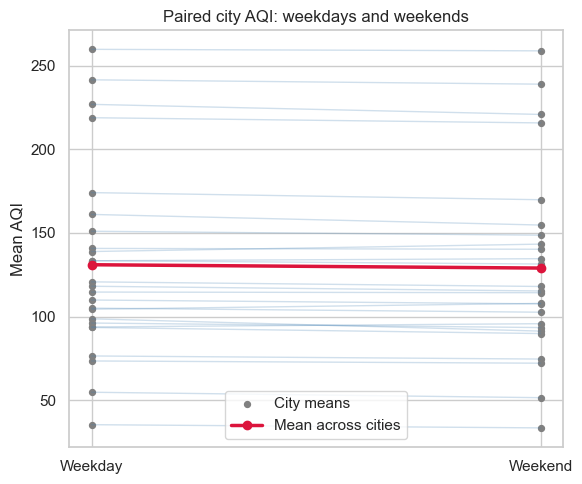

In [63]:
week_data = df[df['City'] != 'Ahmedabad'].copy()
week_data['Day type'] = np.where(week_data['Date'].dt.dayofweek >= 5, 'Weekend', 'Weekday')
week_counts = week_data.groupby(['City', 'Day type'])['AQI'].count().unstack()
week_means = week_data.groupby(['City', 'Day type'])['AQI'].mean().unstack()
week_cities = week_counts.dropna().index[(week_counts.dropna()['Weekday'] >= 30) & (week_counts.dropna()['Weekend'] >= 30)]
week_means = week_means.loc[week_cities, ['Weekday', 'Weekend']]
week_diff = week_means['Weekend'] - week_means['Weekday']
week_test = stats.ttest_1samp(week_diff, 0)
week_ci = stats.t.interval(0.95, len(week_diff)-1, loc=week_diff.mean(), scale=stats.sem(week_diff))
print(f'Cities: {len(week_diff)} | mean difference (weekend - weekday): {week_diff.mean():.2f} | 95% CI: ({week_ci[0]:.2f}, {week_ci[1]:.2f})')
print(f'One-sample t-test on city differences: t({len(week_diff)-1}) = {week_test.statistic:.3f}, p = {week_test.pvalue:.5f}')
fig, ax = plt.subplots(figsize=(6, 5))
for _, row in week_means.iterrows(): ax.plot([0, 1], [row['Weekday'], row['Weekend']], color='steelblue', alpha=0.25, linewidth=1)
ax.scatter([0]*len(week_means), week_means['Weekday'], color='gray', s=18, label='City means')
ax.scatter([1]*len(week_means), week_means['Weekend'], color='gray', s=18)
ax.plot([0, 1], [week_means['Weekday'].mean(), week_means['Weekend'].mean()], color='crimson', marker='o', linewidth=2.5, label='Mean across cities')
ax.set_xticks([0, 1], ['Weekday', 'Weekend']); ax.set_ylabel('Mean AQI'); ax.set_title('Paired city AQI: weekdays and weekends'); ax.legend()
plt.tight_layout(); plt.show()


## Q17. Is winter AQI higher than summer AQI within the same cities?

**Hypotheses:** H0: the mean city-level difference (winter median AQI minus summer median AQI) is zero. H1: the mean difference is not zero.

**Method:** For each city, calculate winter and summer median AQI. Exclude Ahmedabad because of its unresolved AQI/CO anomaly, and require at least 30 observations in both seasons. A paired t-test compares the city-level seasonal medians across 24 cities.

**Result:** The mean paired difference is 67.2 AQI points (95% CI 41.1 to 93.2), t(23) = 5.337, raw p = 0.0000203. The interval is above zero, supporting higher winter median AQI in this observed city panel. The plot connects the winter and summer medians for each city. This is an association in the observed data, not proof that season alone causes the difference.


Cities: 24 | mean winter - summer difference: 67.2 | 95% CI: (41.1, 93.2)
Paired t-test: t(23) = 5.337, p = 2.02793e-05


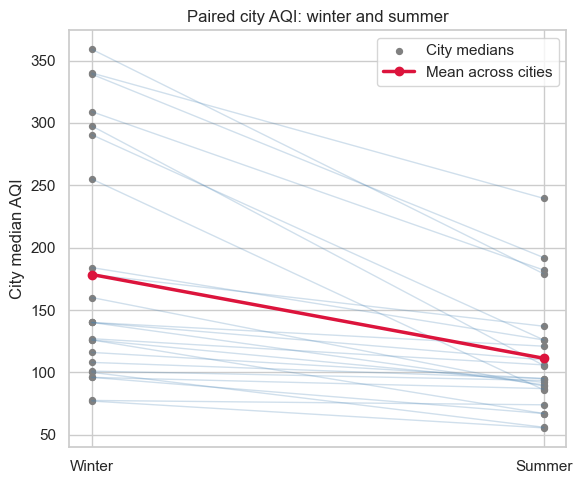

In [64]:
season_pair = df[df['City'] != 'Ahmedabad'].groupby(['City', 'Season'])['AQI'].agg(['median', 'count']).unstack('Season')
season_pair = season_pair.dropna(subset=[('median', 'Winter'), ('median', 'Summer')])
season_pair = season_pair[(season_pair[('count', 'Winter')] >= 30) & (season_pair[('count', 'Summer')] >= 30)]
winter = season_pair[('median', 'Winter')]; summer = season_pair[('median', 'Summer')]
season_diff = winter - summer
season_test = stats.ttest_rel(winter, summer)
season_ci = stats.t.interval(0.95, len(season_diff)-1, loc=season_diff.mean(), scale=stats.sem(season_diff))
print(f'Cities: {len(season_diff)} | mean winter - summer difference: {season_diff.mean():.1f} | 95% CI: ({season_ci[0]:.1f}, {season_ci[1]:.1f})')
print(f'Paired t-test: t({len(season_diff)-1}) = {season_test.statistic:.3f}, p = {season_test.pvalue:.6g}')
fig, ax = plt.subplots(figsize=(6, 5))
for city in season_diff.index: ax.plot([0, 1], [winter.loc[city], summer.loc[city]], color='steelblue', alpha=0.25, linewidth=1)
ax.scatter([0]*len(winter), winter, color='gray', s=18, label='City medians')
ax.scatter([1]*len(summer), summer, color='gray', s=18)
ax.plot([0, 1], [winter.mean(), summer.mean()], color='crimson', marker='o', linewidth=2.5, label='Mean across cities')
ax.set_xticks([0, 1], ['Winter', 'Summer']); ax.set_ylabel('City median AQI'); ax.set_title('Paired city AQI: winter and summer'); ax.legend()
plt.tight_layout(); plt.show()


## Q18. Does Linear Regression predict next-day AQI better than persistence?

**Analysis and evidence:** On the 2020 holdout, Linear Regression has MAE 22.363, RMSE 37.359, and R^2 0.801; persistence has MAE 19.348, RMSE 41.138, and R^2 0.758. Linear Regression improves RMSE and R^2 but has higher MAE. Its MAPE is 22.62%, versus 15.74% for persistence.

**Decision:** The required Linear Regression is a useful comparison, but it does not beat "tomorrow = today" on MAE. Report the mixed result and do not claim it is uniformly superior. The gains do not establish performance for future years; the holdout covers only 2020 through July 1.

## Q19. Where does the Linear Regression make its largest errors, and does it systematically over- or underpredict?

**Analysis and evidence:** On the 2020 holdout, the mean signed error (actual minus prediction) is about -8.4 AQI points, indicating slight overall overprediction on average. Error varies substantially by city: Ahmedabad has the highest city MAE (about 88.6 across 172 days), consistent with the unresolved AQI/CO anomaly; Lucknow is next (about 38.3 across 183 days). Error also grows in the sparsely represented high-AQI bands: MAE is about 148.6 for AQI 400-500 (21 days), 221.7 for 500-1000 (14 days), and 394.4 above 1000 (3 days). Mean residuals are positive in the 200-400 bands, negative in the 400-500 band, then positive above 500; this suggests underprediction in the sparsest extreme bands, but the direction is not consistent across every high band. The city MAE and AQI-band charts/tables in Part 4 show these patterns.

**Decision:** The model's errors are not uniform. Extreme-AQI error estimates are based on very few observations, and Ahmedabad's anomaly strongly affects the city comparison, so these results are diagnostic cautions rather than stable claims about future performance.


In [ ]:
# Holm correction controls family-wise error across the three selected hypotheses.
raw_p = np.array([winter_monsoon.pvalue, lockdown_test.pvalue, di_test.pvalue])
order = np.argsort(raw_p); m = len(raw_p)
holm_sorted = np.maximum.accumulate((m - np.arange(m)) * raw_p[order])
holm_p = np.empty(m); holm_p[order] = np.minimum(holm_sorted, 1.0)
print(f'Holm-adjusted p-values (season, lockdown, Diwali): {holm_p[0]:.6g}, {holm_p[1]:.6g}, {holm_p[2]:.6g}')


# Final conclusion

This case study documents the complete path from raw CPCB-related files through cleaning, exploratory analysis, 19 focused data questions, statistical evidence, a time-aware regression exercise, and BI-ready fact/dimension tables. The evidence supports strong seasonal and geographic differences, an important Ahmedabad CO anomaly, substantial station-level variability, and persistence in daily AQI. The lockdown comparison is suggestive but not causal. Model results must be judged against the persistence baseline and interpreted with the short, partial 2020 holdout, skewed target, unequal coverage, imputed fields in exploratory work, and station/city aggregation limits in mind.